# **Imports & reproducibility**

In [ ]:
import os
import random
import shutil
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("Python environment ready")
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python environment ready
pandas: 2.2.3
NumPy: 2.1.3


# **Connect Google Drive & set paths**

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_DIR = Path("/content/drive/MyDrive/Image_tagging")
CSV_DIR = DRIVE_DIR
RAR_PATH = DRIVE_DIR / "NUS_WIDE.rar"
DATA_DIR = Path("/content/datasets/NUS_WIDE")
PREFIX = "nuswide_top30_60k5k10k_stratified_"
SPLITS = {"train": 60000, "validation": 5000, "test": 10000}
CSV_PATHS = {s: CSV_DIR / f"{PREFIX}{s}.csv" for s in SPLITS}

assert DRIVE_DIR.is_dir(), f"Google Drive folder not found: {DRIVE_DIR}"
for split, path in CSV_PATHS.items():
    assert path.is_file(), f"Missing CSV ({split}): {path}"
print("CSV files found:")
for split, path in CSV_PATHS.items():
    print(split, "->", path.name)
print("RAR exists:", RAR_PATH.is_file())
print("Image directory exists:", DATA_DIR.is_dir())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CSV files found:
train -> nuswide_top30_60k5k10k_stratified_train.csv
validation -> nuswide_top30_60k5k10k_stratified_validation.csv
test -> nuswide_top30_60k5k10k_stratified_test.csv
RAR exists: True
Image directory exists: True


# **Prepare image folders (idempotent)**

In [ ]:
!command -v unrar || (apt-get update -qq && apt-get install -y unrar)
!unrar | head -n 2

/usr/bin/unrar

UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


In [ ]:
# ==========================================
# PREPARE IMAGE FOLDERS (IDEMPOTENT)
# ==========================================

from pathlib import Path
from PIL import Image
import subprocess
import shutil

DATA_ROOT = Path("/content/datasets/NUS_WIDE")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

EXPECTED_COUNTS = {
    "train": 60000,
    "validation": 5000,
    "test": 10000
}

def count_images():
    return {
        split: sum(
            1 for p in (DATA_ROOT / split).rglob("*")
            if p.is_file() and p.suffix.lower() in
            {".jpg", ".jpeg", ".png"}
        )
        for split in EXPECTED_COUNTS
    }

counts = count_images()
print("Image counts before extraction:", counts)

# Extract only when image counts are incomplete
if counts != EXPECTED_COUNTS:

    print("Dataset incomplete. Extracting with unrar...")

    if shutil.which("unrar") is None:
        raise RuntimeError(
            "unrar is not installed. Install it before extraction."
        )

    result = subprocess.run(
        [
            "unrar", "x", "-o+",
            str(RAR_PATH),
            str(DATA_ROOT) + "/"
        ],
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        raise RuntimeError(
            "Extraction failed:\n" +
            (result.stdout + result.stderr)[-2000:]
        )

    print("Extraction completed successfully.")

else:
    print("All image files already exist. Skipping extraction.")

# Final count check
counts = count_images()

print("\n===== FINAL IMAGE COUNTS =====")
for split, count in counts.items():
    print(f"{split}: {count:,} images")

assert counts == EXPECTED_COUNTS, (
    "Image counts do not match expected dataset sizes!"
)

print("\nSUCCESS: All 75,000 image files found!")

Image counts before extraction: {'train': 60000, 'validation': 5000, 'test': 10000}
All image files already exist. Skipping extraction.

===== FINAL IMAGE COUNTS =====
train: 60,000 images
validation: 5,000 images
test: 10,000 images

SUCCESS: All 75,000 image files found!


In [ ]:

# ==========================================
# VERIFY ALL EXTRACTED IMAGES
# ==========================================

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

DATA_ROOT = Path("/content/datasets/NUS_WIDE")

expected_counts = {
    "train": 60000,
    "validation": 5000,
    "test": 10000
}

corrupted_images = []

for split, expected in expected_counts.items():

    folder = DATA_ROOT / split
    image_paths = sorted(folder.rglob("*.jpg"))

    print(f"\n===== {split.upper()} =====")
    print("Found:", len(image_paths))
    print("Expected:", expected)

    assert len(image_paths) == expected, (
        f"Incorrect image count in {split}"
    )

    for path in tqdm(image_paths, desc=f"Checking {split}"):

        try:
            with Image.open(path) as img:
                img.verify()

            # Verify that pixel data can actually be decoded
            with Image.open(path) as img:
                img.load()

        except Exception as e:
            corrupted_images.append((str(path), str(e)))

print("\n===== FINAL INTEGRITY RESULT =====")
print("Total images checked:", sum(expected_counts.values()))
print("Corrupted images:", len(corrupted_images))

if corrupted_images:
    print("\nFirst 20 corrupted files:")
    for path, error in corrupted_images[:20]:
        print(path, "->", error)
else:
    print("SUCCESS: All 75,000 images passed verification!")



===== TRAIN =====
Found: 60000
Expected: 60000


Checking train:   0%|          | 0/60000 [00:00<?, ?it/s]


===== VALIDATION =====
Found: 5000
Expected: 5000


Checking validation:   0%|          | 0/5000 [00:00<?, ?it/s]


===== TEST =====
Found: 10000
Expected: 10000


Checking test:   0%|          | 0/10000 [00:00<?, ?it/s]


===== FINAL INTEGRITY RESULT =====
Total images checked: 75000
Corrupted images: 0
SUCCESS: All 75,000 images passed verification!


# **Load original CSV splits & define exact label order**

In [ ]:
train_df = pd.read_csv(CSV_PATHS["train"])
val_df = pd.read_csv(CSV_PATHS["validation"])
test_df = pd.read_csv(CSV_PATHS["test"])

LABEL_COLUMNS = [
    "sky", "clouds", "person", "water", "animal", "grass", "buildings",
    "window", "plants", "lake", "ocean", "road", "flowers", "sunset",
    "reflection", "rocks", "vehicle", "snow", "tree", "beach", "mountain",
    "boats", "nighttime", "house", "valley", "birds", "sun", "military",
    "garden", "toy"
]

datasets = {"train": train_df, "validation": val_df, "test": test_df}
for split, df in datasets.items():
    assert list(df.columns[1:31]) == LABEL_COLUMNS, f"Incorrect label order in {split}"
    print(f"{split}: {df.shape}")
print("Labels:", LABEL_COLUMNS)
display(train_df.head(3))

train: (60000, 33)
validation: (5000, 33)
test: (10000, 33)
Labels: ['sky', 'clouds', 'person', 'water', 'animal', 'grass', 'buildings', 'window', 'plants', 'lake', 'ocean', 'road', 'flowers', 'sunset', 'reflection', 'rocks', 'vehicle', 'snow', 'tree', 'beach', 'mountain', 'boats', 'nighttime', 'house', 'valley', 'birds', 'sun', 'military', 'garden', 'toy']


,image,sky,clouds,person,water,animal,grass,buildings,window,plants,...,nighttime,house,valley,birds,sun,military,garden,toy,_matched_top30_count,_matched_top30_labels
0,canoe\0435_2614631664.jpg,0,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,4,clouds|person|water|lake
1,throwing\0523_516408436.jpg,0,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,4,clouds|person|water|lake
2,costume\0343_131800162.jpg,0,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,4,clouds|person|water|lake


# **Resolve flat-directory image paths**

In [ ]:
def resolve_image_path(image_name, split):
    if split not in SPLITS:
        raise ValueError(f"Unknown split: {split}")
    normalized = str(image_name).replace("\\", "/")
    filename = Path(normalized).name
    return DATA_DIR / split / filename

sample_name = train_df.iloc[0]["image"]
sample_path = resolve_image_path(sample_name, "train")
print("CSV filename:", sample_name)
print("Resolved path:", sample_path)
print("Exists:", sample_path.is_file())
assert sample_path.is_file(), "Sample image missing"

CSV filename: canoe\0435_2614631664.jpg
Resolved path: /content/datasets/NUS_WIDE/train/0435_2614631664.jpg
Exists: True


# **Data integrity check**

In [ ]:
for split, df in datasets.items():
    missing = int(df[["image"] + LABEL_COLUMNS].isna().sum().sum())
    invalid = int((~df[LABEL_COLUMNS].isin([0, 1])).sum().sum())
    dup = int(df["image"].duplicated().sum())
    avg = float(df[LABEL_COLUMNS].sum(axis=1).mean())
    zero = int((df[LABEL_COLUMNS].sum(axis=1) == 0).sum())
    print(f"\n===== {split.upper()} =====")
    print("Shape:", df.shape, "Missing:", missing,
          "Invalid labels:", invalid, "Duplicates:", dup)
    print("Avg labels/image:", round(avg, 3), "Zero-label images:", zero)
    assert len(df) == SPLITS[split], "Unexpected split size"
    assert df.shape[1] == 33, "Unexpected number of CSV columns"
    assert missing == invalid == dup == 0, "Data integrity failed"

images_by_split = {s: set(df["image"].astype(str).str.replace("\\", "/", regex=False)
                                 .str.rsplit("/", n=1).str[-1])
                   for s, df in datasets.items()}
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    overlap = len(images_by_split[a] & images_by_split[b])
    print(f"{a} vs {b} filename overlap:", overlap)
    assert overlap == 0, "Split leakage detected"
print("\nSUCCESS: DATA INTEGRITY CHECK PASSED")


===== TRAIN =====
Shape: (60000, 33) Missing: 0 Invalid labels: 0 Duplicates: 0
Avg labels/image: 2.211 Zero-label images: 0

===== VALIDATION =====
Shape: (5000, 33) Missing: 0 Invalid labels: 0 Duplicates: 0
Avg labels/image: 2.266 Zero-label images: 0

===== TEST =====
Shape: (10000, 33) Missing: 0 Invalid labels: 0 Duplicates: 0
Avg labels/image: 2.183 Zero-label images: 0
train vs validation filename overlap: 0
train vs test filename overlap: 0
validation vs test filename overlap: 0

SUCCESS: DATA INTEGRITY CHECK PASSED


# **Verify every CSV image path**

In [ ]:
for split, df in datasets.items():
    missing_names = [name for name in df["image"]
                     if not resolve_image_path(name, split).is_file()]
    matched = len(df) - len(missing_names)
    print(f"{split}: {matched:,}/{len(df):,} matched; missing={len(missing_names)}")
    assert not missing_names, f"Missing example(s): {missing_names[:5]}"
print("SUCCESS: All 75,000 CSV image paths matched")

train: 60,000/60,000 matched; missing=0
validation: 5,000/5,000 matched; missing=0
test: 10,000/10,000 matched; missing=0
SUCCESS: All 75,000 CSV image paths matched


# **Visualize sample images and ground-truth tags**

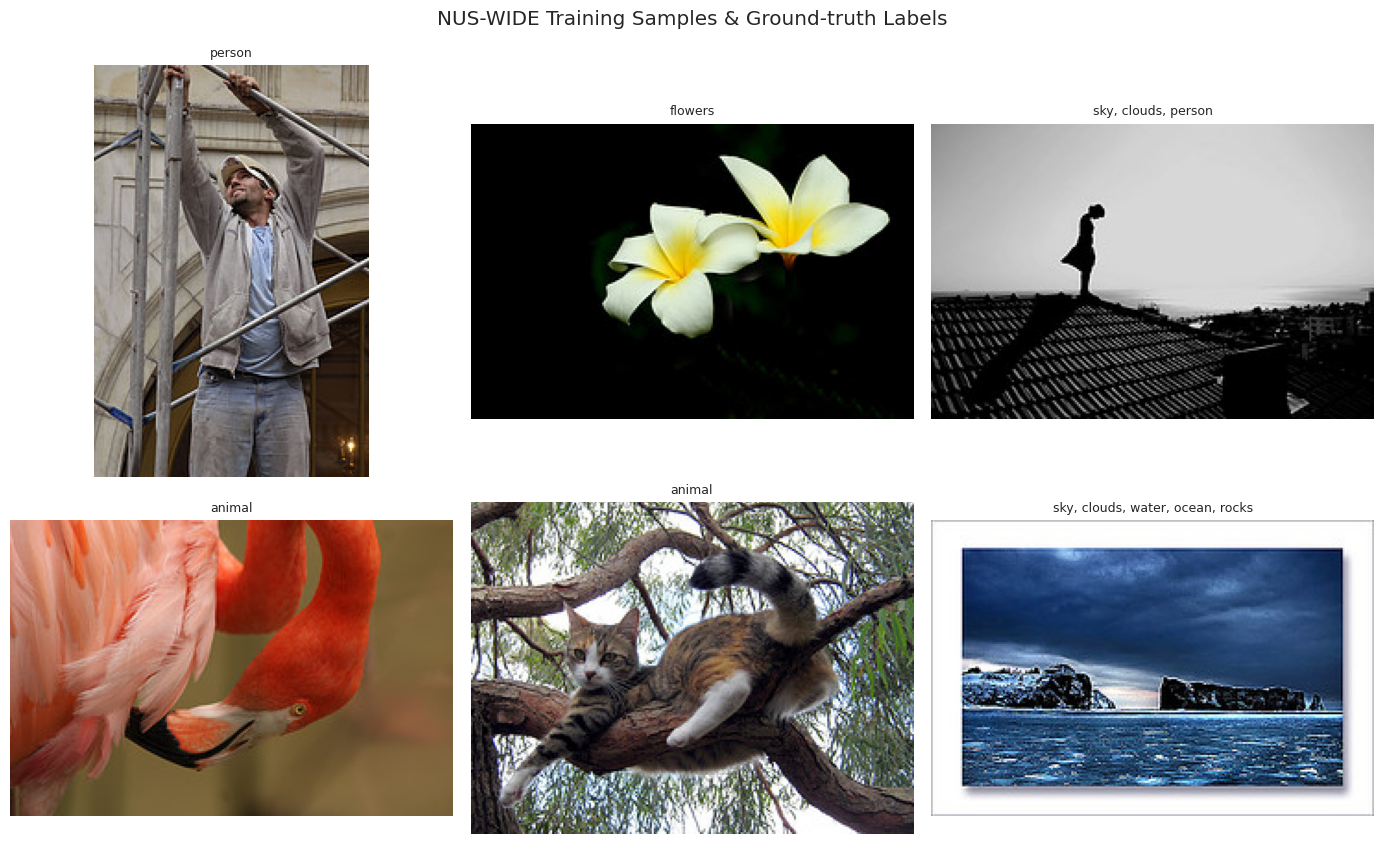

In [ ]:
sample_rows = train_df.sample(n=6, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, (_, row) in zip(axes.flat, sample_rows.iterrows()):
    path = resolve_image_path(row["image"], "train")
    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))
    labels = [c for c in LABEL_COLUMNS if row[c] == 1]
    ax.set_title(", ".join(labels), fontsize=9, wrap=True)
    ax.axis("off")
plt.suptitle("NUS-WIDE Training Samples & Ground-truth Labels")
plt.tight_layout()
plt.show()

# **EDA — Label distribution**

,Count,Percentage (%)
sky,22302,37.17
clouds,16239,27.06
person,15494,25.82
water,10569,17.61
animal,10186,16.98
grass,6755,11.26
buildings,5328,8.88
window,4519,7.53
plants,4281,7.14
lake,3977,6.63


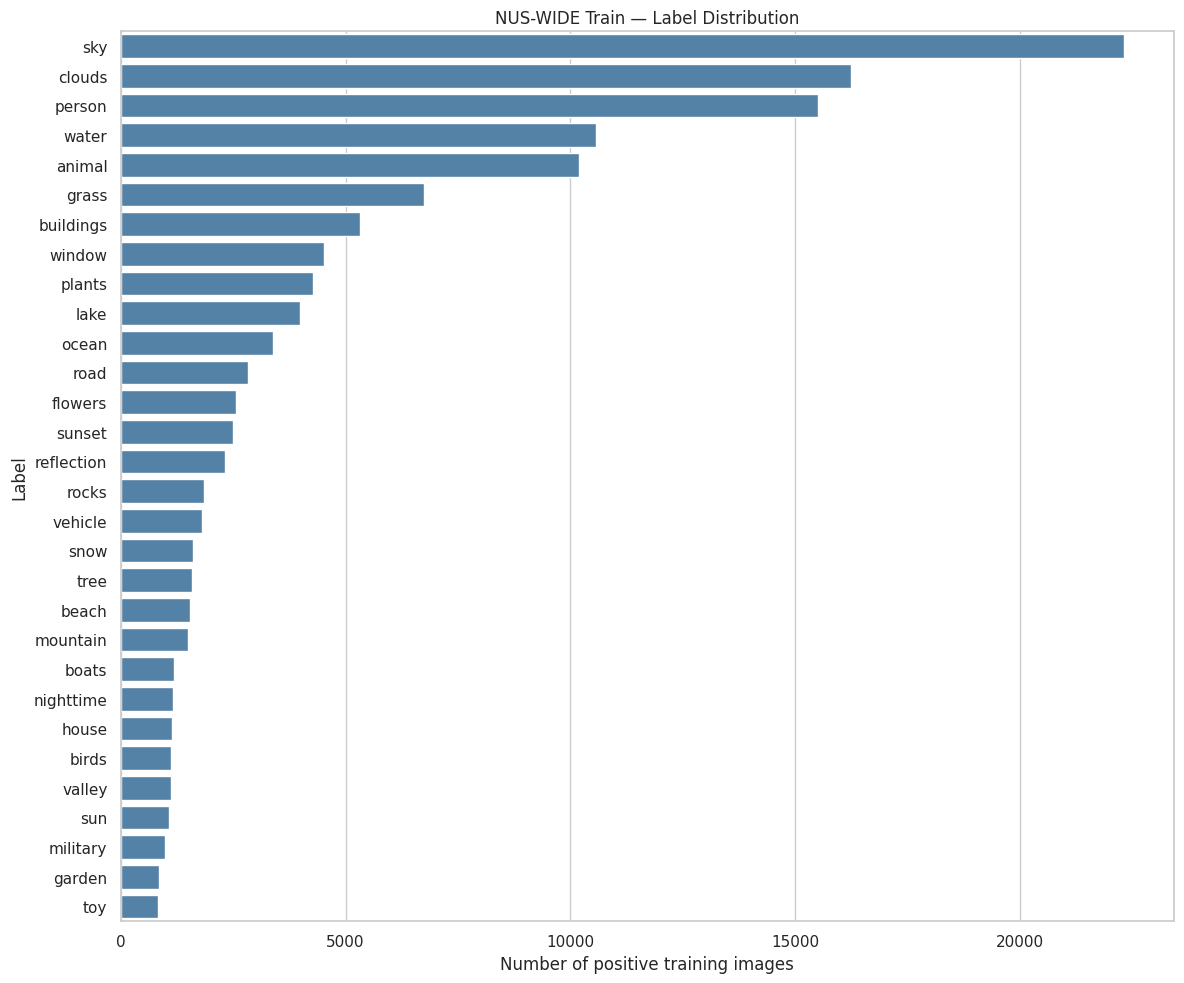

In [ ]:
label_counts = train_df[LABEL_COLUMNS].sum().sort_values(ascending=False)
label_pct = label_counts / len(train_df) * 100
label_summary = pd.DataFrame({"Count": label_counts.astype(int),
                              "Percentage (%)": label_pct.round(2)})
display(label_summary)
plt.figure(figsize=(12, 10))
sns.barplot(x=label_counts.values, y=label_counts.index, color="steelblue")
plt.xlabel("Number of positive training images")
plt.ylabel("Label")
plt.title("NUS-WIDE Train — Label Distribution")
plt.tight_layout()
plt.show()

# **EDA — Class imbalance**

Most frequent: sky 22302
Least frequent: toy 834
Imbalance ratio: 26.74x


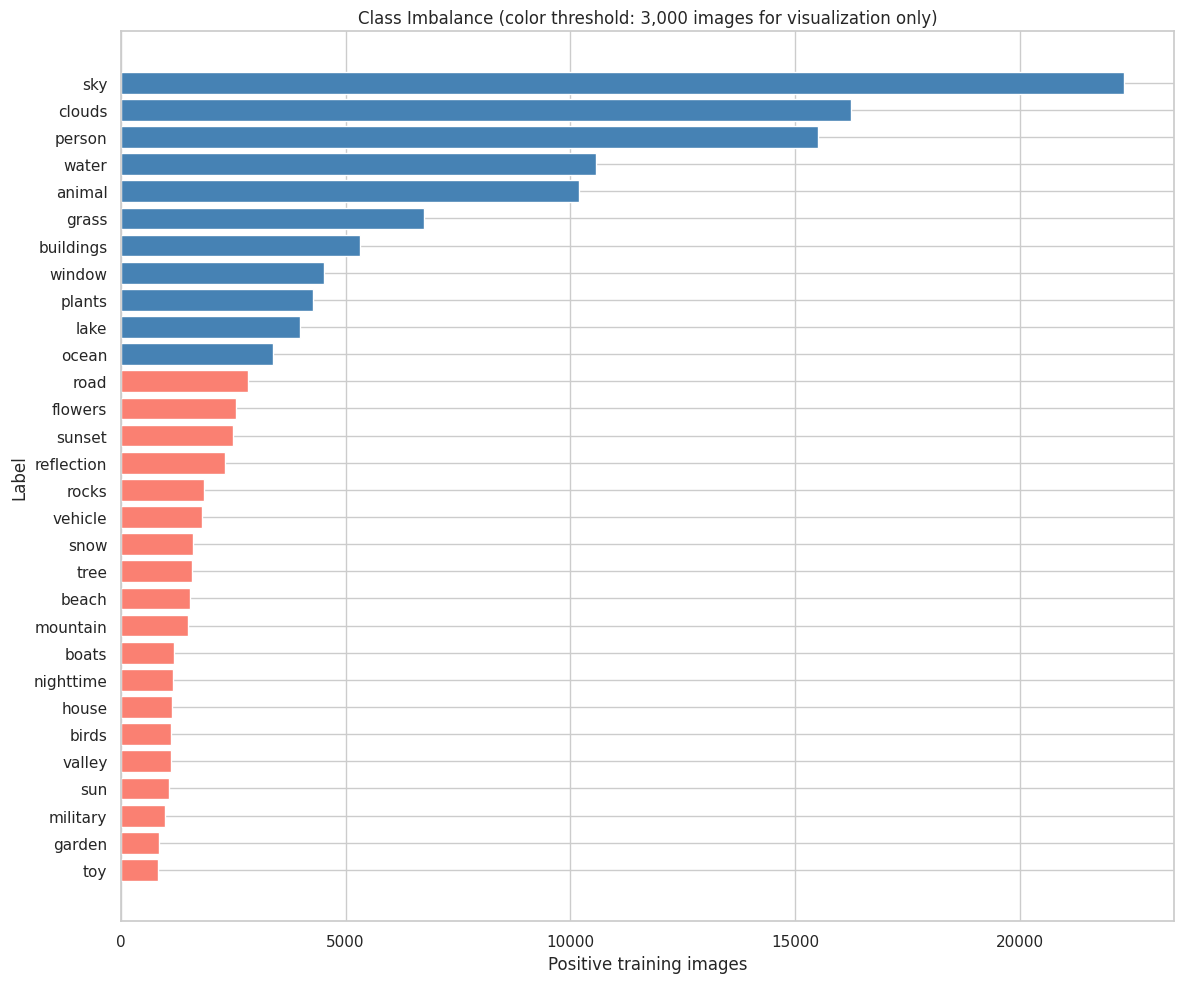

In [ ]:
assert int(label_counts.min()) > 0, "At least one label has zero positives"
imbalance_ratio = label_counts.max() / label_counts.min()
print("Most frequent:", label_counts.idxmax(), int(label_counts.max()))
print("Least frequent:", label_counts.idxmin(), int(label_counts.min()))
print(f"Imbalance ratio: {imbalance_ratio:.2f}x")
fig, ax = plt.subplots(figsize=(12, 10))
colors = ["steelblue" if x >= 3000 else "salmon" for x in label_counts]
ax.barh(label_counts.index, label_counts.values, color=colors)
ax.invert_yaxis()
ax.set(xlabel="Positive training images", ylabel="Label",
       title="Class Imbalance (color threshold: 3,000 images for visualization only)")
plt.tight_layout()
plt.show()

# **EDA — Labels per image**

Summary:


,mean,median,min,max
train,2.211,2.0,1.0,11.0
validation,2.266,2.0,1.0,10.0
test,2.183,2.0,1.0,10.0


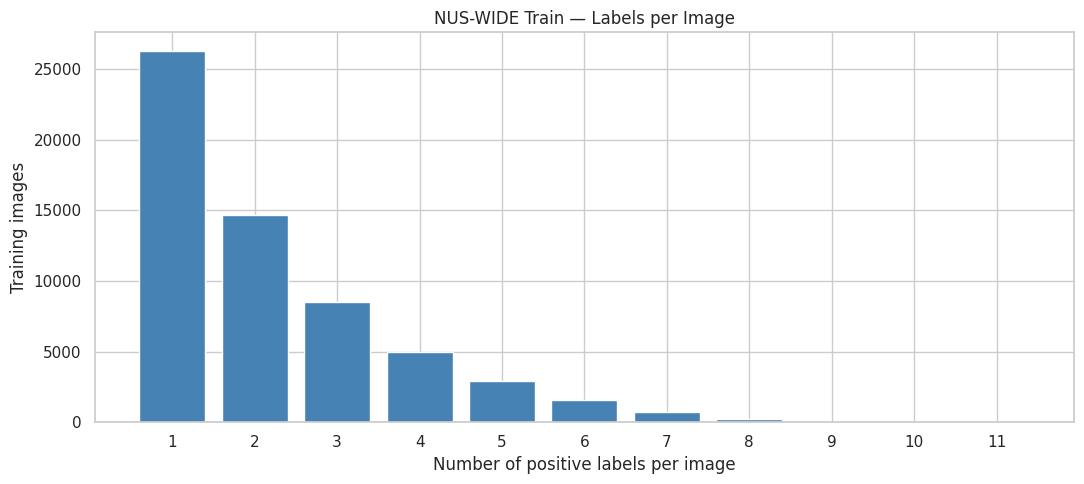

In [ ]:
label_count_series = {split: df[LABEL_COLUMNS].sum(axis=1).astype(int)
                      for split, df in datasets.items()}
summary = pd.DataFrame({s: {"mean": x.mean(), "median": x.median(),
                            "min": x.min(), "max": x.max()}
                        for s, x in label_count_series.items()}).T
print("Summary:")
display(summary.round(3))
fig, ax = plt.subplots(figsize=(11, 5))
counts = label_count_series["train"].value_counts().sort_index()
ax.bar(counts.index, counts.values, color="steelblue")
ax.set(xlabel="Number of positive labels per image", ylabel="Training images",
       title="NUS-WIDE Train — Labels per Image")
ax.set_xticks(counts.index)
plt.tight_layout()
plt.show()

# **EDA — Label co-occurrence**

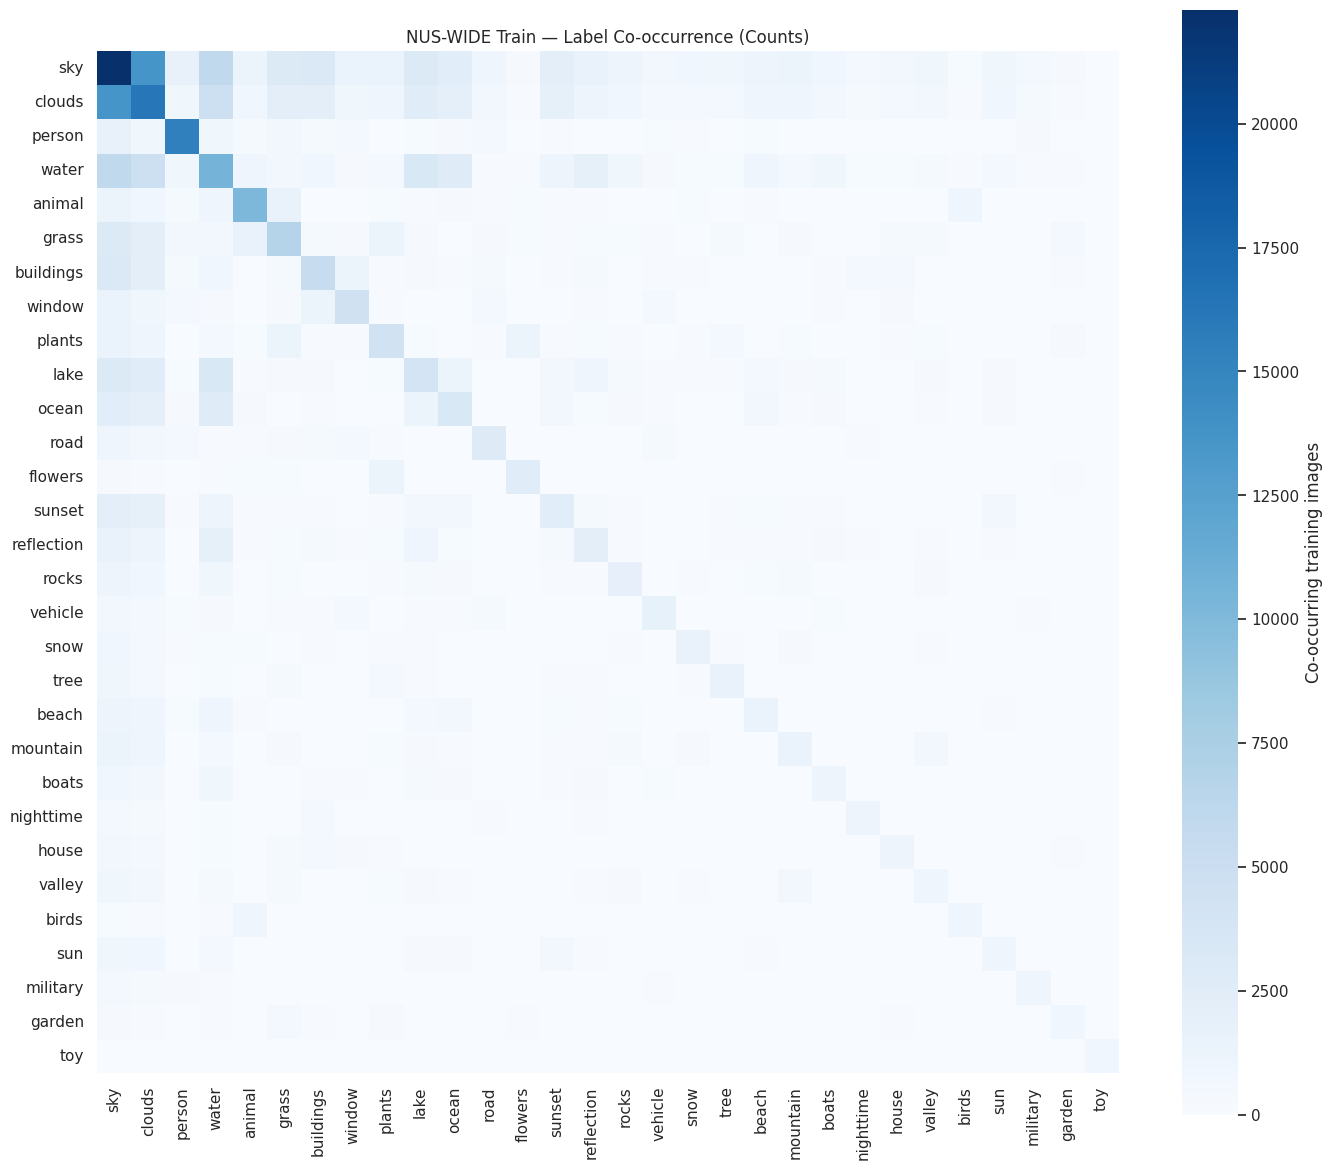

Top 10 co-occurring label pairs:


,Label A,Label B,Co-occurrence
0,sky,clouds,13637
1,sky,water,5949
2,clouds,water,4712
3,water,lake,3373
4,sky,buildings,3174
5,sky,lake,3043
6,sky,grass,2979
7,water,ocean,2769
8,clouds,lake,2528
9,sky,ocean,2452


In [ ]:
Y_train = train_df[LABEL_COLUMNS].to_numpy(dtype=np.int64)
cooccurrence = Y_train.T @ Y_train
cooccurrence_df = pd.DataFrame(cooccurrence, index=LABEL_COLUMNS, columns=LABEL_COLUMNS)
plt.figure(figsize=(14, 12))
sns.heatmap(cooccurrence_df, cmap="Blues", square=True,
            cbar_kws={"label": "Co-occurring training images"})
plt.title("NUS-WIDE Train — Label Co-occurrence (Counts)")
plt.tight_layout()
plt.show()

pairs = []
for i in range(len(LABEL_COLUMNS)):
    for j in range(i + 1, len(LABEL_COLUMNS)):
        pairs.append((LABEL_COLUMNS[i], LABEL_COLUMNS[j], int(cooccurrence[i, j])))
top_pairs = pd.DataFrame(pairs, columns=["Label A", "Label B", "Co-occurrence"])
print("Top 10 co-occurring label pairs:")
display(top_pairs.sort_values("Co-occurrence", ascending=False).head(10).reset_index(drop=True))

# **Feature Extraction**

## Step 1: Environment and Dataset Readiness Check

In [ ]:
# ==================================================
# PHASE 2 - STEP 1: ENVIRONMENT READINESS CHECK
# ==================================================

import os
import torch
import numpy as np
import pandas as pd
import sklearn
import torchvision

from pathlib import Path

print("===== SYSTEM INFORMATION =====")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\n===== GPU INFORMATION =====")

if torch.cuda.is_available():
    print("GPU available: YES")
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print("GPU available: NO")
    print("Using CPU")

print("\n===== DATASET INFORMATION =====")

datasets = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

for name, df in datasets.items():
    print(f"{name}: {len(df):,} images")

print("\nNumber of labels:", len(LABEL_COLUMNS))

print("\n===== IMAGE PATH CHECK =====")

for split in ["train", "validation", "test"]:

    folder = Path("/content/datasets/NUS_WIDE") / split

    print(
        f"{split}:",
        "FOUND" if folder.exists() else "NOT FOUND"
    )

print("\n===== STORAGE INFORMATION =====")

import shutil

disk = shutil.disk_usage("/content")

print("Free disk space (GB):",
      round(disk.free / 1024**3, 2))

print("\n===== READY FOR FEATURE EXTRACTION =====")

===== SYSTEM INFORMATION =====
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Scikit-learn version: 1.6.1

===== GPU INFORMATION =====
GPU available: YES
GPU name: Tesla T4
GPU memory (GB): 14.56

===== DATASET INFORMATION =====
Train: 60,000 images
Validation: 5,000 images
Test: 10,000 images

Number of labels: 30

===== IMAGE PATH CHECK =====
train: FOUND
validation: FOUND
test: FOUND

===== STORAGE INFORMATION =====
Free disk space (GB): 66.85

===== READY FOR FEATURE EXTRACTION =====


## Step 2: HOG Feature Extraction — Single Image Test

Image path: /content/datasets/NUS_WIDE/train/0435_2614631664.jpg

===== HOG FEATURE INFORMATION =====
Original image size: (240, 180)
Processed image size: (128, 128)
Feature vector shape: (8100,)
Feature count: 8100
Contains NaN: False
Contains Inf: False


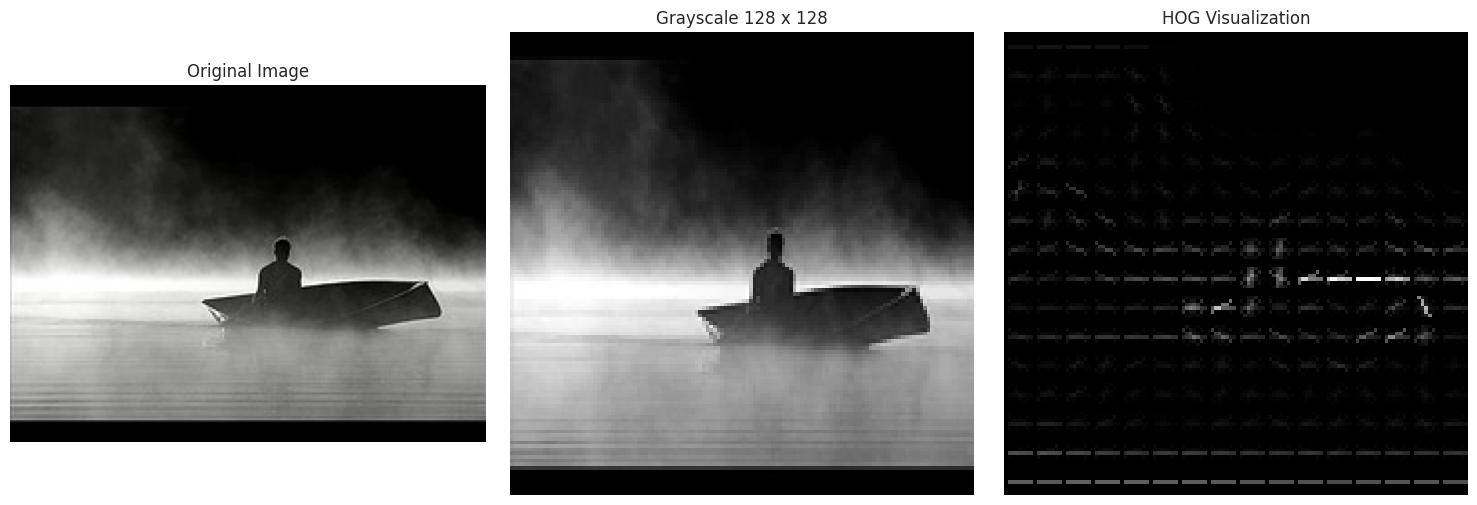


SUCCESS: HOG extraction test passed!


In [ ]:
# ==========================================
# PHASE 2 - STEP 2
# HOG FEATURE EXTRACTION: SINGLE IMAGE
# ==========================================

from pathlib import Path
from PIL import Image
from skimage.feature import hog
import numpy as np
import matplotlib.pyplot as plt

# Select one training image
image_name = Path(
    str(train_df.iloc[0]["image"]).replace("\\", "/")
).name

image_path = Path(
    "/content/datasets/NUS_WIDE/train"
) / image_name

print("Image path:", image_path)

assert image_path.exists(), "Image not found!"

# Load original image
with Image.open(image_path) as img:
    image = img.convert("RGB").copy()

# Convert to grayscale and resize
gray_image = image.convert("L").resize((128, 128))
gray_array = np.asarray(gray_image)

# Extract HOG features
hog_features, hog_visualization = hog(
    gray_array,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True,
    feature_vector=True
)

print("\n===== HOG FEATURE INFORMATION =====")
print("Original image size:", image.size)
print("Processed image size:", gray_array.shape)
print("Feature vector shape:", hog_features.shape)
print("Feature count:", len(hog_features))
print("Contains NaN:", np.isnan(hog_features).any())
print("Contains Inf:", np.isinf(hog_features).any())

assert hog_features.shape == (8100,)
assert np.isfinite(hog_features).all()

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")

axes[1].imshow(gray_array, cmap="gray")
axes[1].set_title("Grayscale 128 x 128")

axes[2].imshow(hog_visualization, cmap="gray")
axes[2].set_title("HOG Visualization")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("\nSUCCESS: HOG extraction test passed!")

## Step 3: HOG Batch Extraction — 100 Image Test

In [ ]:
# ==========================================
# PHASE 2 - STEP 3
# HOG BATCH EXTRACTION: 100 IMAGE TEST
# ==========================================

from pathlib import Path
from PIL import Image
from skimage.feature import hog
from tqdm.auto import tqdm
import numpy as np
import time

DATA_ROOT = Path("/content/datasets/NUS_WIDE")

def extract_hog_features(image_path):
    """
    Extract 8100-dimensional HOG features from one image.
    """

    with Image.open(image_path) as img:
        gray = img.convert("L").resize((128, 128))
        gray_array = np.asarray(gray)

    features = hog(
        gray_array,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        visualize=False,
        feature_vector=True
    )

    return features.astype(np.float32)


def extract_hog_batch(df, split, limit=None):
    """
    Extract HOG features in original CSV order.
    """

    if limit is not None:
        df = df.iloc[:limit]

    feature_list = []

    start_time = time.time()

    for image_name in tqdm(
        df["image"],
        total=len(df),
        desc=f"HOG {split}"
    ):

        filename = Path(
            str(image_name).replace("\\", "/")
        ).name

        image_path = DATA_ROOT / split / filename

        if not image_path.is_file():
            raise FileNotFoundError(image_path)

        features = extract_hog_features(image_path)
        feature_list.append(features)

    X = np.stack(feature_list)

    elapsed = time.time() - start_time

    return X, elapsed


# Test only the first 100 training images
X_hog_sample, elapsed = extract_hog_batch(
    train_df,
    split="train",
    limit=100
)

print("\n===== HOG BATCH TEST =====")
print("Feature matrix shape:", X_hog_sample.shape)
print("Data type:", X_hog_sample.dtype)
print("NaN/Inf:", not np.isfinite(X_hog_sample).all())
print("Processing time (seconds):", round(elapsed, 2))
print("Average time per image:", round(elapsed / 100, 4))

assert X_hog_sample.shape == (100, 8100)
assert np.isfinite(X_hog_sample).all()

print("\nSUCCESS: HOG batch extraction passed!")

HOG train:   0%|          | 0/100 [00:00<?, ?it/s]


===== HOG BATCH TEST =====
Feature matrix shape: (100, 8100)
Data type: float32
NaN/Inf: False
Processing time (seconds): 0.79
Average time per image: 0.0079

SUCCESS: HOG batch extraction passed!


## Step 4: Full HOG Extraction and Feature Caching

In [ ]:
# ==================================================
# PHASE 2 - STEP 4
# FULL HOG EXTRACTION WITH FEATURE CACHING
# ==================================================

from pathlib import Path
import numpy as np
import json
import time

FEATURE_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/features/hog"
)

FEATURE_DIR.mkdir(parents=True, exist_ok=True)

datasets = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

expected_shapes = {
    "train": (60000, 8100),
    "validation": (5000, 8100),
    "test": (10000, 8100)
}

hog_features = {}

for split, df in datasets.items():

    feature_path = FEATURE_DIR / f"hog_{split}.npy"

    print(f"\n===== HOG {split.upper()} =====")

    if feature_path.exists():

        print("Cached feature file found.")
        print("Checking existing features...")

        X = np.load(feature_path, mmap_mode="r")

        if (
            X.shape == expected_shapes[split]
            and X.dtype == np.float32
        ):
            print("Valid cache. Skipping extraction.")
            hog_features[split] = X
            continue

        else:
            raise ValueError(
                f"Invalid cached features: {feature_path}"
            )

    print("Extracting features...")

    X, elapsed = extract_hog_batch(
        df,
        split=split
    )

    assert X.shape == expected_shapes[split]
    assert np.isfinite(X).all()

    print("Saving features to Google Drive...")

    np.save(feature_path, X)

    hog_features[split] = X

    print("Saved:", feature_path)
    print("Shape:", X.shape)
    print("Time (minutes):", round(elapsed / 60, 2))

print("\n===== FINAL HOG FEATURES =====")

for split, X in hog_features.items():
    print(split, X.shape, X.dtype)

print("\nSUCCESS: HOG feature extraction completed!")


===== HOG TRAIN =====
Extracting features...


HOG train:   0%|          | 0/60000 [00:00<?, ?it/s]

Saving features to Google Drive...
Saved: /content/drive/MyDrive/Image_tagging/features/hog/hog_train.npy
Shape: (60000, 8100)
Time (minutes): 7.57

===== HOG VALIDATION =====
Extracting features...


HOG validation:   0%|          | 0/5000 [00:00<?, ?it/s]

Saving features to Google Drive...
Saved: /content/drive/MyDrive/Image_tagging/features/hog/hog_validation.npy
Shape: (5000, 8100)
Time (minutes): 0.68

===== HOG TEST =====
Extracting features...


HOG test:   0%|          | 0/10000 [00:00<?, ?it/s]

Saving features to Google Drive...
Saved: /content/drive/MyDrive/Image_tagging/features/hog/hog_test.npy
Shape: (10000, 8100)
Time (minutes): 1.34

===== FINAL HOG FEATURES =====
train (60000, 8100) float32
validation (5000, 8100) float32
test (10000, 8100) float32

SUCCESS: HOG feature extraction completed!


## Step 5: Verify Saved HOG Features

In [ ]:
# ==========================================
# PHASE 2 - STEP 5
# VERIFY SAVED HOG FEATURES
# ==========================================

import numpy as np
import hashlib
import json
from pathlib import Path

FEATURE_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/features/hog"
)

datasets = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

expected_shapes = {
    "train": (60000, 8100),
    "validation": (5000, 8100),
    "test": (10000, 8100)
}

metadata = {
    "feature_type": "HOG",
    "image_size": [128, 128],
    "orientations": 9,
    "pixels_per_cell": [8, 8],
    "cells_per_block": [2, 2],
    "block_norm": "L2-Hys",
    "dtype": "float32",
    "splits": {}
}

for split, df in datasets.items():

    feature_path = FEATURE_DIR / f"hog_{split}.npy"

    print(f"\n===== VERIFY {split.upper()} =====")

    assert feature_path.exists(), (
        f"Feature file missing: {feature_path}"
    )

    X = np.load(feature_path, mmap_mode="r")

    assert X.shape == expected_shapes[split]
    assert X.dtype == np.float32

    # Check values in memory-efficient chunks
    for start in range(0, len(X), 1000):
        assert np.isfinite(X[start:start + 1000]).all(), (
            f"Invalid features in {split}, row {start}"
        )

    # Hash the CSV filename order
    filenames = [
        Path(str(p).replace("\\", "/")).name
        for p in df["image"]
    ]

    order_hash = hashlib.sha256(
        json.dumps(filenames).encode("utf-8")
    ).hexdigest()

    metadata["splits"][split] = {
        "rows": len(X),
        "dimensions": X.shape[1],
        "filename_order_sha256": order_hash
    }

    print("Shape:", X.shape)
    print("Dtype:", X.dtype)
    print("File size (GB):",
          round(feature_path.stat().st_size / 1024**3, 3))
    print("NaN/Inf: False")
    print("Filename order SHA256:", order_hash[:16], "...")

# Save metadata for future verification
metadata_path = FEATURE_DIR / "hog_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("\nMetadata saved:", metadata_path)
print("\nSUCCESS: All HOG feature files verified!")


===== VERIFY TRAIN =====
Shape: (60000, 8100)
Dtype: float32
File size (GB): 1.81
NaN/Inf: False
Filename order SHA256: a82791322bde7f35 ...

===== VERIFY VALIDATION =====
Shape: (5000, 8100)
Dtype: float32
File size (GB): 0.151
NaN/Inf: False
Filename order SHA256: 244a27d3e25a9d97 ...

===== VERIFY TEST =====
Shape: (10000, 8100)
Dtype: float32
File size (GB): 0.302
NaN/Inf: False
Filename order SHA256: 5186ff6f3544136a ...

Metadata saved: /content/drive/MyDrive/Image_tagging/features/hog/hog_metadata.json

SUCCESS: All HOG feature files verified!


## Step 6: Pretrained ResNet18 Feature Extraction — Single Image Test

===== DEVICE INFORMATION =====
Using device: cuda
GPU: Tesla T4
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 37.3MB/s]



===== MODEL INFORMATION =====
Model: ResNet18
Pretrained weights: ResNet18_Weights.IMAGENET1K_V1
Final layer: Identity()
Feature dimensions: 512

===== INPUT INFORMATION =====
Image: 0435_2614631664.jpg
Original size: (240, 180)
Input tensor shape: (1, 3, 224, 224)

===== RESNET18 FEATURES =====
Feature shape: (1, 512)
Data type: float32
Contains NaN: False
Contains Inf: False


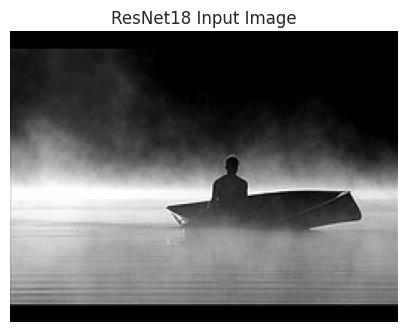


SUCCESS: ResNet18 feature extraction passed!


In [ ]:
# ==================================================
# PHASE 2 - STEP 6
# RESNET18 FEATURE EXTRACTION: SINGLE IMAGE TEST
# ==================================================

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from torchvision.models import resnet18, ResNet18_Weights

# 1. Select computing device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("===== DEVICE INFORMATION =====")
print("Using device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# 2. Load pretrained ResNet18
weights = ResNet18_Weights.DEFAULT

resnet_model = resnet18(weights=weights)

# Remove the final classification layer
resnet_model.fc = nn.Identity()

# Move model to device and enable evaluation mode
resnet_model = resnet_model.to(device)
resnet_model.eval()

print("\n===== MODEL INFORMATION =====")
print("Model: ResNet18")
print("Pretrained weights:", weights)
print("Final layer:", resnet_model.fc)
print("Feature dimensions: 512")

# 3. Define preprocessing
preprocess = weights.transforms()

# 4. Select first training image
image_name = Path(
    str(train_df.iloc[0]["image"]).replace("\\", "/")
).name

image_path = (
    Path("/content/datasets/NUS_WIDE/train")
    / image_name
)

assert image_path.is_file(), "Image not found!"

with Image.open(image_path) as img:
    image = img.convert("RGB").copy()

# 5. Convert image into model input tensor
input_tensor = preprocess(image).unsqueeze(0)
input_tensor = input_tensor.to(device)

print("\n===== INPUT INFORMATION =====")
print("Image:", image_name)
print("Original size:", image.size)
print("Input tensor shape:", tuple(input_tensor.shape))

# 6. Extract deep features without gradients
with torch.inference_mode():
    features = resnet_model(input_tensor)

# 7. Convert features to NumPy
features_np = (
    features.cpu().numpy().astype(np.float32)
)

print("\n===== RESNET18 FEATURES =====")
print("Feature shape:", features_np.shape)
print("Data type:", features_np.dtype)
print("Contains NaN:", np.isnan(features_np).any())
print("Contains Inf:", np.isinf(features_np).any())

assert features_np.shape == (1, 512)
assert np.isfinite(features_np).all()

# 8. Display original image
plt.figure(figsize=(5, 4))
plt.imshow(image)
plt.title("ResNet18 Input Image")
plt.axis("off")
plt.show()

print("\nSUCCESS: ResNet18 feature extraction passed!")

## Step 7: ResNet18 Batch Extraction — 100 Image Test

In [ ]:
# ==================================================
# PHASE 2 - STEP 7
# RESNET18 BATCH EXTRACTION: 100 IMAGE TEST
# ==================================================

import time
import numpy as np
import torch

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

DATA_ROOT = Path("/content/datasets/NUS_WIDE")

# 1. Create image dataset
class NUSWideImageDataset(Dataset):

    def __init__(self, df, split, transform):
        self.df = df.reset_index(drop=True)
        self.split = split
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        filename = Path(
            str(self.df.iloc[idx]["image"]).replace("\\", "/")
        ).name

        image_path = DATA_ROOT / self.split / filename

        with Image.open(image_path) as img:
            image = img.convert("RGB")
            image_tensor = self.transform(image)

        return image_tensor


# 2. Create DataLoader
sample_dataset = NUSWideImageDataset(
    train_df.iloc[:100],
    split="train",
    transform=preprocess
)

sample_loader = DataLoader(
    sample_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# 3. Extract features
feature_batches = []

start_time = time.time()

resnet_model.eval()

with torch.inference_mode():

    for images in tqdm(
        sample_loader,
        desc="ResNet18 Batch Test"
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        batch_features = resnet_model(images)

        feature_batches.append(
            batch_features.cpu().numpy()
        )

# 4. Combine all batches
X_resnet_sample = np.concatenate(
    feature_batches,
    axis=0
).astype(np.float32)

# Ensure GPU work has completed before timing
if device.type == "cuda":
    torch.cuda.synchronize()

elapsed = time.time() - start_time

print("\n===== RESNET18 BATCH TEST =====")
print("Feature matrix shape:", X_resnet_sample.shape)
print("Data type:", X_resnet_sample.dtype)
print("NaN/Inf:",
      not np.isfinite(X_resnet_sample).all())
print("Processing time (seconds):", round(elapsed, 2))
print("Average time per image:",
      round(elapsed / 100, 4))

assert X_resnet_sample.shape == (100, 512)
assert np.isfinite(X_resnet_sample).all()

print("\nSUCCESS: ResNet18 batch extraction passed!")

ResNet18 Batch Test:   0%|          | 0/4 [00:00<?, ?it/s]


===== RESNET18 BATCH TEST =====
Feature matrix shape: (100, 512)
Data type: float32
NaN/Inf: False
Processing time (seconds): 1.86
Average time per image: 0.0186

SUCCESS: ResNet18 batch extraction passed!


## Step 8: Full ResNet18 Feature Extraction and Caching

In [ ]:
# ==================================================
# PHASE 2 - STEP 8
# FULL RESNET18 FEATURE EXTRACTION WITH CACHING
# ==================================================

import os
import json
import time
import hashlib
import shutil
import numpy as np
import torch

from pathlib import Path
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# 1. Configuration
RESNET_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/features/resnet18"
)
RESNET_DIR.mkdir(parents=True, exist_ok=True)

TEMP_DIR = Path("/content/resnet18_feature_cache")
TEMP_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 64
NUM_WORKERS = 0
FEATURE_DIM = 512

datasets = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

expected_counts = {
    "train": 60000,
    "validation": 5000,
    "test": 10000
}

# 2. Helper: fingerprint CSV image order
def get_image_order_hash(df):
    filenames = [
        Path(str(p).replace("\\", "/")).name
        for p in df["image"]
    ]
    return hashlib.sha256(
        json.dumps(filenames).encode("utf-8")
    ).hexdigest()


# 3. Helper: verify cached feature matrix
def verify_resnet_cache(feature_path, metadata_path, df, split):

    if not feature_path.exists() or not metadata_path.exists():
        return False

    with open(metadata_path, "r", encoding="utf-8") as f:
        info = json.load(f)

    expected_info = {
        "split": split,
        "rows": len(df),
        "dimensions": FEATURE_DIM,
        "dtype": "float32",
        "model": "resnet18",
        "weights": weights.name,
        "preprocessing": repr(preprocess),
        "filename_order_sha256": get_image_order_hash(df)
    }

    if any(info.get(k) != v for k, v in expected_info.items()):
        return False

    try:
        X = np.load(feature_path, mmap_mode="r")

        if X.shape != (len(df), FEATURE_DIM):
            return False

        if X.dtype != np.float32:
            return False

        for start in range(0, len(X), 1000):
            if not np.isfinite(X[start:start + 1000]).all():
                return False

        return True

    except (OSError, ValueError):
        return False


# 4. Extract features for each split
resnet_features = {}

resnet_model.eval()

for split, df in datasets.items():

    print(f"\n===== RESNET18 {split.upper()} =====")

    assert len(df) == expected_counts[split]

    feature_path = RESNET_DIR / f"resnet18_{split}.npy"
    metadata_path = RESNET_DIR / f"resnet18_{split}_metadata.json"

    # Skip extraction only when cache and metadata are valid
    if verify_resnet_cache(feature_path, metadata_path, df, split):

        print("Valid cached features found.")
        print("Skipping extraction.")

        resnet_features[split] = np.load(
            feature_path, mmap_mode="r"
        )
        continue

    print("Extracting features using:", device)

    dataset = NUSWideImageDataset(
        df,
        split=split,
        transform=preprocess
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda")
    )

    # Allocate output on Colab disk, not in RAM
    temp_path = TEMP_DIR / f"resnet18_{split}.npy"

    X = np.lib.format.open_memmap(
        temp_path,
        mode="w+",
        dtype=np.float32,
        shape=(len(df), FEATURE_DIM)
    )

    start_time = time.time()
    offset = 0

    with torch.inference_mode():

        for images in tqdm(loader, desc=f"ResNet18 {split}"):

            images = images.to(
                device,
                non_blocking=True
            )

            batch_features = resnet_model(images)

            batch_numpy = (
                batch_features.cpu()
                .numpy()
                .astype(np.float32)
            )

            batch_size = len(batch_numpy)

            X[offset:offset + batch_size] = batch_numpy
            offset += batch_size

    if device.type == "cuda":
        torch.cuda.synchronize()

    X.flush()
    del X

    assert offset == len(df)

    # Verify local output before copying to Drive
    X_check = np.load(temp_path, mmap_mode="r")

    assert X_check.shape == (len(df), FEATURE_DIM)

    for start in range(0, len(X_check), 1000):
        assert np.isfinite(
            X_check[start:start + 1000]
        ).all()

    del X_check

    # Copy into a temporary Drive file first
    drive_temp = RESNET_DIR / f"resnet18_{split}.partial.npy"

    shutil.copy2(temp_path, drive_temp)

    # Confirm copy size before publishing final filename
    assert drive_temp.stat().st_size == temp_path.stat().st_size

    os.replace(drive_temp, feature_path)

    # Save matching metadata
    info = {
        "split": split,
        "rows": len(df),
        "dimensions": FEATURE_DIM,
        "dtype": "float32",
        "model": "resnet18",
        "weights": weights.name,
        "preprocessing": repr(preprocess),
        "filename_order_sha256": get_image_order_hash(df)
    }

    metadata_temp = RESNET_DIR / f"{split}_metadata.partial.json"

    with open(metadata_temp, "w", encoding="utf-8") as f:
        json.dump(info, f, indent=2)

    os.replace(metadata_temp, metadata_path)

    assert verify_resnet_cache(
        feature_path, metadata_path, df, split
    ), f"Cache verification failed for {split}"

    # Clean up local temporary file after successful save
    temp_path.unlink()

    elapsed = time.time() - start_time

    resnet_features[split] = np.load(
        feature_path, mmap_mode="r"
    )

    print("Saved:", feature_path)
    print("Shape:", resnet_features[split].shape)
    print("Time (minutes):", round(elapsed / 60, 2))

# 5. Final summary
print("\n===== FINAL RESNET18 FEATURES =====")

for split, X in resnet_features.items():
    print(split, X.shape, X.dtype)

print("\nSUCCESS: ResNet18 feature extraction completed!")


===== RESNET18 TRAIN =====
Valid cached features found.
Skipping extraction.

===== RESNET18 VALIDATION =====
Valid cached features found.
Skipping extraction.

===== RESNET18 TEST =====
Valid cached features found.
Skipping extraction.

===== FINAL RESNET18 FEATURES =====
train (60000, 512) float32
validation (5000, 512) float32
test (10000, 512) float32

SUCCESS: ResNet18 feature extraction completed!


## Step 9: ResNet18 Feature Cache Verification

In [ ]:
# ==================================================
# PHASE 2 - STEP 9
# VERIFY SAVED RESNET18 FEATURES
# ==================================================

import numpy as np
from pathlib import Path

RESNET_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/features/resnet18"
)

datasets = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

print("===== RESNET18 CACHE VERIFICATION =====")

all_passed = True

for split, df in datasets.items():

    print(f"\n===== VERIFY {split.upper()} =====")

    feature_path = RESNET_DIR / f"resnet18_{split}.npy"
    metadata_path = (
        RESNET_DIR / f"resnet18_{split}_metadata.json"
    )

    cache_valid = verify_resnet_cache(
        feature_path,
        metadata_path,
        df,
        split
    )

    print("Feature file exists:", feature_path.exists())
    print("Metadata exists:", metadata_path.exists())
    print("Cache validation:", cache_valid)

    if not cache_valid:
        all_passed = False
        continue

    X = np.load(feature_path, mmap_mode="r")

    print("Feature shape:", X.shape)
    print("Data type:", X.dtype)
    print("File size (MiB):",
          round(feature_path.stat().st_size / 1024**2, 2))

    print("NaN/Inf: False")

    assert X.shape == (len(df), 512)
    assert X.dtype == np.float32

print("\n===== FINAL RESULT =====")

if all_passed:
    print("SUCCESS: All ResNet18 feature caches verified!")
else:
    print("FAILED: One or more caches need investigation.")

===== RESNET18 CACHE VERIFICATION =====

===== VERIFY TRAIN =====
Feature file exists: True
Metadata exists: True
Cache validation: True
Feature shape: (60000, 512)
Data type: float32
File size (MiB): 117.19
NaN/Inf: False

===== VERIFY VALIDATION =====
Feature file exists: True
Metadata exists: True
Cache validation: True
Feature shape: (5000, 512)
Data type: float32
File size (MiB): 9.77
NaN/Inf: False

===== VERIFY TEST =====
Feature file exists: True
Metadata exists: True
Cache validation: True
Feature shape: (10000, 512)
Data type: float32
File size (MiB): 19.53
NaN/Inf: False

===== FINAL RESULT =====
SUCCESS: All ResNet18 feature caches verified!


# Phase 3: Multi-label Model Development

## Step 1: Load Feature Matrices and Prepare Labels

In [ ]:
# ==================================================
# PHASE 3 - STEP 1
# LOAD FEATURES AND PREPARE LABEL MATRICES
# ==================================================

import numpy as np
import pandas as pd
from pathlib import Path

# 1. Feature directories
FEATURE_ROOT = Path(
    "/content/drive/MyDrive/Image_tagging/features"
)

HOG_DIR = FEATURE_ROOT / "hog"
RESNET_DIR = FEATURE_ROOT / "resnet18"

datasets = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

# 2. Load previously extracted features
X_hog = {}
X_resnet = {}
Y = {}

for split, df in datasets.items():

    print(f"\n===== {split.upper()} =====")

    hog_path = HOG_DIR / f"hog_{split}.npy"
    resnet_path = RESNET_DIR / f"resnet18_{split}.npy"

    assert hog_path.exists(), f"Missing: {hog_path}"
    assert resnet_path.exists(), f"Missing: {resnet_path}"

    X_hog[split] = np.load(
        hog_path, mmap_mode="r"
    )

    X_resnet[split] = np.load(
        resnet_path, mmap_mode="r"
    )

    # Multi-label ground truth
    Y[split] = df[LABEL_COLUMNS].to_numpy(
        dtype=np.uint8
    )

    # Check dimensions and alignment by row count
    n = len(df)

    assert X_hog[split].shape == (n, 8100)
    assert X_resnet[split].shape == (n, 512)
    assert Y[split].shape == (n, 30)

    assert np.isin(Y[split], [0, 1]).all()

    print("HOG:", X_hog[split].shape)
    print("ResNet18:", X_resnet[split].shape)
    print("Labels:", Y[split].shape)
    print("Positive labels:", int(Y[split].sum()))

# 3. Convenience variables
X_hog_train = X_hog["train"]
X_hog_val = X_hog["validation"]
X_hog_test = X_hog["test"]

X_resnet_train = X_resnet["train"]
X_resnet_val = X_resnet["validation"]
X_resnet_test = X_resnet["test"]

Y_train = Y["train"]
Y_val = Y["validation"]
Y_test = Y["test"]

print("\n===== FINAL SUMMARY =====")
print("Training samples:", len(Y_train))
print("Validation samples:", len(Y_val))
print("Test samples:", len(Y_test))
print("Number of labels:", Y_train.shape[1])

print("\nSUCCESS: Phase 3 data preparation completed!")


===== TRAIN =====
HOG: (60000, 8100)
ResNet18: (60000, 512)
Labels: (60000, 30)
Positive labels: 132688

===== VALIDATION =====
HOG: (5000, 8100)
ResNet18: (5000, 512)
Labels: (5000, 30)
Positive labels: 11331

===== TEST =====
HOG: (10000, 8100)
ResNet18: (10000, 512)
Labels: (10000, 30)
Positive labels: 21832

===== FINAL SUMMARY =====
Training samples: 60000
Validation samples: 5000
Test samples: 10000
Number of labels: 30

SUCCESS: Phase 3 data preparation completed!


## Step 2: Constant Label-Prior Baseline

In [ ]:
# ==================================================
# PHASE 3 - STEP 2
# CONSTANT LABEL-PRIOR BASELINE
# ==================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    f1_score,
    accuracy_score
)

# 1. Calculate label probabilities from TRAIN ONLY
label_priors = Y_train.mean(axis=0)

assert label_priors.shape == (30,)
assert np.isfinite(label_priors).all()

# 2. Predict probabilities for VALIDATION images
# Every image receives the same 30 probabilities
val_probabilities = np.broadcast_to(
    label_priors,
    (len(Y_val), len(label_priors))
).copy()

# 3. Convert probabilities to binary predictions
# Initial threshold = 0.5
threshold = 0.5

val_predictions = (
    val_probabilities >= threshold
).astype(np.uint8)

# 4. Evaluate on validation set
macro_f1 = f1_score(
    Y_val,
    val_predictions,
    average="macro",
    zero_division=0
)

micro_f1 = f1_score(
    Y_val,
    val_predictions,
    average="micro",
    zero_division=0
)

subset_acc = accuracy_score(
    Y_val,
    val_predictions
)

# 5. Display results
print("===== CONSTANT LABEL-PRIOR BASELINE =====")
print("Training images:", len(Y_train))
print("Validation images:", len(Y_val))
print("Number of labels:", len(label_priors))

print("\n===== VALIDATION METRICS =====")
print("Macro-F1:", round(macro_f1, 4))
print("Micro-F1:", round(micro_f1, 4))
print("Subset Accuracy:", round(subset_acc, 4))

print("\n===== LABEL PRIOR EXAMPLES =====")

prior_df = pd.DataFrame({
    "Label": LABEL_COLUMNS,
    "Train Probability": label_priors
})

print(
    prior_df.sort_values(
        "Train Probability",
        ascending=False
    ).head(10).to_string(index=False)
)

print("\nPredicted positive labels per image:",
      int(val_predictions[0].sum()))

print("\nSUCCESS: Constant baseline evaluated!")

===== CONSTANT LABEL-PRIOR BASELINE =====
Training images: 60000
Validation images: 5000
Number of labels: 30

===== VALIDATION METRICS =====
Macro-F1: 0.0
Micro-F1: 0.0
Subset Accuracy: 0.0

===== LABEL PRIOR EXAMPLES =====
    Label  Train Probability
      sky           0.371700
   clouds           0.270650
   person           0.258233
    water           0.176150
   animal           0.169767
    grass           0.112583
buildings           0.088800
   window           0.075317
   plants           0.071350
     lake           0.066283

Predicted positive labels per image: 0

SUCCESS: Constant baseline evaluated!


## Step 3: kNN Baseline — Pilot Test

In [ ]:
# ==================================================
# PHASE 3 - STEP 3.1
# KNN BASELINE PILOT TEST (RESNET18)
# ==================================================

import time
import numpy as np

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, accuracy_score
from sklearn.preprocessing import StandardScaler

# Pilot subset: use TRAIN only for fitting
TRAIN_LIMIT = 5000
VAL_LIMIT = 500

X_train_sample = np.asarray(
    X_resnet_train[:TRAIN_LIMIT],
    dtype=np.float32
)

X_val_sample = np.asarray(
    X_resnet_val[:VAL_LIMIT],
    dtype=np.float32
)

Y_train_sample = Y_train[:TRAIN_LIMIT]
Y_val_sample = Y_val[:VAL_LIMIT]

# Feature scaling: fit on train only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_sample)
X_val_scaled = scaler.transform(X_val_sample)

# kNN baseline
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="uniform",
    metric="euclidean",
    algorithm="brute",
    n_jobs=2
)

start_time = time.time()

knn_model.fit(X_train_scaled, Y_train_sample)

val_pred = knn_model.predict(X_val_scaled)

elapsed = time.time() - start_time

# Evaluation
macro_f1 = f1_score(
    Y_val_sample,
    val_pred,
    average="macro",
    zero_division=0
)

micro_f1 = f1_score(
    Y_val_sample,
    val_pred,
    average="micro",
    zero_division=0
)

subset_acc = accuracy_score(
    Y_val_sample,
    val_pred
)

print("===== KNN PILOT TEST =====")
print("Feature Set: ResNet18")
print("Training samples:", TRAIN_LIMIT)
print("Validation samples:", VAL_LIMIT)
print("Number of neighbors:", 5)

print("\n===== VALIDATION METRICS =====")
print("Macro-F1:", round(macro_f1, 4))
print("Micro-F1:", round(micro_f1, 4))
print("Subset Accuracy:", round(subset_acc, 4))

print("\nProcessing time (seconds):", round(elapsed, 2))

print("\nSUCCESS: kNN pilot test completed!")

===== KNN PILOT TEST =====
Feature Set: ResNet18
Training samples: 5000
Validation samples: 500
Number of neighbors: 5

===== VALIDATION METRICS =====
Macro-F1: 0.2241
Micro-F1: 0.9053
Subset Accuracy: 0.886

Processing time (seconds): 0.25

SUCCESS: kNN pilot test completed!


## Step 3.2: kNN Prediction and Metric Sanity Check

In [ ]:
# ==================================================
# PHASE 3 - STEP 3.2
# KNN PREDICTION AND METRIC SANITY CHECK
# ==================================================

import numpy as np
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    multilabel_confusion_matrix
)

print("===== DATA SHAPE CHECK =====")
print("Ground truth shape:", Y_val_sample.shape)
print("Prediction shape:", val_pred.shape)
print("Ground truth dtype:", Y_val_sample.dtype)
print("Prediction dtype:", val_pred.dtype)

print("\n===== LABEL VALUES =====")
print("Ground truth values:", np.unique(Y_val_sample))
print("Prediction values:", np.unique(val_pred))

assert Y_val_sample.shape == (500, 30)
assert val_pred.shape == (500, 30)
assert np.isin(val_pred, [0, 1]).all()

print("\n===== POSITIVE LABEL COUNTS =====")
print("Actual positive labels:", int(Y_val_sample.sum()))
print("Predicted positive labels:", int(val_pred.sum()))

print("Actual labels per image:",
      round(Y_val_sample.sum(axis=1).mean(), 3))

print("Predicted labels per image:",
      round(val_pred.sum(axis=1).mean(), 3))

print("\n===== CORRECTED METRIC CHECK =====")

macro = f1_score(
    Y_val_sample, val_pred,
    average="macro", zero_division=0
)

micro = f1_score(
    Y_val_sample, val_pred,
    average="micro", zero_division=0
)

subset = accuracy_score(
    Y_val_sample, val_pred
)

# Manually calculate micro-F1
tp = np.logical_and(Y_val_sample == 1, val_pred == 1).sum()
fp = np.logical_and(Y_val_sample == 0, val_pred == 1).sum()
fn = np.logical_and(Y_val_sample == 1, val_pred == 0).sum()

manual_micro = (
    2 * tp / (2 * tp + fp + fn)
    if (2 * tp + fp + fn) > 0 else 0.0
)

exact_matches = np.all(
    Y_val_sample == val_pred, axis=1
).sum()

print("Macro-F1:", round(macro, 4))
print("Micro-F1:", round(micro, 4))
print("Manual Micro-F1:", round(manual_micro, 4))
print("Subset Accuracy:", round(subset, 4))
print("Exactly correct images:", int(exact_matches), "/ 500")

assert np.isclose(micro, manual_micro)
assert np.isclose(subset, exact_matches / 500)

print("\nSUCCESS: Metric calculations are internally consistent!")

===== DATA SHAPE CHECK =====
Ground truth shape: (500, 30)
Prediction shape: (500, 30)
Ground truth dtype: uint8
Prediction dtype: uint8

===== LABEL VALUES =====
Ground truth values: [0 1]
Prediction values: [0 1]

===== POSITIVE LABEL COUNTS =====
Actual positive labels: 782
Predicted positive labels: 813
Actual labels per image: 1.564
Predicted labels per image: 1.626

===== CORRECTED METRIC CHECK =====
Macro-F1: 0.2241
Micro-F1: 0.9053
Manual Micro-F1: 0.9053
Subset Accuracy: 0.886
Exactly correct images: 443 / 500

SUCCESS: Metric calculations are internally consistent!


## Step 3.3: Exact Image Duplicate Check

In [ ]:
# ==================================================
# PHASE 3 - STEP 3.3
# EXACT IMAGE DUPLICATE CHECK
# ==================================================

import hashlib
from pathlib import Path
from tqdm.auto import tqdm

DATA_ROOT = Path("/content/datasets/NUS_WIDE")

def calculate_file_hash(path):
    sha256 = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


def hash_images(df, split):
    hashes = {}

    for image_name in tqdm(
        df["image"],
        desc=f"Hashing {split}"
    ):
        filename = Path(
            str(image_name).replace("\\", "/")
        ).name

        path = DATA_ROOT / split / filename

        file_hash = calculate_file_hash(path)

        hashes.setdefault(file_hash, []).append(filename)

    return hashes


# Hash training and validation images
train_hashes = hash_images(train_df, "train")
val_hashes = hash_images(val_df, "validation")

# Detect identical file contents
duplicate_hashes = set(train_hashes) & set(val_hashes)

duplicate_pairs = []

for h in duplicate_hashes:
    for train_name in train_hashes[h]:
        for val_name in val_hashes[h]:
            duplicate_pairs.append((train_name, val_name))

print("\n===== EXACT DUPLICATE CHECK =====")

print("Unique train hashes:", len(train_hashes))
print("Unique validation hashes:", len(val_hashes))
print("Overlapping hashes:", len(duplicate_hashes))
print("Duplicate image pairs:", len(duplicate_pairs))

if duplicate_pairs:
    print("\nFirst 10 duplicate pairs:")
    for train_name, val_name in duplicate_pairs[:10]:
        print(train_name, "<->", val_name)
else:
    print("\nNo exact file duplicates found.")

print("\nSUCCESS: Exact duplicate check completed!")

Hashing train:   0%|          | 0/60000 [00:00<?, ?it/s]

Hashing validation:   0%|          | 0/5000 [00:00<?, ?it/s]


===== EXACT DUPLICATE CHECK =====
Unique train hashes: 60000
Unique validation hashes: 5000
Overlapping hashes: 0
Duplicate image pairs: 0

No exact file duplicates found.

SUCCESS: Exact duplicate check completed!


## Step 3.4: Feature Alignment and Nearest-Neighbor Investigation

In [ ]:
# ==================================================
# PHASE 3 - STEP 3.4
# FEATURE ALIGNMENT & NEAREST NEIGHBOR CHECK
# ==================================================

import numpy as np
import torch
from PIL import Image
from pathlib import Path

print("===== FEATURE ALIGNMENT CHECK =====")

# Use a few fixed validation rows
sample_indices = [0, 1, 2, 10, 50]
similarities = []

resnet_model.eval()

for idx in sample_indices:

    filename = Path(
        str(val_df.iloc[idx]["image"]).replace("\\", "/")
    ).name

    image_path = DATA_ROOT / "validation" / filename

    # Extract the feature again from the actual image
    with Image.open(image_path) as img:
        image_tensor = preprocess(
            img.convert("RGB")
        ).unsqueeze(0).to(device)

    with torch.inference_mode():
        new_feature = resnet_model(image_tensor)

    new_feature = new_feature.cpu().numpy()[0]

    # Compare with saved feature at the same CSV row
    saved_feature = np.asarray(X_resnet_val[idx])

    max_difference = np.max(
        np.abs(new_feature - saved_feature)
    )

    cosine_similarity = (
        np.dot(new_feature, saved_feature)
        /
        (
            np.linalg.norm(new_feature)
            * np.linalg.norm(saved_feature)
            + 1e-12
        )
    )

    similarities.append(cosine_similarity)

    print(
        f"Row {idx}:",
        f"Max Difference = {max_difference:.6f},",
        f"Cosine Similarity = {cosine_similarity:.6f}"
    )

print("\n===== KNN NEIGHBOR DISTANCES =====")

distances, indices = knn_model.kneighbors(
    X_val_scaled[:10],
    n_neighbors=5,
    return_distance=True
)

print("First 10 validation samples:")

for i in range(len(distances)):
    print(
        f"Validation {i}:",
        "Nearest distance =",
        round(float(distances[i, 0]), 4)
    )

print("\n===== FINAL RESULT =====")
print("Mean feature cosine similarity:",
      round(float(np.mean(similarities)), 6))

if min(similarities) > 0.999:
    print("PASS: Sampled saved features match recomputed features.")
else:
    print("WARNING: Feature differences require investigation.")

===== FEATURE ALIGNMENT CHECK =====
Row 0: Max Difference = 0.000013, Cosine Similarity = 1.000000
Row 1: Max Difference = 0.000009, Cosine Similarity = 1.000000
Row 2: Max Difference = 0.000011, Cosine Similarity = 1.000000
Row 10: Max Difference = 0.000007, Cosine Similarity = 1.000000
Row 50: Max Difference = 0.000009, Cosine Similarity = 1.000000

===== KNN NEIGHBOR DISTANCES =====
First 10 validation samples:
Validation 0: Nearest distance = 25.4136
Validation 1: Nearest distance = 17.5918
Validation 2: Nearest distance = 21.8036
Validation 3: Nearest distance = 10.7694
Validation 4: Nearest distance = 28.8464
Validation 5: Nearest distance = 14.9667
Validation 6: Nearest distance = 24.8155
Validation 7: Nearest distance = 21.0954
Validation 8: Nearest distance = 22.6288
Validation 9: Nearest distance = 14.4454

===== FINAL RESULT =====
Mean feature cosine similarity: 1.0
PASS: Sampled saved features match recomputed features.


## Step 3.5: Validation Sample Bias Analysis

In [ ]:
# ==================================================
# PHASE 3 - STEP 3.5
# VALIDATION SAMPLE BIAS ANALYSIS
# ==================================================

import numpy as np
import pandas as pd

from sklearn.metrics import f1_score, accuracy_score

# 1. Compare first 500 vs full validation
first_500_indices = np.arange(500)

rng = np.random.default_rng(42)

random_500_indices = rng.choice(
    len(Y_val),
    size=500,
    replace=False
)

samples = {
    "First 500": first_500_indices,
    "Random 500": random_500_indices,
    "Full Validation": np.arange(len(Y_val))
}

print("===== VALIDATION LABEL DISTRIBUTION =====")

for name, indices in samples.items():

    y = Y_val[indices]

    print(f"\n{name}")
    print("Images:", len(y))
    print("Total positive labels:", int(y.sum()))
    print("Average labels per image:", round(y.sum(axis=1).mean(), 3))
    print("Zero-label images:", int((y.sum(axis=1) == 0).sum()))

# 2. Evaluate existing kNN on random validation sample
X_random = scaler.transform(
    np.asarray(
        X_resnet_val[random_500_indices],
        dtype=np.float32
    )
)

Y_random = Y_val[random_500_indices]

random_predictions = knn_model.predict(X_random)

print("\n===== KNN RANDOM SAMPLE METRICS =====")

print("Macro-F1:", round(
    f1_score(
        Y_random,
        random_predictions,
        average="macro",
        zero_division=0
    ), 4
))

print("Micro-F1:", round(
    f1_score(
        Y_random,
        random_predictions,
        average="micro",
        zero_division=0
    ), 4
))

print("Subset Accuracy:", round(
    accuracy_score(Y_random, random_predictions),
    4
))

print("\nPredicted positive labels:",
      int(random_predictions.sum()))

print("Actual positive labels:",
      int(Y_random.sum()))

# 3. Compare label frequencies
comparison_df = pd.DataFrame({
    "Label": LABEL_COLUMNS,
    "First 500 (%)":
        Y_val[first_500_indices].mean(axis=0) * 100,
    "Random 500 (%)":
        Y_random.mean(axis=0) * 100,
    "Full Validation (%)":
        Y_val.mean(axis=0) * 100
})

print("\n===== LABEL FREQUENCY COMPARISON =====")
print(comparison_df.round(2).to_string(index=False))

print("\nSUCCESS: Validation sample bias analysis completed!")

===== VALIDATION LABEL DISTRIBUTION =====

First 500
Images: 500
Total positive labels: 782
Average labels per image: 1.564
Zero-label images: 0

Random 500
Images: 500
Total positive labels: 1171
Average labels per image: 2.342
Zero-label images: 0

Full Validation
Images: 5000
Total positive labels: 11331
Average labels per image: 2.266
Zero-label images: 0

===== KNN RANDOM SAMPLE METRICS =====
Macro-F1: 0.1028
Micro-F1: 0.4203
Subset Accuracy: 0.132

Predicted positive labels: 880
Actual positive labels: 1171

===== LABEL FREQUENCY COMPARISON =====
     Label  First 500 (%)  Random 500 (%)  Full Validation (%)
       sky           49.2            37.6                37.18
    clouds           49.6            30.4                26.92
    person            0.0            28.6                26.02
     water            0.4            18.0                18.04
    animal           39.6            17.2                16.94
     grass           13.2            11.6                11.48


## Step 3.6: Evaluate Pilot kNN on Full Validation Set

In [ ]:

# ==================================================
# PHASE 3 - STEP 3.6
# EVALUATE PILOT KNN ON FULL VALIDATION SET
# ==================================================

import time
import numpy as np

from sklearn.metrics import (
    f1_score,
    accuracy_score
)

# Use the SAME scaler and kNN model from Step 3.1
# Do not fit on validation data.

print("===== FULL VALIDATION KNN EVALUATION =====")

start_time = time.time()

# Load all validation ResNet18 features
X_val_full = np.asarray(
    X_resnet_val,
    dtype=np.float32
)

# Apply training-fitted scaler
X_val_full_scaled = scaler.transform(X_val_full)

# Predict all 5,000 validation images
full_val_predictions = knn_model.predict(
    X_val_full_scaled
)

elapsed = time.time() - start_time

# Check shapes
assert full_val_predictions.shape == (5000, 30)
assert np.isin(full_val_predictions, [0, 1]).all()

# Calculate evaluation metrics
full_macro = f1_score(
    Y_val,
    full_val_predictions,
    average="macro",
    zero_division=0
)

full_micro = f1_score(
    Y_val,
    full_val_predictions,
    average="micro",
    zero_division=0
)

full_subset = accuracy_score(
    Y_val,
    full_val_predictions
)

print("\n===== MODEL INFORMATION =====")
print("Model: kNN")
print("Feature Set: ResNet18")
print("Training samples:", TRAIN_LIMIT)
print("Validation samples:", len(Y_val))
print("Neighbors:", knn_model.n_neighbors)

print("\n===== FULL VALIDATION METRICS =====")
print("Macro-F1:", round(full_macro, 4))
print("Micro-F1:", round(full_micro, 4))
print("Subset Accuracy:", round(full_subset, 4))

print("\n===== PREDICTION ANALYSIS =====")
print("Actual positive labels:", int(Y_val.sum()))
print("Predicted positive labels:",
      int(full_val_predictions.sum()))

print("Actual labels per image:",
      round(Y_val.sum(axis=1).mean(), 3))

print("Predicted labels per image:",
      round(full_val_predictions.sum(axis=1).mean(), 3))

print("\nProcessing time (seconds):", round(elapsed, 2))

print("\nSUCCESS: Full validation evaluation completed!")


===== FULL VALIDATION KNN EVALUATION =====

===== MODEL INFORMATION =====
Model: kNN
Feature Set: ResNet18
Training samples: 5000
Validation samples: 5000
Neighbors: 5

===== FULL VALIDATION METRICS =====
Macro-F1: 0.0974
Micro-F1: 0.4025
Subset Accuracy: 0.1312

===== PREDICTION ANALYSIS =====
Actual positive labels: 11331
Predicted positive labels: 8696
Actual labels per image: 2.266
Predicted labels per image: 1.739

Processing time (seconds): 1.29

SUCCESS: Full validation evaluation completed!


## Step 3.7: Full-Training kNN — ResNet18

In [ ]:
# ==================================================
# PHASE 3 - STEP 3.7
# FULL TRAINING KNN - RESNET18
# ==================================================

import time
import numpy as np

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score

# 1. Load ResNet18 features
X_train_full = np.asarray(
    X_resnet_train,
    dtype=np.float32
)

X_val_full = np.asarray(
    X_resnet_val,
    dtype=np.float32
)

# 2. Fit scaler on training data only
full_scaler = StandardScaler()

X_train_scaled_full = full_scaler.fit_transform(
    X_train_full
)

X_val_scaled_full = full_scaler.transform(
    X_val_full
)

# 3. Train kNN using all 60,000 images
knn_full = KNeighborsClassifier(
    n_neighbors=5,
    weights="uniform",
    metric="euclidean",
    algorithm="brute",
    n_jobs=2
)

print("===== FULL-TRAINING KNN =====")
print("Training samples:", len(Y_train))
print("Validation samples:", len(Y_val))

start_time = time.time()

knn_full.fit(
    X_train_scaled_full,
    Y_train
)

# 4. Predict validation labels
val_pred_full = knn_full.predict(
    X_val_scaled_full
)

elapsed = time.time() - start_time

# 5. Calculate metrics
macro = f1_score(
    Y_val,
    val_pred_full,
    average="macro",
    zero_division=0
)

micro = f1_score(
    Y_val,
    val_pred_full,
    average="micro",
    zero_division=0
)

subset = accuracy_score(
    Y_val,
    val_pred_full
)

print("\n===== VALIDATION METRICS =====")
print("Macro-F1:", round(macro, 4))
print("Micro-F1:", round(micro, 4))
print("Subset Accuracy:", round(subset, 4))

print("\n===== PREDICTION ANALYSIS =====")
print("Actual positive labels:", int(Y_val.sum()))
print("Predicted positive labels:",
      int(val_pred_full.sum()))

print("Actual labels per image:",
      round(Y_val.sum(axis=1).mean(), 3))

print("Predicted labels per image:",
      round(val_pred_full.sum(axis=1).mean(), 3))

print("\nProcessing time (seconds):",
      round(elapsed, 2))

assert val_pred_full.shape == (5000, 30)
assert np.isin(val_pred_full, [0, 1]).all()

print("\nSUCCESS: Full-training kNN completed!")

===== FULL-TRAINING KNN =====
Training samples: 60000
Validation samples: 5000

===== VALIDATION METRICS =====
Macro-F1: 0.5062
Micro-F1: 0.6619
Subset Accuracy: 0.3418

===== PREDICTION ANALYSIS =====
Actual positive labels: 11331
Predicted positive labels: 10031
Actual labels per image: 2.266
Predicted labels per image: 2.006

Processing time (seconds): 11.18

SUCCESS: Full-training kNN completed!


## Step 3.8: Full-Training kNN — HOG Features

In [ ]:
# ==================================================
# PHASE 3 - STEP 3.8
# FULL TRAINING KNN - HOG FEATURES
# ==================================================

import time
import numpy as np

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm

print("===== FULL-TRAINING KNN: HOG =====")

# 1. Fit StandardScaler using TRAIN only
hog_scaler = StandardScaler()

print("Fitting scaler on HOG training features...")

hog_scaler.fit(X_hog_train)

# 2. Scale training data in float32
print("Transforming training features...")

X_hog_train_scaled = hog_scaler.transform(
    X_hog_train
).astype(np.float32)

# 3. Create kNN
knn_hog = KNeighborsClassifier(
    n_neighbors=5,
    weights="uniform",
    metric="euclidean",
    algorithm="brute",
    n_jobs=2
)

knn_hog.fit(
    X_hog_train_scaled,
    Y_train
)

# 4. Predict validation in small batches
BATCH_SIZE = 100
predictions = []

start_time = time.time()

for start in tqdm(
    range(0, len(Y_val), BATCH_SIZE),
    desc="HOG kNN Validation"
):

    end = min(start + BATCH_SIZE, len(Y_val))

    # Load only this validation batch
    X_batch = np.asarray(
        X_hog_val[start:end],
        dtype=np.float32
    )

    X_batch_scaled = hog_scaler.transform(
        X_batch
    ).astype(np.float32)

    batch_pred = knn_hog.predict(
        X_batch_scaled
    )

    predictions.append(batch_pred)

# 5. Combine predictions
val_pred_hog = np.vstack(predictions)

elapsed = time.time() - start_time

# 6. Calculate metrics
macro_hog = f1_score(
    Y_val,
    val_pred_hog,
    average="macro",
    zero_division=0
)

micro_hog = f1_score(
    Y_val,
    val_pred_hog,
    average="micro",
    zero_division=0
)

subset_hog = accuracy_score(
    Y_val,
    val_pred_hog
)

print("\n===== HOG KNN VALIDATION METRICS =====")
print("Macro-F1:", round(macro_hog, 4))
print("Micro-F1:", round(micro_hog, 4))
print("Subset Accuracy:", round(subset_hog, 4))

print("\n===== PREDICTION ANALYSIS =====")
print("Actual positive labels:", int(Y_val.sum()))
print("Predicted positive labels:", int(val_pred_hog.sum()))

print("Actual labels per image:",
      round(Y_val.sum(axis=1).mean(), 3))

print("Predicted labels per image:",
      round(val_pred_hog.sum(axis=1).mean(), 3))

print("\nPrediction time (seconds):", round(elapsed, 2))

assert val_pred_hog.shape == (5000, 30)
assert np.isin(val_pred_hog, [0, 1]).all()

print("\nSUCCESS: Full-training HOG kNN completed!")

===== FULL-TRAINING KNN: HOG =====
Fitting scaler on HOG training features...
Transforming training features...


HOG kNN Validation:   0%|          | 0/50 [00:00<?, ?it/s]


===== HOG KNN VALIDATION METRICS =====
Macro-F1: 0.0727
Micro-F1: 0.1832
Subset Accuracy: 0.0178

===== PREDICTION ANALYSIS =====
Actual positive labels: 11331
Predicted positive labels: 4917
Actual labels per image: 2.266
Predicted labels per image: 0.983

Prediction time (seconds): 155.62

SUCCESS: Full-training HOG kNN completed!


## Step 4.1: Multi-label Logistic Regression — ResNet18

In [ ]:
# ==================================================
# PHASE 3 - STEP 4.1
# MULTI-LABEL LOGISTIC REGRESSION - RESNET18
# ==================================================

import time
import numpy as np

from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score

print("===== LOGISTIC REGRESSION: RESNET18 =====")

# 1. Scale features using TRAIN only
lr_scaler = StandardScaler()

X_lr_train = lr_scaler.fit_transform(
    np.asarray(X_resnet_train, dtype=np.float32)
)

X_lr_val = lr_scaler.transform(
    np.asarray(X_resnet_val, dtype=np.float32)
)

# 2. Create multi-label Logistic Regression
lr_model = OneVsRestClassifier(
    LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=1000
    ),
    n_jobs=2
)

# 3. Train model
start_time = time.time()

lr_model.fit(X_lr_train, Y_train)

training_time = time.time() - start_time

# 4. Predict probabilities
val_probs_lr = lr_model.predict_proba(X_lr_val)

# 5. Convert probabilities using 0.5 threshold
val_pred_lr = (
    val_probs_lr >= 0.5
).astype(np.uint8)

# 6. Evaluate
macro_lr = f1_score(
    Y_val, val_pred_lr,
    average="macro",
    zero_division=0
)

micro_lr = f1_score(
    Y_val, val_pred_lr,
    average="micro",
    zero_division=0
)

subset_lr = accuracy_score(Y_val, val_pred_lr)

# 7. Validate outputs
assert val_probs_lr.shape == (5000, 30)
assert np.isfinite(val_probs_lr).all()
assert np.all((val_probs_lr >= 0) & (val_probs_lr <= 1))

print("\n===== VALIDATION METRICS =====")
print("Macro-F1:", round(macro_lr, 4))
print("Micro-F1:", round(micro_lr, 4))
print("Subset Accuracy:", round(subset_lr, 4))

print("\n===== PREDICTION ANALYSIS =====")
print("Actual labels per image:",
      round(Y_val.sum(axis=1).mean(), 3))

print("Predicted labels per image:",
      round(val_pred_lr.sum(axis=1).mean(), 3))

print("\nTraining time (seconds):",
      round(training_time, 2))

print("\nSUCCESS: Logistic Regression completed!")

===== LOGISTIC REGRESSION: RESNET18 =====

===== VALIDATION METRICS =====
Macro-F1: 0.5303
Micro-F1: 0.6898
Subset Accuracy: 0.3662

===== PREDICTION ANALYSIS =====
Actual labels per image: 2.266
Predicted labels per image: 1.823

Training time (seconds): 78.29

SUCCESS: Logistic Regression completed!


## Step 4.2: Save Logistic Regression Model and Validation Results

In [ ]:
# ==================================================
# PHASE 3 - STEP 4.2
# SAVE LOGISTIC REGRESSION CHECKPOINT
# ==================================================

import joblib
import numpy as np
import json
from pathlib import Path

MODEL_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/models/logistic_regression"
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save trained model and preprocessing scaler
joblib.dump(
    {
        "model": lr_model,
        "scaler": lr_scaler,
        "feature_set": "ResNet18",
        "labels": LABEL_COLUMNS
    },
    MODEL_DIR / "logistic_resnet18.joblib"
)

# Save validation probabilities
np.save(
    MODEL_DIR / "val_probabilities_resnet18.npy",
    val_probs_lr.astype(np.float32)
)

# Save validation metrics
metrics = {
    "model": "Logistic Regression",
    "feature_set": "ResNet18",
    "threshold": 0.5,
    "macro_f1": float(macro_lr),
    "micro_f1": float(micro_lr),
    "subset_accuracy": float(subset_lr)
}

with open(
    MODEL_DIR / "validation_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metrics, f, indent=2)

print("===== MODEL CHECKPOINT =====")
print("Model saved:", (MODEL_DIR / "logistic_resnet18.joblib").exists())
print("Probabilities saved:",
      (MODEL_DIR / "val_probabilities_resnet18.npy").exists())
print("Metrics saved:",
      (MODEL_DIR / "validation_metrics.json").exists())

# Verify saved probability matrix
saved_probs = np.load(
    MODEL_DIR / "val_probabilities_resnet18.npy"
)

assert saved_probs.shape == (5000, 30)
assert np.isfinite(saved_probs).all()

print("\nSUCCESS: Logistic Regression checkpoint saved!")

===== MODEL CHECKPOINT =====
Model saved: True
Probabilities saved: True
Metrics saved: True

SUCCESS: Logistic Regression checkpoint saved!


## Step 4.3: Memory Cleanup After Baseline Experiments

In [ ]:
# ==================================================
# PHASE 3 - STEP 4.3
# SAFE MEMORY CLEANUP
# ==================================================

import gc
import os
import psutil

def show_memory():
    process = psutil.Process(os.getpid())
    ram_gib = process.memory_info().rss / (1024 ** 3)
    print(f"Python Process RAM: {ram_gib:.2f} GiB")

print("===== BEFORE CLEANUP =====")
show_memory()

# Remove completed kNN models and large temporary arrays.
# Original features and labels remain available.

variables_to_remove = [
    # HOG kNN
    "knn_hog",
    "X_hog_train_scaled",
    "hog_scaler",

    # ResNet18 kNN
    "knn_full",
    "full_scaler",
    "X_train_scaled_full",
    "X_val_scaled_full",

    # Small pilot experiment
    "knn_model",
    "scaler",
    "X_train_scaled",
    "X_val_scaled",
    "X_train_sample",
    "X_val_sample",
    "X_random",
    "X_val_full_scaled",

    # Logistic Regression temporary matrices
    "X_lr_train",
    "X_lr_val",
]

for name in variables_to_remove:
    if name in globals():
        del globals()[name]
        print("Removed:", name)

# Run Python garbage collection
collected = gc.collect()

print("\nGarbage collection objects:", collected)

print("\n===== AFTER CLEANUP =====")
show_memory()

# Verify essential variables remain available
essential_variables = [
    "X_hog_train",
    "X_hog_val",
    "X_resnet_train",
    "X_resnet_val",
    "Y_train",
    "Y_val",
    "train_df",
    "val_df",
]

missing = [
    name for name in essential_variables
    if name not in globals()
]

assert not missing, f"Missing essential variables: {missing}"

print("\nEssential dataset variables: OK")
print("Google Drive feature files: unchanged")
print("Saved Logistic Regression checkpoint: unchanged")

print("\nSUCCESS: Memory cleanup completed!")

===== BEFORE CLEANUP =====
Python Process RAM: 8.52 GiB
Removed: knn_hog
Removed: X_hog_train_scaled
Removed: hog_scaler
Removed: knn_full
Removed: full_scaler
Removed: X_train_scaled_full
Removed: X_val_scaled_full
Removed: knn_model
Removed: scaler
Removed: X_train_scaled
Removed: X_val_scaled
Removed: X_train_sample
Removed: X_val_sample
Removed: X_random
Removed: X_val_full_scaled
Removed: X_lr_train
Removed: X_lr_val

Garbage collection objects: 17591

===== AFTER CLEANUP =====
Python Process RAM: 6.72 GiB

Essential dataset variables: OK
Google Drive feature files: unchanged
Saved Logistic Regression checkpoint: unchanged

SUCCESS: Memory cleanup completed!


## Step 4.4A: HOG Logistic Regression Memory Preparation

In [ ]:
# ==================================================
# PHASE 3 - STEP 4.4A
# HOG LOGISTIC REGRESSION MEMORY PREPARATION
# ==================================================

import numpy as np
import psutil
import os

print("===== HOG FEATURE INFORMATION =====")

print("Training shape:", X_hog_train.shape)
print("Validation shape:", X_hog_val.shape)
print("Training dtype:", X_hog_train.dtype)
print("Validation dtype:", X_hog_val.dtype)

print("\n===== MEMORY ESTIMATION =====")

train_size_gib = (
    np.prod(X_hog_train.shape)
    * np.dtype(np.float32).itemsize
    / (1024 ** 3)
)

val_size_gib = (
    np.prod(X_hog_val.shape)
    * np.dtype(np.float32).itemsize
    / (1024 ** 3)
)

print(f"One train float32 matrix: {train_size_gib:.2f} GiB")
print(f"One validation float32 matrix: {val_size_gib:.2f} GiB")

process = psutil.Process(os.getpid())

print(
    "Current Python RAM:",
    round(process.memory_info().rss / 1024**3, 2),
    "GiB"
)

print(
    "System available RAM:",
    round(psutil.virtual_memory().available / 1024**3, 2),
    "GiB"
)

print("\n===== FEATURE STORAGE TYPE =====")
print("Train type:", type(X_hog_train).__name__)
print("Validation type:", type(X_hog_val).__name__)

print("\nSUCCESS: HOG memory preparation completed!")

===== HOG FEATURE INFORMATION =====
Training shape: (60000, 8100)
Validation shape: (5000, 8100)
Training dtype: float32
Validation dtype: float32

===== MEMORY ESTIMATION =====
One train float32 matrix: 1.81 GiB
One validation float32 matrix: 0.15 GiB
Current Python RAM: 6.72 GiB
System available RAM: 4.02 GiB

===== FEATURE STORAGE TYPE =====
Train type: memmap
Validation type: memmap

SUCCESS: HOG memory preparation completed!


## Step 4.4B: Memory-Efficient Logistic Regression — HOG

In [ ]:

# ==================================================
# PHASE 3 - STEP 4.4B
# MEMORY-EFFICIENT LOGISTIC REGRESSION + HOG
# ==================================================

import time
import gc
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm

print("===== LOGISTIC REGRESSION: HOG =====")

BATCH_SIZE = 1024
EPOCHS = 2
NUM_LABELS = Y_train.shape[1]

assert X_hog_train.shape == (60000, 8100)
assert X_hog_val.shape == (5000, 8100)
assert Y_train.shape == (60000, 30)

# --------------------------------------------------
# 1. Fit scaler using TRAIN only, in batches
# --------------------------------------------------

hog_lr_scaler = StandardScaler()

print("\nSTEP 1: Fitting scaler in batches...")

for start in tqdm(
    range(0, len(Y_train), BATCH_SIZE),
    desc="Scaler"
):
    end = min(start + BATCH_SIZE, len(Y_train))

    X_batch = np.asarray(
        X_hog_train[start:end],
        dtype=np.float32
    )

    hog_lr_scaler.partial_fit(X_batch)

print("Scaler fitted successfully.")

# --------------------------------------------------
# 2. Create one Logistic Regression per label
# --------------------------------------------------

hog_lr_models = [
    SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=0.0001,
        max_iter=1,
        tol=None,
        random_state=42,
        average=True
    )
    for _ in range(NUM_LABELS)
]

# --------------------------------------------------
# 3. Train all 30 classifiers in batches
# --------------------------------------------------

print("\nSTEP 2: Training 30 label classifiers...")

start_time = time.time()
rng = np.random.default_rng(42)

for epoch in range(EPOCHS):

    # Shuffle training rows reproducibly
    indices = rng.permutation(len(Y_train))

    for start in tqdm(
        range(0, len(indices), BATCH_SIZE),
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    ):

        batch_ids = indices[start:start + BATCH_SIZE]

        X_batch = np.asarray(
            X_hog_train[batch_ids],
            dtype=np.float32
        )

        X_batch = hog_lr_scaler.transform(
            X_batch
        ).astype(np.float32, copy=False)

        Y_batch = Y_train[batch_ids]

        # Train each binary label classifier
        for label_idx, model in enumerate(hog_lr_models):

            model.partial_fit(
                X_batch,
                Y_batch[:, label_idx],
                classes=np.array([0, 1])
            )

    print(f"Epoch {epoch + 1} completed.")

training_time = time.time() - start_time

# --------------------------------------------------
# 4. Predict probabilities on FULL validation
# --------------------------------------------------

print("\nSTEP 3: Evaluating full validation...")

val_probs_hog_lr = np.zeros(
    (len(Y_val), NUM_LABELS),
    dtype=np.float32
)

for start in tqdm(
    range(0, len(Y_val), BATCH_SIZE),
    desc="Validation"
):

    end = min(start + BATCH_SIZE, len(Y_val))

    X_batch = np.asarray(
        X_hog_val[start:end],
        dtype=np.float32
    )

    X_batch = hog_lr_scaler.transform(
        X_batch
    ).astype(np.float32, copy=False)

    for label_idx, model in enumerate(hog_lr_models):

        val_probs_hog_lr[start:end, label_idx] = (
            model.predict_proba(X_batch)[:, 1]
        )

val_pred_hog_lr = (
    val_probs_hog_lr >= 0.5
).astype(np.uint8)

# --------------------------------------------------
# 5. Calculate metrics
# --------------------------------------------------

macro_hog_lr = f1_score(
    Y_val,
    val_pred_hog_lr,
    average="macro",
    zero_division=0
)

micro_hog_lr = f1_score(
    Y_val,
    val_pred_hog_lr,
    average="micro",
    zero_division=0
)

subset_hog_lr = accuracy_score(
    Y_val,
    val_pred_hog_lr
)

# --------------------------------------------------
# 6. Verify outputs
# --------------------------------------------------

assert val_probs_hog_lr.shape == (5000, 30)
assert np.isfinite(val_probs_hog_lr).all()
assert np.all(
    (val_probs_hog_lr >= 0) &
    (val_probs_hog_lr <= 1)
)

print("\n===== VALIDATION METRICS =====")
print("Macro-F1:", round(macro_hog_lr, 4))
print("Micro-F1:", round(micro_hog_lr, 4))
print("Subset Accuracy:", round(subset_hog_lr, 4))

print("\n===== PREDICTION ANALYSIS =====")
print(
    "Actual labels per image:",
    round(Y_val.sum(axis=1).mean(), 3)
)
print(
    "Predicted labels per image:",
    round(val_pred_hog_lr.sum(axis=1).mean(), 3)
)

print("\nTraining time (seconds):",
      round(training_time, 2))

gc.collect()

print("\nSUCCESS: HOG Logistic Regression completed!")

===== LOGISTIC REGRESSION: HOG =====

STEP 1: Fitting scaler in batches...


Scaler:   0%|          | 0/59 [00:00<?, ?it/s]

Scaler fitted successfully.

STEP 2: Training 30 label classifiers...


Epoch 1/2:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 1 completed.


Epoch 2/2:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 2 completed.

STEP 3: Evaluating full validation...


Validation:   0%|          | 0/5 [00:00<?, ?it/s]


===== VALIDATION METRICS =====
Macro-F1: 0.1752
Micro-F1: 0.2123
Subset Accuracy: 0.0082

===== PREDICTION ANALYSIS =====
Actual labels per image: 2.266
Predicted labels per image: 12.547

Training time (seconds): 143.22

SUCCESS: HOG Logistic Regression completed!


## Step 4.4C: HOG Logistic Regression Diagnostics

In [ ]:
# ==================================================
# PHASE 3 - STEP 4.4C
# HOG LOGISTIC REGRESSION DIAGNOSTICS
# ==================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

print("===== HOG LOGISTIC REGRESSION DIAGNOSTICS =====")

print("\n===== PROBABILITY DISTRIBUTION =====")
print("Minimum probability:",
      round(float(val_probs_hog_lr.min()), 4))
print("Mean probability:",
      round(float(val_probs_hog_lr.mean()), 4))
print("Median probability:",
      round(float(np.median(val_probs_hog_lr)), 4))
print("Maximum probability:",
      round(float(val_probs_hog_lr.max()), 4))

print("\n===== PRECISION AND RECALL =====")

print("Micro Precision:", round(
    precision_score(
        Y_val, val_pred_hog_lr,
        average="micro",
        zero_division=0
    ), 4
))

print("Micro Recall:", round(
    recall_score(
        Y_val, val_pred_hog_lr,
        average="micro",
        zero_division=0
    ), 4
))

print("\n===== THRESHOLD DIAGNOSTIC =====")

for threshold in [0.5, 0.7, 0.9]:

    predictions = (
        val_probs_hog_lr >= threshold
    ).astype(np.uint8)

    macro = f1_score(
        Y_val, predictions,
        average="macro",
        zero_division=0
    )

    micro = f1_score(
        Y_val, predictions,
        average="micro",
        zero_division=0
    )

    avg_labels = predictions.sum(axis=1).mean()

    print(
        f"Threshold {threshold}: "
        f"Macro-F1={macro:.4f}, "
        f"Micro-F1={micro:.4f}, "
        f"Labels/Image={avg_labels:.3f}"
    )

print("\n===== PER-LABEL ANALYSIS =====")

actual_frequency = Y_val.mean(axis=0)
predicted_frequency = val_pred_hog_lr.mean(axis=0)

label_analysis = pd.DataFrame({
    "Label": LABEL_COLUMNS,
    "Actual (%)": actual_frequency * 100,
    "Predicted (%)": predicted_frequency * 100
})

label_analysis["Difference (%)"] = (
    label_analysis["Predicted (%)"]
    - label_analysis["Actual (%)"]
)

print(
    label_analysis.round(2).to_string(index=False)
)

print("\nSUCCESS: HOG diagnostics completed!")

===== HOG LOGISTIC REGRESSION DIAGNOSTICS =====

===== PROBABILITY DISTRIBUTION =====
Minimum probability: 0.0
Mean probability: 0.4182
Median probability: 0.0
Maximum probability: 1.0

===== PRECISION AND RECALL =====
Micro Precision: 0.1253
Micro Recall: 0.6938

===== THRESHOLD DIAGNOSTIC =====
Threshold 0.5: Macro-F1=0.1752, Micro-F1=0.2123, Labels/Image=12.547
Threshold 0.7: Macro-F1=0.1753, Micro-F1=0.2125, Labels/Image=12.523
Threshold 0.9: Macro-F1=0.1753, Micro-F1=0.2127, Labels/Image=12.488

===== PER-LABEL ANALYSIS =====
     Label  Actual (%)  Predicted (%)  Difference (%)
       sky       37.18          46.82            9.64
    clouds       26.92          44.58           17.66
    person       26.02          44.62           18.60
     water       18.04          45.96           27.92
    animal       16.94          47.30           30.36
     grass       11.48          47.10           35.62
 buildings        9.22          43.68           34.46
    window        7.42         

## Step 4.4D: Stabilized HOG Logistic Regression

In [ ]:
# ==================================================
# PHASE 3 - STEP 4.4D
# STABILIZED LOGISTIC REGRESSION + HOG
# ==================================================

import time
import numpy as np

from sklearn.linear_model import SGDClassifier
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm

print("===== STABILIZED HOG LOGISTIC REGRESSION =====")

BATCH_SIZE = 1024
EPOCHS = 3
NUM_LABELS = Y_train.shape[1]

# Reuse scaler fitted on TRAIN in Step 4.4B
assert "hog_lr_scaler" in globals()
assert NUM_LABELS == 30

# Lower and explicitly controlled learning rate
hog_lr_stable_models = [
    SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=0.001,
        learning_rate="constant",
        eta0=0.0001,
        random_state=42,
        average=True
    )
    for _ in range(NUM_LABELS)
]

rng = np.random.default_rng(42)
classes = np.array([0, 1])

start_time = time.time()

# Train with small batches
for epoch in range(EPOCHS):

    shuffled_indices = rng.permutation(len(Y_train))

    for start in tqdm(
        range(0, len(Y_train), BATCH_SIZE),
        desc=f"Stable epoch {epoch + 1}/{EPOCHS}"
    ):
        batch_ids = shuffled_indices[
            start:start + BATCH_SIZE
        ]

        X_batch = np.asarray(
            X_hog_train[batch_ids],
            dtype=np.float32
        ).copy()

        # Apply scaler from training data
        X_batch = hog_lr_scaler.transform(X_batch)

        # Limit extreme standardized feature values
        np.clip(
            X_batch, -5.0, 5.0, out=X_batch
        )

        Y_batch = Y_train[batch_ids]

        for label_idx, model in enumerate(
            hog_lr_stable_models
        ):
            model.partial_fit(
                X_batch,
                Y_batch[:, label_idx],
                classes=classes
            )

    print(f"Epoch {epoch + 1} completed.")

training_time = time.time() - start_time

# --------------------------------------------------
# Full validation prediction
# --------------------------------------------------

val_probs_hog_stable = np.zeros(
    (len(Y_val), NUM_LABELS),
    dtype=np.float32
)

for start in tqdm(
    range(0, len(Y_val), BATCH_SIZE),
    desc="Stable HOG validation"
):
    end = min(start + BATCH_SIZE, len(Y_val))

    X_batch = np.asarray(
        X_hog_val[start:end],
        dtype=np.float32
    ).copy()

    X_batch = hog_lr_scaler.transform(X_batch)

    np.clip(
        X_batch, -5.0, 5.0, out=X_batch
    )

    for j, model in enumerate(
        hog_lr_stable_models
    ):
        val_probs_hog_stable[start:end, j] = (
            model.predict_proba(X_batch)[:, 1]
        )

val_pred_hog_stable = (
    val_probs_hog_stable >= 0.5
).astype(np.uint8)

assert val_probs_hog_stable.shape == (5000, 30)
assert np.isfinite(val_probs_hog_stable).all()

# --------------------------------------------------
# Evaluate
# --------------------------------------------------

stable_macro = f1_score(
    Y_val, val_pred_hog_stable,
    average="macro", zero_division=0
)

stable_micro = f1_score(
    Y_val, val_pred_hog_stable,
    average="micro", zero_division=0
)

stable_subset = accuracy_score(
    Y_val, val_pred_hog_stable
)

print("\n===== BEFORE VS AFTER =====")

print("Original Macro-F1:", round(macro_hog_lr, 4))
print("Stable Macro-F1:", round(stable_macro, 4))

print("Original Micro-F1:", round(micro_hog_lr, 4))
print("Stable Micro-F1:", round(stable_micro, 4))

print("Original Subset Accuracy:", round(subset_hog_lr, 4))
print("Stable Subset Accuracy:", round(stable_subset, 4))

print("\n===== PREDICTION ANALYSIS =====")
print("Actual labels/image:",
      round(Y_val.sum(axis=1).mean(), 3))
print("Predicted labels/image:",
      round(val_pred_hog_stable.sum(axis=1).mean(), 3))

print("Mean probability:",
      round(float(val_probs_hog_stable.mean()), 4))
print("Median probability:",
      round(float(np.median(val_probs_hog_stable)), 4))

print("\nTraining time (seconds):",
      round(training_time, 2))

print("\nSUCCESS: Stabilized HOG model completed!")

===== STABILIZED HOG LOGISTIC REGRESSION =====


Stable epoch 1/3:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 1 completed.


Stable epoch 2/3:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 2 completed.


Stable epoch 3/3:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 3 completed.


Stable HOG validation:   0%|          | 0/5 [00:00<?, ?it/s]


===== BEFORE VS AFTER =====
Original Macro-F1: 0.1752
Stable Macro-F1: 0.192
Original Micro-F1: 0.2123
Stable Micro-F1: 0.2242
Original Subset Accuracy: 0.0082
Stable Subset Accuracy: 0.0008

===== PREDICTION ANALYSIS =====
Actual labels/image: 2.266
Predicted labels/image: 13.459
Mean probability: 0.4943
Median probability: 0.4927

Training time (seconds): 235.12

SUCCESS: Stabilized HOG model completed!


## Step 4.4E: Save HOG Logistic Regression Checkpoint

In [ ]:
# ==================================================
# PHASE 3 - STEP 4.4E
# SAVE STABILIZED HOG LOGISTIC REGRESSION
# ==================================================

import json
import joblib
import numpy as np
from pathlib import Path

SAVE_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/models/logistic_regression"
)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Save model, scaler and preprocessing configuration
checkpoint = {
    "models": hog_lr_stable_models,
    "scaler": hog_lr_scaler,
    "feature_set": "HOG",
    "optimizer": "SGD",
    "loss": "log_loss",
    "feature_clip": [-5.0, 5.0],
    "epochs": 3,
    "batch_size": 1024,
    "labels": list(LABEL_COLUMNS),
}

model_path = SAVE_DIR / "logistic_hog_stable.joblib"

joblib.dump(checkpoint, model_path)

# Save full validation probabilities
probs_path = SAVE_DIR / "val_probabilities_hog.npy"

np.save(
    probs_path,
    val_probs_hog_stable.astype(np.float32)
)

# Save metrics
metrics = {
    "model": "Logistic Regression (SGD)",
    "feature_set": "HOG",
    "threshold": 0.5,
    "macro_f1": float(stable_macro),
    "micro_f1": float(stable_micro),
    "subset_accuracy": float(stable_subset),
    "predicted_labels_per_image": float(
        val_pred_hog_stable.sum(axis=1).mean()
    ),
    "training_samples": len(Y_train),
    "validation_samples": len(Y_val),
    "training_time_seconds": float(training_time),
}

metrics_path = SAVE_DIR / "validation_metrics_hog.json"

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

# Verify saved files
assert model_path.exists()
assert probs_path.exists()
assert metrics_path.exists()

saved_probs = np.load(probs_path, mmap_mode="r")

assert saved_probs.shape == (5000, 30)
assert np.isfinite(saved_probs).all()

print("===== HOG CHECKPOINT =====")
print("Model saved:", model_path.exists())
print("Probabilities saved:", probs_path.exists())
print("Metrics saved:", metrics_path.exists())

print("\nSaved Macro-F1:", round(stable_macro, 4))
print("Saved Micro-F1:", round(stable_micro, 4))
print("Saved Subset Accuracy:", round(stable_subset, 4))

print("\nSUCCESS: HOG checkpoint saved!")

===== HOG CHECKPOINT =====
Model saved: True
Probabilities saved: True
Metrics saved: True

Saved Macro-F1: 0.192
Saved Micro-F1: 0.2242
Saved Subset Accuracy: 0.0008

SUCCESS: HOG checkpoint saved!


## Step 4.5: Memory Cleanup Before CNN Training

In [ ]:
# ==================================================
# PHASE 3 - STEP 4.5
# MEMORY CLEANUP BEFORE CNN
# ==================================================

import gc
import os
import psutil

def show_python_ram():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 ** 3)

print("===== BEFORE CLEANUP =====")
print(f"Python RAM: {show_python_ram():.2f} GiB")

# Check saved checkpoint before removing models
assert (
    SAVE_DIR / "logistic_hog_stable.joblib"
).exists()

assert (
    SAVE_DIR / "val_probabilities_hog.npy"
).exists()

# Remove models and variables no longer needed in memory
variables_to_remove = [
    "hog_lr_models",
    "hog_lr_stable_models",
    "hog_lr_scaler",
    "val_probs_hog_lr",
    "val_pred_hog_lr",
    "val_probs_hog_stable",
    "val_pred_hog_stable",
    "checkpoint",
    "X_batch",
    "Y_batch",
    "batch_ids",
    "shuffled_indices",
]

for name in variables_to_remove:
    if name in globals():
        del globals()[name]
        print("Removed:", name)

gc.collect()

print("\n===== AFTER CLEANUP =====")
print(f"Python RAM: {show_python_ram():.2f} GiB")

# Verify essential data are still available
required = [
    "train_df",
    "val_df",
    "Y_train",
    "Y_val",
    "X_hog_train",
    "X_resnet_train",
    "LABEL_COLUMNS",
]

missing = [
    name for name in required
    if name not in globals()
]

assert not missing, f"Missing variables: {missing}"

print("\nEssential variables: OK")
print("HOG checkpoint: SAFE")
print("ResNet18 checkpoint: SAFE")

print("\nSUCCESS: Ready for CNN preparation!")

===== BEFORE CLEANUP =====
Python RAM: 7.85 GiB
Removed: hog_lr_models
Removed: hog_lr_stable_models
Removed: hog_lr_scaler
Removed: val_probs_hog_lr
Removed: val_pred_hog_lr
Removed: val_probs_hog_stable
Removed: val_pred_hog_stable
Removed: checkpoint
Removed: X_batch
Removed: Y_batch
Removed: batch_ids
Removed: shuffled_indices

===== AFTER CLEANUP =====
Python RAM: 7.85 GiB

Essential variables: OK
HOG checkpoint: SAFE
ResNet18 checkpoint: SAFE

SUCCESS: Ready for CNN preparation!


## Step 5.1: CNN Environment and GPU Preparation

In [ ]:
# ==================================================
# PHASE 3 - STEP 5.1
# CNN ENVIRONMENT & GPU PREPARATION
# ==================================================

import os
import gc
import psutil
import torch
import torchvision
import numpy as np

print("===== CNN ENVIRONMENT CHECK =====")

# 1. PyTorch versions
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

# 2. GPU availability
print("\n===== GPU INFORMATION =====")

gpu_available = torch.cuda.is_available()

print("CUDA available:", gpu_available)

if gpu_available:
    gpu_name = torch.cuda.get_device_name(0)

    total_vram = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    allocated_vram = (
        torch.cuda.memory_allocated(0)
        / (1024 ** 3)
    )

    reserved_vram = (
        torch.cuda.memory_reserved(0)
        / (1024 ** 3)
    )

    print("GPU:", gpu_name)
    print(f"Total GPU VRAM: {total_vram:.2f} GiB")
    print(f"Allocated GPU VRAM: {allocated_vram:.2f} GiB")
    print(f"Reserved GPU VRAM: {reserved_vram:.2f} GiB")

else:
    print("WARNING: GPU not available!")

# 3. System RAM
print("\n===== SYSTEM RAM =====")

process = psutil.Process(os.getpid())

python_ram = (
    process.memory_info().rss / (1024 ** 3)
)

available_ram = (
    psutil.virtual_memory().available / (1024 ** 3)
)

print(f"Python RAM: {python_ram:.2f} GiB")
print(f"Available system RAM: {available_ram:.2f} GiB")

# 4. Verify dataset variables
print("\n===== DATASET CHECK =====")

required_variables = [
    "train_df",
    "val_df",
    "LABEL_COLUMNS",
    "NUSWideImageDataset"
]

for name in required_variables:
    print(
        f"{name}:",
        "AVAILABLE" if name in globals() else "MISSING"
    )

print("\nTraining images:", len(train_df))
print("Validation images:", len(val_df))
print("Number of labels:", len(LABEL_COLUMNS))

# 5. Verify image paths
from pathlib import Path

DATA_ROOT = Path("/content/datasets/NUS_WIDE")

for split in ["train", "validation"]:
    path = DATA_ROOT / split
    print(f"{split} directory exists:", path.exists())

print("\n===== FINAL STATUS =====")

if gpu_available:
    print("SUCCESS: GPU available for CNN training!")
else:
    print("ACTION REQUIRED: Enable GPU in Colab Runtime.")

===== CNN ENVIRONMENT CHECK =====
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130

===== GPU INFORMATION =====
CUDA available: True
GPU: Tesla T4
Total GPU VRAM: 14.56 GiB
Allocated GPU VRAM: 0.05 GiB
Reserved GPU VRAM: 0.99 GiB

===== SYSTEM RAM =====
Python RAM: 7.86 GiB
Available system RAM: 4.64 GiB

===== DATASET CHECK =====
train_df: AVAILABLE
val_df: AVAILABLE
LABEL_COLUMNS: AVAILABLE
NUSWideImageDataset: AVAILABLE

Training images: 60000
Validation images: 5000
Number of labels: 30
train directory exists: True
validation directory exists: True

===== FINAL STATUS =====
SUCCESS: GPU available for CNN training!


## Step 5.2: CNN Dataset and DataLoader Preparation

In [ ]:
# ==================================================
# PHASE 3 - STEP 5.2
# CNN DATASET AND DATALOADER
# ==================================================

import torch
import numpy as np

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import ResNet18_Weights

print("===== CNN DATA PIPELINE =====")

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

CNN_BATCH_SIZE = 32
CNN_NUM_WORKERS = 0
CNN_IMAGE_SIZE = 224

CNN_DATA_ROOT = Path("/content/datasets/NUS_WIDE")

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# --------------------------------------------------
# 2. Image preprocessing
# --------------------------------------------------

# ImageNet normalization used by pretrained ResNet18
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Augmentation ONLY for training
cnn_train_transform = transforms.Compose([
    transforms.Resize((CNN_IMAGE_SIZE, CNN_IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

# No random augmentation for validation
cnn_val_transform = ResNet18_Weights.DEFAULT.transforms()

# --------------------------------------------------
# 3. Dataset class
# --------------------------------------------------

class CNNImageDataset(Dataset):

    def __init__(self, df, split, root, label_columns, transform):
        self.df = df.reset_index(drop=True)
        self.split = split
        self.root = Path(root)
        self.label_columns = list(label_columns)
        self.transform = transform

        self.labels = self.df[
            self.label_columns
        ].to_numpy(dtype=np.float32, copy=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        filename = Path(
            str(self.df.iloc[idx]["image"]).replace("\\", "/")
        ).name

        image_path = self.root / self.split / filename

        with Image.open(image_path) as img:
            image = img.convert("RGB")
            image = self.transform(image)

        labels = torch.from_numpy(
            self.labels[idx].copy()
        )

        return image, labels


# --------------------------------------------------
# 4. Create datasets
# --------------------------------------------------

cnn_train_dataset = CNNImageDataset(
    df=train_df,
    split="train",
    root=CNN_DATA_ROOT,
    label_columns=LABEL_COLUMNS,
    transform=cnn_train_transform
)

cnn_val_dataset = CNNImageDataset(
    df=val_df,
    split="validation",
    root=CNN_DATA_ROOT,
    label_columns=LABEL_COLUMNS,
    transform=cnn_val_transform
)

# --------------------------------------------------
# 5. Create dataloaders
# --------------------------------------------------

cnn_train_loader = DataLoader(
    cnn_train_dataset,
    batch_size=CNN_BATCH_SIZE,
    shuffle=True,
    num_workers=CNN_NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

cnn_val_loader = DataLoader(
    cnn_val_dataset,
    batch_size=CNN_BATCH_SIZE,
    shuffle=False,
    num_workers=CNN_NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# --------------------------------------------------
# 6. Verify one batch
# --------------------------------------------------

train_images, train_labels = next(
    iter(cnn_train_loader)
)

val_images, val_labels = next(
    iter(cnn_val_loader)
)

print("\n===== DATASET INFORMATION =====")
print("Training images:", len(cnn_train_dataset))
print("Validation images:", len(cnn_val_dataset))
print("Labels:", len(LABEL_COLUMNS))

print("\n===== TRAINING BATCH =====")
print("Image shape:", tuple(train_images.shape))
print("Label shape:", tuple(train_labels.shape))
print("Image dtype:", train_images.dtype)
print("Label dtype:", train_labels.dtype)

print("\n===== VALIDATION BATCH =====")
print("Image shape:", tuple(val_images.shape))
print("Label shape:", tuple(val_labels.shape))

# --------------------------------------------------
# 7. Assertions
# --------------------------------------------------

assert len(cnn_train_dataset) == 60000
assert len(cnn_val_dataset) == 5000

assert train_images.shape == (32, 3, 224, 224)
assert train_labels.shape == (32, 30)

assert val_images.shape == (32, 3, 224, 224)
assert val_labels.shape == (32, 30)

assert torch.isfinite(train_images).all()
assert torch.isfinite(val_images).all()

assert torch.all(
    (train_labels == 0) | (train_labels == 1)
)

# Validate CSV-to-label row alignment
assert np.array_equal(
    cnn_train_dataset.labels,
    Y_train.astype(np.float32)
)

assert np.array_equal(
    cnn_val_dataset.labels,
    Y_val.astype(np.float32)
)

print("\nSUCCESS: CNN Data Pipeline ready!")

===== CNN DATA PIPELINE =====

===== DATASET INFORMATION =====
Training images: 60000
Validation images: 5000
Labels: 30

===== TRAINING BATCH =====
Image shape: (32, 3, 224, 224)
Label shape: (32, 30)
Image dtype: torch.float32
Label dtype: torch.float32

===== VALIDATION BATCH =====
Image shape: (32, 3, 224, 224)
Label shape: (32, 30)

SUCCESS: CNN Data Pipeline ready!


## Step 5.3: CNN Model Architecture and Training Configuration

In [ ]:
# ==================================================
# PHASE 3 - STEP 5.3
# CNN ARCHITECTURE, LOSS AND OPTIMIZER
# ==================================================

import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

print("===== CNN MODEL SETUP =====")

# 1. Device
cnn_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", cnn_device)

# 2. Load pretrained ResNet18
cnn_model = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

# 3. Replace final classification layer
num_features = cnn_model.fc.in_features

cnn_model.fc = nn.Linear(
    num_features,
    len(LABEL_COLUMNS)
)

# 4. Freeze backbone for initial training
for parameter in cnn_model.parameters():
    parameter.requires_grad = False

# Train classification head only
for parameter in cnn_model.fc.parameters():
    parameter.requires_grad = True

# 5. Move model to GPU
cnn_model = cnn_model.to(cnn_device)

# 6. Multi-label loss
cnn_criterion = nn.BCEWithLogitsLoss()

# 7. Optimizer for classification head
cnn_optimizer = torch.optim.AdamW(
    cnn_model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

# 8. Inspect model parameters
total_params = sum(
    p.numel() for p in cnn_model.parameters()
)

trainable_params = sum(
    p.numel() for p in cnn_model.parameters()
    if p.requires_grad
)

print("\n===== MODEL INFORMATION =====")
print("Architecture: ResNet18")
print("Pretrained weights: ImageNet")
print("Input channels: 3")
print("Feature dimension:", num_features)
print("Output labels:", cnn_model.fc.out_features)

print("\n===== PARAMETER INFORMATION =====")
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

print("\n===== TRAINING CONFIGURATION =====")
print("Loss: BCEWithLogitsLoss")
print("Optimizer: AdamW")
print("Learning rate: 0.001")
print("Weight decay: 0.0001")
print("Backbone frozen: True")
print("Classification head trainable: True")

# 9. Test one forward pass
cnn_model.eval()

with torch.inference_mode():
    sample_images = val_images[:2].to(cnn_device)

    sample_logits = cnn_model(sample_images)

    sample_probs = torch.sigmoid(sample_logits)

print("\n===== FORWARD PASS TEST =====")
print("Input shape:", tuple(sample_images.shape))
print("Logits shape:", tuple(sample_logits.shape))
print("Probabilities shape:", tuple(sample_probs.shape))

assert sample_logits.shape == (2, 30)
assert torch.isfinite(sample_logits).all()
assert torch.isfinite(sample_probs).all()

assert torch.all(
    (sample_probs >= 0) & (sample_probs <= 1)
)

# Return to training mode
cnn_model.train()

print("\nSUCCESS: CNN model setup completed!")

===== CNN MODEL SETUP =====
Device: cuda

===== MODEL INFORMATION =====
Architecture: ResNet18
Pretrained weights: ImageNet
Input channels: 3
Feature dimension: 512
Output labels: 30

===== PARAMETER INFORMATION =====
Total parameters: 11,191,902
Trainable parameters: 15,390

===== TRAINING CONFIGURATION =====
Loss: BCEWithLogitsLoss
Optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.0001
Backbone frozen: True
Classification head trainable: True

===== FORWARD PASS TEST =====
Input shape: (2, 3, 224, 224)
Logits shape: (2, 30)
Probabilities shape: (2, 30)

SUCCESS: CNN model setup completed!


## Step 5.4: CNN Head Training with Validation and Checkpointing

In [ ]:
# ==================================================
# PHASE 3 - STEP 5.4
# CNN HEAD TRAINING + VALIDATION + BEST CHECKPOINT
# ==================================================

import time
import json
import numpy as np
import torch
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, accuracy_score

print("===== CNN HEAD TRAINING =====")

CNN_EPOCHS = 3
CNN_PATIENCE = 2
CNN_THRESHOLD = 0.5

CNN_SAVE_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/models/cnn"
)
CNN_SAVE_DIR.mkdir(parents=True, exist_ok=True)

CNN_BEST_PATH = CNN_SAVE_DIR / "resnet18_head_best.pth"
CNN_HISTORY_PATH = CNN_SAVE_DIR / "resnet18_head_history.json"

# Ensure only classification head is trainable
for p in cnn_model.parameters():
    p.requires_grad = False

for p in cnn_model.fc.parameters():
    p.requires_grad = True

# Reset optimizer for this training stage
cnn_optimizer = torch.optim.AdamW(
    cnn_model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

# Mixed precision on CUDA
use_amp = cnn_device.type == "cuda"

amp_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

best_macro_f1 = -1.0
epochs_without_improvement = 0
cnn_head_history = []

# --------------------------------------------------
# TRAINING + VALIDATION LOOP
# --------------------------------------------------

for epoch in range(CNN_EPOCHS):

    epoch_start = time.time()

    # Backbone stays in evaluation mode.
    # Only classification head is trained.
    cnn_model.eval()
    cnn_model.fc.train()

    running_loss = 0.0
    total_samples = 0

    train_bar = tqdm(
        cnn_train_loader,
        desc=f"Train Epoch {epoch + 1}/{CNN_EPOCHS}"
    )

    for images, labels in train_bar:

        images = images.to(
            cnn_device,
            non_blocking=True
        )

        labels = labels.to(
            cnn_device,
            non_blocking=True
        )

        cnn_optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=cnn_device.type,
            enabled=use_amp
        ):
            logits = cnn_model(images)
            loss = cnn_criterion(logits, labels)

        amp_scaler.scale(loss).backward()
        amp_scaler.step(cnn_optimizer)
        amp_scaler.update()

        batch_size = images.size(0)

        running_loss += loss.item() * batch_size
        total_samples += batch_size

        train_bar.set_postfix(
            loss=f"{running_loss / total_samples:.4f}"
        )

    train_loss = running_loss / total_samples

    # --------------------------------------------------
    # VALIDATION
    # --------------------------------------------------

    cnn_model.eval()

    val_losses = 0.0
    val_samples = 0
    all_probs = []
    all_targets = []

    with torch.inference_mode():

        for images, labels in tqdm(
            cnn_val_loader,
            desc=f"Validation Epoch {epoch + 1}"
        ):

            images = images.to(
                cnn_device,
                non_blocking=True
            )

            labels_gpu = labels.to(
                cnn_device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type=cnn_device.type,
                enabled=use_amp
            ):
                logits = cnn_model(images)
                loss = cnn_criterion(
                    logits, labels_gpu
                )

            probs = torch.sigmoid(
                logits.float()
            )

            batch_size = images.size(0)

            val_losses += loss.item() * batch_size
            val_samples += batch_size

            all_probs.append(
                probs.cpu().numpy()
            )

            all_targets.append(
                labels.numpy()
            )

    val_loss = val_losses / val_samples

    val_probs = np.concatenate(
        all_probs, axis=0
    ).astype(np.float32)

    val_targets = np.concatenate(
        all_targets, axis=0
    ).astype(np.uint8)

    val_predictions = (
        val_probs >= CNN_THRESHOLD
    ).astype(np.uint8)

    # Validate ordering and dimensions
    assert val_probs.shape == (5000, 30)
    assert np.array_equal(val_targets, Y_val)
    assert np.isfinite(val_probs).all()

    macro_f1 = f1_score(
        val_targets,
        val_predictions,
        average="macro",
        zero_division=0
    )

    micro_f1 = f1_score(
        val_targets,
        val_predictions,
        average="micro",
        zero_division=0
    )

    subset_acc = accuracy_score(
        val_targets,
        val_predictions
    )

    epoch_time = time.time() - epoch_start

    record = {
        "epoch": epoch + 1,
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "macro_f1": float(macro_f1),
        "micro_f1": float(micro_f1),
        "subset_accuracy": float(subset_acc),
        "seconds": float(epoch_time)
    }

    cnn_head_history.append(record)

    print(f"\n===== EPOCH {epoch + 1} RESULTS =====")
    print("Train Loss:", round(train_loss, 4))
    print("Validation Loss:", round(val_loss, 4))
    print("Macro-F1:", round(macro_f1, 4))
    print("Micro-F1:", round(micro_f1, 4))
    print("Subset Accuracy:", round(subset_acc, 4))
    print("Epoch Time:", round(epoch_time, 2), "seconds")

    # --------------------------------------------------
    # SAVE BEST CHECKPOINT
    # --------------------------------------------------

    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": cnn_model.state_dict(),
                "optimizer_state_dict": cnn_optimizer.state_dict(),
                "macro_f1": float(macro_f1),
                "micro_f1": float(micro_f1),
                "subset_accuracy": float(subset_acc),
                "labels": list(LABEL_COLUMNS),
                "training_stage": "frozen_backbone_head"
            },
            CNN_BEST_PATH
        )

        np.save(
            CNN_SAVE_DIR / "resnet18_head_best_val_probs.npy",
            val_probs
        )

        print("NEW BEST MODEL SAVED!")

    else:
        epochs_without_improvement += 1
        print("No improvement this epoch.")

    # Save training history after every epoch
    with open(
        CNN_HISTORY_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(cnn_head_history, f, indent=2)

    if epochs_without_improvement >= CNN_PATIENCE:
        print("\nEARLY STOPPING TRIGGERED")
        break

print("\n===== TRAINING SUMMARY =====")
print("Completed epochs:", len(cnn_head_history))
print("Best Validation Macro-F1:", round(best_macro_f1, 4))
print("Best checkpoint exists:", CNN_BEST_PATH.exists())
print("History saved:", CNN_HISTORY_PATH.exists())

print("\nSUCCESS: CNN head training completed!")


===== CNN HEAD TRAINING =====


Train Epoch 1/3:   0%|          | 0/1875 [00:00<?, ?it/s]

Validation Epoch 1:   0%|          | 0/157 [00:00<?, ?it/s]


===== EPOCH 1 RESULTS =====
Train Loss: 0.1217
Validation Loss: 0.1158
Macro-F1: 0.5019
Micro-F1: 0.6824
Subset Accuracy: 0.355
Epoch Time: 277.75 seconds
NEW BEST MODEL SAVED!


Train Epoch 2/3:   0%|          | 0/1875 [00:00<?, ?it/s]

Validation Epoch 2:   0%|          | 0/157 [00:00<?, ?it/s]


===== EPOCH 2 RESULTS =====
Train Loss: 0.1083
Validation Loss: 0.1144
Macro-F1: 0.5142
Micro-F1: 0.6824
Subset Accuracy: 0.3612
Epoch Time: 240.05 seconds
NEW BEST MODEL SAVED!


Train Epoch 3/3:   0%|          | 0/1875 [00:00<?, ?it/s]

Validation Epoch 3:   0%|          | 0/157 [00:00<?, ?it/s]


===== EPOCH 3 RESULTS =====
Train Loss: 0.1067
Validation Loss: 0.1138
Macro-F1: 0.4955
Micro-F1: 0.6693
Subset Accuracy: 0.3612
Epoch Time: 231.05 seconds
No improvement this epoch.

===== TRAINING SUMMARY =====
Completed epochs: 3
Best Validation Macro-F1: 0.5142
Best checkpoint exists: True
History saved: True

SUCCESS: CNN head training completed!


## Step 5.5: CNN Fine-tuning Preparation

In [ ]:
# ==================================================
# PHASE 3 - STEP 5.5
# PREPARE CNN FINE-TUNING (LAYER4 + FC)
# ==================================================

import torch
from pathlib import Path

print("===== CNN FINE-TUNING PREPARATION =====")

# 1. Load the best head-training checkpoint
CNN_BEST_PATH = Path(
    "/content/drive/MyDrive/Image_tagging/models/cnn/resnet18_head_best.pth"
)

assert CNN_BEST_PATH.exists(), "Best checkpoint not found!"

checkpoint = torch.load(
    CNN_BEST_PATH,
    map_location="cpu",
    weights_only=True
)

assert list(checkpoint["labels"]) == list(LABEL_COLUMNS)

cnn_model.load_state_dict(
    checkpoint["model_state_dict"]
)

cnn_model = cnn_model.to(cnn_device)

print("Loaded best head checkpoint.")
print("Best epoch:", checkpoint["epoch"])
print("Checkpoint Macro-F1:", round(
    checkpoint["macro_f1"], 4
))

# 2. Freeze every parameter first
for parameter in cnn_model.parameters():
    parameter.requires_grad = False

# 3. Unfreeze layer4
for parameter in cnn_model.layer4.parameters():
    parameter.requires_grad = True

# 4. Unfreeze classification head
for parameter in cnn_model.fc.parameters():
    parameter.requires_grad = True

# 5. New optimizer with differential learning rates
cnn_finetune_optimizer = torch.optim.AdamW(
    [
        {
            "params": cnn_model.layer4.parameters(),
            "lr": 1e-4
        },
        {
            "params": cnn_model.fc.parameters(),
            "lr": 5e-4
        }
    ],
    weight_decay=1e-4
)

# 6. Count parameters
total_params = sum(
    p.numel() for p in cnn_model.parameters()
)

trainable_params = sum(
    p.numel() for p in cnn_model.parameters()
    if p.requires_grad
)

print("\n===== TRAINABLE PARAMETERS =====")
print("Total:", f"{total_params:,}")
print("Trainable:", f"{trainable_params:,}")
print("Frozen:", f"{total_params - trainable_params:,}")

print("\n===== LEARNING RATES =====")
print("layer4:", cnn_finetune_optimizer.param_groups[0]["lr"])
print("fc:", cnn_finetune_optimizer.param_groups[1]["lr"])

# 7. Smoke test: forward + backward on one batch
# No optimizer.step(), so this does not update the model.

cnn_model.eval()  # Keep BatchNorm running statistics fixed

images, labels = next(iter(cnn_train_loader))

images = images.to(cnn_device)
labels = labels.to(cnn_device)

cnn_finetune_optimizer.zero_grad(set_to_none=True)

logits = cnn_model(images)
loss = cnn_criterion(logits, labels)

loss.backward()

layer4_has_grad = any(
    p.grad is not None
    for p in cnn_model.layer4.parameters()
    if p.requires_grad
)

fc_has_grad = any(
    p.grad is not None
    for p in cnn_model.fc.parameters()
    if p.requires_grad
)

assert logits.shape == (32, 30)
assert torch.isfinite(loss).item()
assert layer4_has_grad
assert fc_has_grad

# Clear smoke-test gradients
cnn_finetune_optimizer.zero_grad(set_to_none=True)

del images, labels, logits, loss

print("\n===== SMOKE TEST =====")
print("Forward pass: PASSED")
print("Backward pass: PASSED")
print("layer4 gradients: OK")
print("fc gradients: OK")

if torch.cuda.is_available():
    print(
        "GPU allocated:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GiB"
    )

print("\nSUCCESS: CNN ready for fine-tuning!")

===== CNN FINE-TUNING PREPARATION =====
Loaded best head checkpoint.
Best epoch: 2
Checkpoint Macro-F1: 0.5142

===== TRAINABLE PARAMETERS =====
Total: 11,191,902
Trainable: 8,409,118
Frozen: 2,782,784

===== LEARNING RATES =====
layer4: 0.0001
fc: 0.0005

===== SMOKE TEST =====
Forward pass: PASSED
Backward pass: PASSED
layer4 gradients: OK
fc gradients: OK
GPU allocated: 0.11 GiB

SUCCESS: CNN ready for fine-tuning!


## Step 5.6: Fine-tune ResNet18 Layer4 and Classification Head

In [ ]:
# ==================================================
# PHASE 3 - STEP 5.6
# CNN FINE-TUNING: LAYER4 + FC
# ==================================================

import time
import json
import gc
import numpy as np
import torch

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, accuracy_score

print("===== CNN FINE-TUNING =====")

FINETUNE_EPOCHS = 3
FINETUNE_PATIENCE = 2
FINETUNE_THRESHOLD = 0.5

FINETUNE_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/models/cnn"
)
FINETUNE_DIR.mkdir(parents=True, exist_ok=True)

FINETUNE_BEST_PATH = (
    FINETUNE_DIR / "resnet18_finetuned_best.pth"
)

FINETUNE_PROBS_PATH = (
    FINETUNE_DIR / "resnet18_finetuned_best_val_probs.npy"
)

FINETUNE_HISTORY_PATH = (
    FINETUNE_DIR / "resnet18_finetuning_history.json"
)

# Confirm the intended layers are trainable
assert all(
    p.requires_grad for p in cnn_model.layer4.parameters()
)

assert all(
    p.requires_grad for p in cnn_model.fc.parameters()
)

# Mixed precision for Tesla T4
use_amp = cnn_device.type == "cuda"

finetune_amp_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

best_finetune_macro = -1.0
epochs_without_improvement = 0
cnn_finetune_history = []

# ==================================================
# TRAIN AND VALIDATE
# ==================================================

for epoch in range(FINETUNE_EPOCHS):

    epoch_start = time.time()

    # Keep BatchNorm statistics fixed.
    # Gradients still flow through layer4 and fc.
    cnn_model.eval()

    running_loss = 0.0
    train_samples = 0

    # -------------------------------
    # TRAINING
    # -------------------------------

    train_bar = tqdm(
        cnn_train_loader,
        desc=f"Fine-tune Epoch {epoch+1}/{FINETUNE_EPOCHS}"
    )

    for images, labels in train_bar:

        images = images.to(
            cnn_device,
            non_blocking=True
        )

        labels = labels.to(
            cnn_device,
            non_blocking=True
        )

        cnn_finetune_optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            device_type=cnn_device.type,
            enabled=use_amp
        ):
            logits = cnn_model(images)

            loss = cnn_criterion(
                logits, labels
            )

        finetune_amp_scaler.scale(loss).backward()

        finetune_amp_scaler.step(
            cnn_finetune_optimizer
        )

        finetune_amp_scaler.update()

        batch_size = images.size(0)

        running_loss += (
            loss.item() * batch_size
        )

        train_samples += batch_size

        train_bar.set_postfix(
            loss=f"{running_loss/train_samples:.4f}"
        )

    train_loss = running_loss / train_samples

    # -------------------------------
    # VALIDATION
    # -------------------------------

    cnn_model.eval()

    val_loss_sum = 0.0
    val_samples = 0

    all_probs = []
    all_targets = []

    with torch.inference_mode():

        for images, labels in tqdm(
            cnn_val_loader,
            desc=f"Validation Epoch {epoch+1}"
        ):

            images = images.to(
                cnn_device,
                non_blocking=True
            )

            labels_gpu = labels.to(
                cnn_device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type=cnn_device.type,
                enabled=use_amp
            ):
                logits = cnn_model(images)

                loss = cnn_criterion(
                    logits, labels_gpu
                )

            probs = torch.sigmoid(
                logits.float()
            )

            batch_size = images.size(0)

            val_loss_sum += (
                loss.item() * batch_size
            )

            val_samples += batch_size

            all_probs.append(
                probs.cpu().numpy()
            )

            all_targets.append(
                labels.numpy()
            )

    val_loss = val_loss_sum / val_samples

    val_probs = np.concatenate(
        all_probs, axis=0
    ).astype(np.float32)

    val_targets = np.concatenate(
        all_targets, axis=0
    ).astype(np.uint8)

    # Verify validation ordering
    assert val_probs.shape == (5000, 30)
    assert np.array_equal(val_targets, Y_val)
    assert np.isfinite(val_probs).all()

    val_pred = (
        val_probs >= FINETUNE_THRESHOLD
    ).astype(np.uint8)

    # -------------------------------
    # METRICS
    # -------------------------------

    macro = f1_score(
        Y_val, val_pred,
        average="macro",
        zero_division=0
    )

    micro = f1_score(
        Y_val, val_pred,
        average="micro",
        zero_division=0
    )

    subset = accuracy_score(
        Y_val, val_pred
    )

    epoch_seconds = time.time() - epoch_start

    result = {
        "epoch": epoch + 1,
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "macro_f1": float(macro),
        "micro_f1": float(micro),
        "subset_accuracy": float(subset),
        "seconds": float(epoch_seconds)
    }

    cnn_finetune_history.append(result)

    print(f"\n===== FINE-TUNE EPOCH {epoch+1} =====")
    print("Train Loss:", round(train_loss, 4))
    print("Validation Loss:", round(val_loss, 4))
    print("Macro-F1:", round(macro, 4))
    print("Micro-F1:", round(micro, 4))
    print("Subset Accuracy:", round(subset, 4))
    print("Epoch Time:", round(epoch_seconds, 2), "seconds")

    # -------------------------------
    # SAVE BEST CHECKPOINT
    # -------------------------------

    if macro > best_finetune_macro:

        best_finetune_macro = macro
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": cnn_model.state_dict(),
                "optimizer_state_dict":
                    cnn_finetune_optimizer.state_dict(),
                "macro_f1": float(macro),
                "micro_f1": float(micro),
                "subset_accuracy": float(subset),
                "labels": list(LABEL_COLUMNS),
                "training_stage": "layer4_and_fc",
                "threshold": FINETUNE_THRESHOLD
            },
            FINETUNE_BEST_PATH
        )

        np.save(
            FINETUNE_PROBS_PATH,
            val_probs
        )

        print("NEW BEST FINE-TUNED MODEL SAVED!")

    else:
        epochs_without_improvement += 1
        print("No improvement this epoch.")

    # Save history after each epoch
    with open(
        FINETUNE_HISTORY_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            cnn_finetune_history,
            f,
            indent=2
        )

    if epochs_without_improvement >= FINETUNE_PATIENCE:
        print("\nEARLY STOPPING TRIGGERED")
        break

# ==================================================
# SUMMARY
# ==================================================

print("\n===== FINE-TUNING SUMMARY =====")
print("Completed epochs:", len(cnn_finetune_history))
print(
    "Best Fine-tuned Macro-F1:",
    round(best_finetune_macro, 4)
)

print(
    "Head-only Macro-F1:",
    0.5142
)

print(
    "Logistic Regression Macro-F1:",
    0.5303
)

print(
    "Best checkpoint saved:",
    FINETUNE_BEST_PATH.exists()
)

print(
    "Validation probabilities saved:",
    FINETUNE_PROBS_PATH.exists()
)

print(
    "Training history saved:",
    FINETUNE_HISTORY_PATH.exists()
)

if torch.cuda.is_available():
    print(
        "GPU allocated:",
        round(
            torch.cuda.memory_allocated() / 1024**3,
            2
        ),
        "GiB"
    )

gc.collect()

print("\nSUCCESS: CNN fine-tuning completed!")

===== CNN FINE-TUNING =====


Fine-tune Epoch 1/3:   0%|          | 0/1875 [00:00<?, ?it/s]

Validation Epoch 1:   0%|          | 0/157 [00:00<?, ?it/s]


===== FINE-TUNE EPOCH 1 =====
Train Loss: 0.1029
Validation Loss: 0.1077
Macro-F1: 0.5002
Micro-F1: 0.6874
Subset Accuracy: 0.3734
Epoch Time: 248.19 seconds
NEW BEST FINE-TUNED MODEL SAVED!


Fine-tune Epoch 2/3:   0%|          | 0/1875 [00:00<?, ?it/s]

Validation Epoch 2:   0%|          | 0/157 [00:00<?, ?it/s]


===== FINE-TUNE EPOCH 2 =====
Train Loss: 0.0916
Validation Loss: 0.1051
Macro-F1: 0.5302
Micro-F1: 0.7017
Subset Accuracy: 0.3786
Epoch Time: 244.22 seconds
NEW BEST FINE-TUNED MODEL SAVED!


Fine-tune Epoch 3/3:   0%|          | 0/1875 [00:00<?, ?it/s]

Validation Epoch 3:   0%|          | 0/157 [00:00<?, ?it/s]


===== FINE-TUNE EPOCH 3 =====
Train Loss: 0.0833
Validation Loss: 0.1074
Macro-F1: 0.5392
Micro-F1: 0.6992
Subset Accuracy: 0.3844
Epoch Time: 247.53 seconds
NEW BEST FINE-TUNED MODEL SAVED!

===== FINE-TUNING SUMMARY =====
Completed epochs: 3
Best Fine-tuned Macro-F1: 0.5392
Head-only Macro-F1: 0.5142
Logistic Regression Macro-F1: 0.5303
Best checkpoint saved: True
Validation probabilities saved: True
Training history saved: True
GPU allocated: 0.2 GiB

SUCCESS: CNN fine-tuning completed!


## Step 5.7: Label-specific Threshold Optimization — CNN

In [ ]:
# ==================================================
# PHASE 3 - STEP 5.7
# CNN LABEL-SPECIFIC THRESHOLD OPTIMIZATION
# ==================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import f1_score, accuracy_score

print("===== CNN THRESHOLD OPTIMIZATION =====")

CNN_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/models/cnn"
)

# Load validation probabilities from BEST fine-tuned model
val_probs_cnn = np.load(
    CNN_DIR / "resnet18_finetuned_best_val_probs.npy"
)

assert val_probs_cnn.shape == (5000, 30)
assert Y_val.shape == (5000, 30)
assert np.isfinite(val_probs_cnn).all()

# Compare against baseline threshold 0.5
baseline_pred = (val_probs_cnn >= 0.5).astype(np.uint8)

baseline_macro = f1_score(
    Y_val, baseline_pred,
    average="macro", zero_division=0
)

# Candidate thresholds
threshold_grid = np.round(
    np.arange(0.05, 0.951, 0.025), 3
)

best_thresholds = np.full(30, 0.5, dtype=np.float32)

results = []

for j, label in enumerate(LABEL_COLUMNS):

    y_true = Y_val[:, j]
    probabilities = val_probs_cnn[:, j]

    best_f1 = -1.0
    best_threshold = 0.5

    for threshold in threshold_grid:

        y_pred = probabilities >= threshold

        score = f1_score(
            y_true, y_pred,
            zero_division=0
        )

        if score > best_f1 + 1e-12:
            best_f1 = score
            best_threshold = float(threshold)

    best_thresholds[j] = best_threshold

    results.append({
        "Label": label,
        "Threshold": best_threshold,
        "Validation F1": best_f1,
        "Positive Samples": int(y_true.sum())
    })

# Apply 30 separate thresholds
optimized_pred = (
    val_probs_cnn >= best_thresholds[None, :]
).astype(np.uint8)

optimized_macro = f1_score(
    Y_val, optimized_pred,
    average="macro", zero_division=0
)

optimized_micro = f1_score(
    Y_val, optimized_pred,
    average="micro", zero_division=0
)

optimized_subset = accuracy_score(
    Y_val, optimized_pred
)

print("\n===== BASELINE VS OPTIMIZED =====")
print("Baseline Macro-F1:", round(baseline_macro, 4))
print("Optimized Macro-F1:", round(optimized_macro, 4))

print("Optimized Micro-F1:", round(optimized_micro, 4))
print("Optimized Subset Accuracy:", round(optimized_subset, 4))

print("\nActual labels/image:",
      round(Y_val.sum(axis=1).mean(), 3))

print("Predicted labels/image:",
      round(optimized_pred.sum(axis=1).mean(), 3))

print("\n===== PER-LABEL THRESHOLDS =====")

threshold_df = pd.DataFrame(results)
print(threshold_df.round(4).to_string(index=False))

# Save thresholds in the SAME label order as the CSV
threshold_path = CNN_DIR / "resnet18_finetuned_thresholds.json"

with open(threshold_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "model": "resnet18_finetuned_best",
            "selection_split": "validation",
            "optimization_metric": "per_label_f1",
            "labels": list(LABEL_COLUMNS),
            "thresholds": best_thresholds.tolist(),
            "baseline_macro_f1": float(baseline_macro),
            "optimized_macro_f1": float(optimized_macro),
            "optimized_micro_f1": float(optimized_micro),
            "optimized_subset_accuracy": float(optimized_subset)
        },
        f,
        indent=2
    )

assert threshold_path.exists()
assert len(best_thresholds) == 30
assert optimized_macro >= baseline_macro - 1e-10

print("\nThreshold file saved:", threshold_path.exists())
print("SUCCESS: CNN threshold optimization completed!")

===== CNN THRESHOLD OPTIMIZATION =====

===== BASELINE VS OPTIMIZED =====
Baseline Macro-F1: 0.5392
Optimized Macro-F1: 0.6271
Optimized Micro-F1: 0.7315
Optimized Subset Accuracy: 0.3734

Actual labels/image: 2.266
Predicted labels/image: 2.57

===== PER-LABEL THRESHOLDS =====
     Label  Threshold  Validation F1  Positive Samples
       sky      0.225         0.8325              1859
    clouds      0.225         0.7823              1346
    person      0.200         0.8935              1301
     water      0.500         0.7867               902
    animal      0.425         0.9162               847
     grass      0.150         0.7136               574
 buildings      0.225         0.6231               461
    window      0.350         0.6330               371
    plants      0.275         0.5293               365
      lake      0.225         0.6047               350
     ocean      0.225         0.6208               315
      road      0.125         0.4526               258
   flo

## Step 5.8: Label-specific Threshold Optimization — Logistic Regression

In [ ]:
# ==================================================
# PHASE 3 - STEP 5.8
# LOGISTIC REGRESSION THRESHOLD OPTIMIZATION
# ==================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import f1_score, accuracy_score

print("===== LOGISTIC REGRESSION THRESHOLD OPTIMIZATION =====")

LR_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/models/logistic_regression"
)

# Load saved validation probabilities
lr_val_probs = np.load(
    LR_DIR / "val_probabilities_resnet18.npy"
)

assert lr_val_probs.shape == Y_val.shape == (5000, 30)
assert np.isfinite(lr_val_probs).all()
assert np.all((lr_val_probs >= 0) & (lr_val_probs <= 1))

# Baseline metrics at threshold 0.5
lr_baseline_pred = (lr_val_probs >= 0.5).astype(np.uint8)

lr_baseline_macro = f1_score(
    Y_val, lr_baseline_pred,
    average="macro", zero_division=0
)

lr_baseline_micro = f1_score(
    Y_val, lr_baseline_pred,
    average="micro", zero_division=0
)

lr_baseline_subset = accuracy_score(
    Y_val, lr_baseline_pred
)

# Use exactly the same threshold grid as CNN
threshold_grid_lr = np.round(
    np.arange(0.05, 0.951, 0.025), 3
)

lr_best_thresholds = np.full(
    len(LABEL_COLUMNS), 0.5, dtype=np.float32
)

lr_threshold_results = []

# Optimize F1 independently for each label
for j, label in enumerate(LABEL_COLUMNS):

    y_true = Y_val[:, j]
    probabilities = lr_val_probs[:, j]

    best_f1 = -1.0
    best_t = 0.5

    for t in threshold_grid_lr:

        y_pred = probabilities >= t

        score = f1_score(
            y_true, y_pred,
            zero_division=0
        )

        if score > best_f1 + 1e-12:
            best_f1 = float(score)
            best_t = float(t)

    lr_best_thresholds[j] = best_t

    lr_threshold_results.append({
        "Label": label,
        "Threshold": best_t,
        "Validation F1": best_f1,
        "Positive Samples": int(y_true.sum())
    })

# Apply optimized thresholds
lr_optimized_pred = (
    lr_val_probs >= lr_best_thresholds[None, :]
).astype(np.uint8)

lr_optimized_macro = f1_score(
    Y_val, lr_optimized_pred,
    average="macro", zero_division=0
)

lr_optimized_micro = f1_score(
    Y_val, lr_optimized_pred,
    average="micro", zero_division=0
)

lr_optimized_subset = accuracy_score(
    Y_val, lr_optimized_pred
)

print("\n===== BASELINE VS OPTIMIZED =====")
print("Baseline Macro-F1:", round(lr_baseline_macro, 4))
print("Optimized Macro-F1:", round(lr_optimized_macro, 4))

print("Baseline Micro-F1:", round(lr_baseline_micro, 4))
print("Optimized Micro-F1:", round(lr_optimized_micro, 4))

print("Baseline Subset Accuracy:", round(lr_baseline_subset, 4))
print("Optimized Subset Accuracy:", round(lr_optimized_subset, 4))

print("\nActual labels/image:",
      round(Y_val.sum(axis=1).mean(), 3))
print("Predicted labels/image:",
      round(lr_optimized_pred.sum(axis=1).mean(), 3))

print("\n===== CNN VS LOGISTIC REGRESSION =====")
print("CNN optimized Macro-F1: 0.6271")
print("LR optimized Macro-F1:", round(lr_optimized_macro, 4))

print("\n===== PER-LABEL THRESHOLDS =====")
lr_threshold_df = pd.DataFrame(lr_threshold_results)

print(
    lr_threshold_df.round(4).to_string(index=False)
)

# Save selected thresholds and validation results
lr_threshold_path = (
    LR_DIR / "logistic_resnet18_thresholds.json"
)

with open(lr_threshold_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "model": "logistic_resnet18",
            "selection_split": "validation",
            "optimization_metric": "per_label_f1",
            "labels": list(LABEL_COLUMNS),
            "thresholds": lr_best_thresholds.tolist(),
            "baseline_macro_f1": float(lr_baseline_macro),
            "optimized_macro_f1": float(lr_optimized_macro),
            "optimized_micro_f1": float(lr_optimized_micro),
            "optimized_subset_accuracy": float(lr_optimized_subset)
        },
        f,
        indent=2
    )

assert lr_threshold_path.exists()
assert lr_optimized_macro >= lr_baseline_macro - 1e-10

print("\nThreshold file saved:", lr_threshold_path.exists())
print("SUCCESS: Logistic Regression threshold optimization completed!")

===== LOGISTIC REGRESSION THRESHOLD OPTIMIZATION =====

===== BASELINE VS OPTIMIZED =====
Baseline Macro-F1: 0.5303
Optimized Macro-F1: 0.5948
Baseline Micro-F1: 0.6898
Optimized Micro-F1: 0.7098
Baseline Subset Accuracy: 0.3662
Optimized Subset Accuracy: 0.3406

Actual labels/image: 2.266
Predicted labels/image: 2.519

===== CNN VS LOGISTIC REGRESSION =====
CNN optimized Macro-F1: 0.6271
LR optimized Macro-F1: 0.5948

===== PER-LABEL THRESHOLDS =====
     Label  Threshold  Validation F1  Positive Samples
       sky      0.375         0.8241              1859
    clouds      0.300         0.7572              1346
    person      0.450         0.8904              1301
     water      0.400         0.7652               902
    animal      0.450         0.9043               847
     grass      0.375         0.7034               574
 buildings      0.250         0.6244               461
    window      0.225         0.5993               371
    plants      0.275         0.4797             

## Step 5.9: kNN Hyperparameter Tuning — ResNet18

In [ ]:
# ==================================================
# PHASE 3 - STEP 5.9
# KNN HYPERPARAMETER TUNING - RESNET18
# ==================================================

import time
import gc
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import f1_score, accuracy_score

print("===== KNN HYPERPARAMETER TUNING =====")

K_VALUES = [3, 5, 7, 11]
MAX_K = max(K_VALUES)

start_time = time.time()

# 1. Scale using TRAIN statistics only
tune_scaler = StandardScaler()

X_train_tune = tune_scaler.fit_transform(
    np.asarray(X_resnet_train, dtype=np.float32)
).astype(np.float32)

X_val_tune = tune_scaler.transform(
    np.asarray(X_resnet_val, dtype=np.float32)
).astype(np.float32)

# 2. Search neighbors only once
neighbor_search = NearestNeighbors(
    n_neighbors=MAX_K,
    metric="euclidean",
    algorithm="brute",
    n_jobs=2
)

neighbor_search.fit(X_train_tune)

distances, neighbor_indices = (
    neighbor_search.kneighbors(X_val_tune)
)

print("Training images:", len(Y_train))
print("Validation images:", len(Y_val))
print("Neighbor indices shape:", neighbor_indices.shape)

# 3. Evaluate different k values
tuning_results = []

for k in K_VALUES:

    # Ground-truth labels of the k nearest neighbors
    neighbor_labels = Y_train[
        neighbor_indices[:, :k]
    ]

    # Majority vote (uniform weights)
    positive_votes = neighbor_labels.sum(axis=1)

    predictions = (
        positive_votes > (k / 2)
    ).astype(np.uint8)

    macro = f1_score(
        Y_val, predictions,
        average="macro", zero_division=0
    )

    micro = f1_score(
        Y_val, predictions,
        average="micro", zero_division=0
    )

    subset = accuracy_score(
        Y_val, predictions
    )

    tuning_results.append({
        "k": k,
        "Macro-F1": macro,
        "Micro-F1": micro,
        "Subset Accuracy": subset,
        "Labels/Image": predictions.sum(axis=1).mean()
    })

# 4. Results table
knn_tuning_df = pd.DataFrame(tuning_results)

print("\n===== KNN TUNING RESULTS =====")
print(knn_tuning_df.round(4).to_string(index=False))

# Check reproducibility of original k=5 result
k5_macro = knn_tuning_df.loc[
    knn_tuning_df["k"] == 5, "Macro-F1"
].iloc[0]

print("\nOriginal k=5 Macro-F1: 0.5062")
print("Recomputed k=5 Macro-F1:", round(k5_macro, 4))

assert abs(k5_macro - 0.5062) < 0.001, (
    "k=5 differs from original experiment. "
    "Check feature scaling and label alignment."
)

# 5. Choose k using validation Macro-F1
best_row = knn_tuning_df.loc[
    knn_tuning_df["Macro-F1"].idxmax()
]

print("\n===== BEST K =====")
print("Best k:", int(best_row["k"]))
print("Best Macro-F1:", round(best_row["Macro-F1"], 4))
print("Best Micro-F1:", round(best_row["Micro-F1"], 4))
print("Best Subset Accuracy:",
      round(best_row["Subset Accuracy"], 4))

print("\nProcessing time (seconds):",
      round(time.time() - start_time, 2))

# Keep the small results table, release large arrays
del neighbor_search
del X_train_tune, X_val_tune
del distances, neighbor_indices
del neighbor_labels, positive_votes, predictions
del tune_scaler

gc.collect()

print("\nSUCCESS: kNN hyperparameter tuning completed!")

===== KNN HYPERPARAMETER TUNING =====
Training images: 60000
Validation images: 5000
Neighbor indices shape: (5000, 11)

===== KNN TUNING RESULTS =====
 k  Macro-F1  Micro-F1  Subset Accuracy  Labels/Image
 3    0.4925    0.6486           0.3298        2.0976
 5    0.5062    0.6619           0.3418        2.0062
 7    0.5010    0.6665           0.3486        1.9598
11    0.4913    0.6702           0.3548        1.9088

Original k=5 Macro-F1: 0.5062
Recomputed k=5 Macro-F1: 0.5062

===== BEST K =====
Best k: 5
Best Macro-F1: 0.5062
Best Micro-F1: 0.6619
Best Subset Accuracy: 0.3418

Processing time (seconds): 12.47

SUCCESS: kNN hyperparameter tuning completed!


## Step 5.10: Save Model Comparison and Experiment Summary

In [ ]:
# ==================================================
# PHASE 3 - STEP 5.10
# SAVE MODEL COMPARISON AND EXPERIMENT SUMMARY
# ==================================================

import json
import pandas as pd
from pathlib import Path

RESULTS_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/results"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("===== MODEL COMPARISON =====")

# Verified full-validation results
experiment_results = [
    {
        "model": "Constant Label Prior",
        "feature_set": "None",
        "configuration": "Threshold 0.5",
        "macro_f1": 0.0000,
        "micro_f1": 0.0000,
        "subset_accuracy": 0.0000
    },
    {
        "model": "kNN",
        "feature_set": "HOG",
        "configuration": "k=5",
        "macro_f1": 0.0727,
        "micro_f1": 0.1832,
        "subset_accuracy": 0.0178
    },
    {
        "model": "kNN",
        "feature_set": "ResNet18",
        "configuration": "k=5",
        "macro_f1": 0.5062,
        "micro_f1": 0.6619,
        "subset_accuracy": 0.3418
    },
    {
        "model": "Logistic Regression (SGD)",
        "feature_set": "HOG",
        "configuration": "Stabilized, threshold 0.5",
        "macro_f1": 0.1920,
        "micro_f1": 0.2242,
        "subset_accuracy": 0.0008
    },
    {
        "model": "Logistic Regression",
        "feature_set": "ResNet18",
        "configuration": "Threshold 0.5",
        "macro_f1": 0.5303,
        "micro_f1": 0.6898,
        "subset_accuracy": 0.3662
    },
    {
        "model": "CNN ResNet18",
        "feature_set": "RGB Images",
        "configuration": "Head only, threshold 0.5",
        "macro_f1": 0.5142,
        "micro_f1": 0.6824,
        "subset_accuracy": 0.3612
    },
    {
        "model": "CNN ResNet18",
        "feature_set": "RGB Images",
        "configuration": "Fine-tuned, threshold 0.5",
        "macro_f1": 0.5392,
        "micro_f1": 0.6992,
        "subset_accuracy": 0.3844
    },
    {
        "model": "Logistic Regression",
        "feature_set": "ResNet18",
        "configuration": "Optimized thresholds",
        "macro_f1": 0.5948,
        "micro_f1": 0.7098,
        "subset_accuracy": 0.3406
    },
    {
        "model": "CNN ResNet18",
        "feature_set": "RGB Images",
        "configuration": "Fine-tuned, optimized thresholds",
        "macro_f1": 0.6271,
        "micro_f1": 0.7315,
        "subset_accuracy": 0.3734
    },
]

results_df = pd.DataFrame(experiment_results)

results_df.to_csv(
    RESULTS_DIR / "phase3_model_comparison.csv",
    index=False
)

# Save kNN hyperparameter search
knn_tuning_df.to_csv(
    RESULTS_DIR / "phase3_knn_tuning.csv",
    index=False
)

# Identify the best current model by validation Macro-F1
best_model = results_df.loc[
    results_df["macro_f1"].idxmax()
]

summary = {
    "selection_split": "validation",
    "primary_metric": "macro_f1",
    "validation_images": 5000,
    "training_images": 60000,
    "best_model": best_model.to_dict(),
    "test_set_used_for_selection": False,
    "note": (
        "Optimized thresholds were selected on the "
        "validation set. Test evaluation is pending."
    )
}

with open(
    RESULTS_DIR / "phase3_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2)

print(results_df.round(4).to_string(index=False))

print("\n===== BEST MODEL =====")
print("Model:", best_model["model"])
print("Features:", best_model["feature_set"])
print("Configuration:", best_model["configuration"])
print("Macro-F1:", round(best_model["macro_f1"], 4))

print("\n===== SAVED FILES =====")

for filename in [
    "phase3_model_comparison.csv",
    "phase3_knn_tuning.csv",
    "phase3_summary.json"
]:
    path = RESULTS_DIR / filename
    print(filename, ":", path.exists())
    assert path.exists()

print("\nSUCCESS: Phase 3 experiment summary saved!")

===== MODEL COMPARISON =====
                    model feature_set                    configuration  macro_f1  micro_f1  subset_accuracy
     Constant Label Prior        None                    Threshold 0.5    0.0000    0.0000           0.0000
                      kNN         HOG                              k=5    0.0727    0.1832           0.0178
                      kNN    ResNet18                              k=5    0.5062    0.6619           0.3418
Logistic Regression (SGD)         HOG        Stabilized, threshold 0.5    0.1920    0.2242           0.0008
      Logistic Regression    ResNet18                    Threshold 0.5    0.5303    0.6898           0.3662
             CNN ResNet18  RGB Images         Head only, threshold 0.5    0.5142    0.6824           0.3612
             CNN ResNet18  RGB Images        Fine-tuned, threshold 0.5    0.5392    0.6992           0.3844
      Logistic Regression    ResNet18             Optimized thresholds    0.5948    0.7098           0.3406

## Step 5.11: Linear SVM — ResNet18 Features

In [ ]:
# ==================================================
# PHASE 3 - STEP 5.11
# LINEAR SVM + RESNET18 FEATURES
# ==================================================

import time
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score, accuracy_score

print("===== LINEAR SVM: RESNET18 =====")

start_time = time.time()

# 1. Scale using training data only
svm_scaler = StandardScaler()

X_svm_train = svm_scaler.fit_transform(
    np.asarray(X_resnet_train, dtype=np.float32)
)

X_svm_val = svm_scaler.transform(
    np.asarray(X_resnet_val, dtype=np.float32)
)

# 2. Create multi-label Linear SVM
svm_model = OneVsRestClassifier(
    LinearSVC(
        C=1.0,
        dual=False,
        max_iter=3000,
        random_state=42
    ),
    n_jobs=1
)

# 3. Train on all training images
svm_model.fit(X_svm_train, Y_train)

# 4. Predict validation labels
svm_val_pred = svm_model.predict(
    X_svm_val
).astype(np.uint8)

# 5. Evaluate
svm_macro = f1_score(
    Y_val, svm_val_pred,
    average="macro",
    zero_division=0
)

svm_micro = f1_score(
    Y_val, svm_val_pred,
    average="micro",
    zero_division=0
)

svm_subset = accuracy_score(
    Y_val, svm_val_pred
)

assert svm_val_pred.shape == (5000, 30)
assert np.isin(svm_val_pred, [0, 1]).all()

print("\n===== VALIDATION METRICS =====")
print("Macro-F1:", round(svm_macro, 4))
print("Micro-F1:", round(svm_micro, 4))
print("Subset Accuracy:", round(svm_subset, 4))

print("\n===== PREDICTION ANALYSIS =====")
print(
    "Actual labels/image:",
    round(Y_val.sum(axis=1).mean(), 3)
)

print(
    "Predicted labels/image:",
    round(svm_val_pred.sum(axis=1).mean(), 3)
)

print("\nTraining + evaluation time (seconds):",
      round(time.time() - start_time, 2))

print("\nSUCCESS: Linear SVM ResNet18 completed!")

===== LINEAR SVM: RESNET18 =====

===== VALIDATION METRICS =====
Macro-F1: 0.499
Micro-F1: 0.6846
Subset Accuracy: 0.371

===== PREDICTION ANALYSIS =====
Actual labels/image: 2.266
Predicted labels/image: 1.722

Training + evaluation time (seconds): 206.9

SUCCESS: Linear SVM ResNet18 completed!


## Step 5.12: Memory-Efficient Linear SVM — HOG

In [ ]:
# ==================================================
# PHASE 3 - STEP 5.12
# MEMORY-EFFICIENT LINEAR SVM + HOG
# ==================================================

import time
import gc
import numpy as np

from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm

print("===== LINEAR SVM: HOG =====")

HOG_SVM_BATCH = 1024
HOG_SVM_EPOCHS = 5
N_LABELS = len(LABEL_COLUMNS)

assert X_hog_train.shape == (60000, 8100)
assert X_hog_val.shape == (5000, 8100)
assert Y_train.shape == (60000, 30)

# --------------------------------------------------
# 1. Fit scaler using training data only
# --------------------------------------------------

hog_svm_scaler = StandardScaler()

for start in tqdm(
    range(0, len(Y_train), HOG_SVM_BATCH),
    desc="Fit HOG scaler"
):
    end = min(start + HOG_SVM_BATCH, len(Y_train))

    batch = np.asarray(
        X_hog_train[start:end],
        dtype=np.float32
    )

    hog_svm_scaler.partial_fit(batch)

# --------------------------------------------------
# 2. Create 30 independent Linear SVM classifiers
# --------------------------------------------------

hog_svm_models = [
    SGDClassifier(
        loss="hinge",
        penalty="l2",
        alpha=0.0001,
        learning_rate="optimal",
        random_state=42
    )
    for _ in range(N_LABELS)
]

classes = np.array([0, 1])
rng = np.random.default_rng(42)

# --------------------------------------------------
# 3. Train all classifiers in batches
# --------------------------------------------------

start_time = time.time()

for epoch in range(HOG_SVM_EPOCHS):

    shuffled_ids = rng.permutation(len(Y_train))

    for start in tqdm(
        range(0, len(Y_train), HOG_SVM_BATCH),
        desc=f"SVM Epoch {epoch+1}/{HOG_SVM_EPOCHS}"
    ):
        ids = shuffled_ids[start:start + HOG_SVM_BATCH]

        X_batch = np.asarray(
            X_hog_train[ids],
            dtype=np.float32
        )

        X_batch = hog_svm_scaler.transform(
            X_batch
        ).astype(np.float32, copy=False)

        # Limit extreme standardized HOG feature values
        np.clip(X_batch, -5.0, 5.0, out=X_batch)

        y_batch = Y_train[ids]

        for j, model in enumerate(hog_svm_models):
            model.partial_fit(
                X_batch,
                y_batch[:, j],
                classes=classes
            )

training_time = time.time() - start_time

# --------------------------------------------------
# 4. Evaluate full validation set
# --------------------------------------------------

hog_svm_pred = np.zeros(
    (len(Y_val), N_LABELS),
    dtype=np.uint8
)

for start in tqdm(
    range(0, len(Y_val), HOG_SVM_BATCH),
    desc="SVM Validation"
):
    end = min(start + HOG_SVM_BATCH, len(Y_val))

    X_batch = np.asarray(
        X_hog_val[start:end],
        dtype=np.float32
    )

    X_batch = hog_svm_scaler.transform(
        X_batch
    ).astype(np.float32, copy=False)

    np.clip(X_batch, -5.0, 5.0, out=X_batch)

    for j, model in enumerate(hog_svm_models):
        hog_svm_pred[start:end, j] = model.predict(
            X_batch
        )

# --------------------------------------------------
# 5. Calculate metrics
# --------------------------------------------------

hog_svm_macro = f1_score(
    Y_val, hog_svm_pred,
    average="macro", zero_division=0
)

hog_svm_micro = f1_score(
    Y_val, hog_svm_pred,
    average="micro", zero_division=0
)

hog_svm_subset = accuracy_score(
    Y_val, hog_svm_pred
)

assert hog_svm_pred.shape == (5000, 30)
assert np.isin(hog_svm_pred, [0, 1]).all()

print("\n===== VALIDATION METRICS =====")
print("Macro-F1:", round(hog_svm_macro, 4))
print("Micro-F1:", round(hog_svm_micro, 4))
print("Subset Accuracy:", round(hog_svm_subset, 4))

print("\n===== PREDICTION ANALYSIS =====")
print(
    "Actual labels/image:",
    round(Y_val.sum(axis=1).mean(), 3)
)
print(
    "Predicted labels/image:",
    round(hog_svm_pred.sum(axis=1).mean(), 3)
)

print("\nTraining time (seconds):",
      round(training_time, 2))

gc.collect()

print("\nSUCCESS: Linear SVM HOG completed!")

===== LINEAR SVM: HOG =====


Fit HOG scaler:   0%|          | 0/59 [00:00<?, ?it/s]

SVM Epoch 1/5:   0%|          | 0/59 [00:00<?, ?it/s]

SVM Epoch 2/5:   0%|          | 0/59 [00:00<?, ?it/s]

SVM Epoch 3/5:   0%|          | 0/59 [00:00<?, ?it/s]

SVM Epoch 4/5:   0%|          | 0/59 [00:00<?, ?it/s]

SVM Epoch 5/5:   0%|          | 0/59 [00:00<?, ?it/s]

SVM Validation:   0%|          | 0/5 [00:00<?, ?it/s]


===== VALIDATION METRICS =====
Macro-F1: 0.1901
Micro-F1: 0.3572
Subset Accuracy: 0.1002

===== PREDICTION ANALYSIS =====
Actual labels/image: 2.266
Predicted labels/image: 1.478

Training time (seconds): 184.39

SUCCESS: Linear SVM HOG completed!


## Step 5.13: Save Linear SVM Models and Validation Results

In [ ]:
# ==================================================
# PHASE 3 - STEP 5.13
# SAVE LINEAR SVM CHECKPOINTS
# ==================================================

import json
import joblib
import numpy as np
from pathlib import Path

SVM_SAVE_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/models/linear_svm"
)

SVM_SAVE_DIR.mkdir(parents=True, exist_ok=True)

print("===== SAVE LINEAR SVM CHECKPOINTS =====")

# 1. Save ResNet18 Linear SVM
resnet_svm_path = (
    SVM_SAVE_DIR / "linear_svm_resnet18.joblib"
)

joblib.dump(
    {
        "model": svm_model,
        "scaler": svm_scaler,
        "feature_set": "ResNet18",
        "labels": list(LABEL_COLUMNS),
        "decision_threshold": 0.0,
        "training_samples": 60000
    },
    resnet_svm_path
)

# 2. Save HOG Linear SVM
hog_svm_path = (
    SVM_SAVE_DIR / "linear_svm_hog.joblib"
)

joblib.dump(
    {
        "models": hog_svm_models,
        "scaler": hog_svm_scaler,
        "feature_set": "HOG",
        "labels": list(LABEL_COLUMNS),
        "feature_clip": [-5.0, 5.0],
        "decision_threshold": 0.0,
        "epochs": 5,
        "training_samples": 60000
    },
    hog_svm_path
)

# 3. Save validation metrics
svm_results = {
    "selection_split": "validation",
    "validation_samples": 5000,
    "resnet18": {
        "macro_f1": float(svm_macro),
        "micro_f1": float(svm_micro),
        "subset_accuracy": float(svm_subset)
    },
    "hog": {
        "macro_f1": float(hog_svm_macro),
        "micro_f1": float(hog_svm_micro),
        "subset_accuracy": float(hog_svm_subset)
    }
}

metrics_path = (
    SVM_SAVE_DIR / "linear_svm_validation_metrics.json"
)

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(svm_results, f, indent=2)

# 4. Verify saved files
print("\n===== CHECKPOINT VERIFICATION =====")

for path in [
    resnet_svm_path,
    hog_svm_path,
    metrics_path
]:
    assert path.is_file()
    assert path.stat().st_size > 0

    size_mb = path.stat().st_size / (1024 ** 2)

    print(
        f"{path.name}: SAVED ({size_mb:.2f} MiB)"
    )

# 5. Verify label order using the original models
assert len(svm_model.estimators_) == 30
assert len(hog_svm_models) == 30

print("\n===== SAVED VALIDATION RESULTS =====")
print("ResNet18 Macro-F1:", round(svm_macro, 4))
print("HOG Macro-F1:", round(hog_svm_macro, 4))

print("\nSUCCESS: Both Linear SVM checkpoints saved!")

===== SAVE LINEAR SVM CHECKPOINTS =====

===== CHECKPOINT VERIFICATION =====
linear_svm_resnet18.joblib: SAVED (0.14 MiB)
linear_svm_hog.joblib: SAVED (1.13 MiB)
linear_svm_validation_metrics.json: SAVED (0.00 MiB)

===== SAVED VALIDATION RESULTS =====
ResNet18 Macro-F1: 0.499
HOG Macro-F1: 0.1901

SUCCESS: Both Linear SVM checkpoints saved!


## Step 5.14: Final Phase 3 Experiment Summary

In [ ]:
# ==================================================
# PHASE 3 - STEP 5.14
# FINAL EXPERIMENT SUMMARY
# ==================================================

import json
import pandas as pd
from pathlib import Path

RESULTS_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/results"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("===== FINAL PHASE 3 SUMMARY =====")

# Load results saved in Step 5.10
comparison_path = (
    RESULTS_DIR / "phase3_model_comparison.csv"
)

results_df = pd.read_csv(comparison_path)

# Add Linear SVM results
svm_rows = pd.DataFrame([
    {
        "model": "Linear SVM",
        "feature_set": "HOG",
        "configuration": "SGD hinge, 5 epochs",
        "macro_f1": float(hog_svm_macro),
        "micro_f1": float(hog_svm_micro),
        "subset_accuracy": float(hog_svm_subset)
    },
    {
        "model": "Linear SVM",
        "feature_set": "ResNet18",
        "configuration": "LinearSVC, C=1.0",
        "macro_f1": float(svm_macro),
        "micro_f1": float(svm_micro),
        "subset_accuracy": float(svm_subset)
    }
])

# Remove any previous SVM rows to avoid duplicates
results_df = results_df[
    results_df["model"] != "Linear SVM"
].copy()

results_df = pd.concat(
    [results_df, svm_rows],
    ignore_index=True
)

# Sort by validation Macro-F1
results_df = results_df.sort_values(
    by="macro_f1",
    ascending=False
).reset_index(drop=True)

# Save updated table
results_df.to_csv(
    comparison_path,
    index=False
)

print("\n===== ALL MODEL CONFIGURATIONS =====")
print(results_df.round(4).to_string(index=False))

# Verify required 3x2 comparisons
required_models = [
    "kNN",
    "Logistic Regression",
    "Linear SVM"
]

required_features = [
    "HOG",
    "ResNet18"
]

for model in required_models:
    for feature in required_features:

        if model == "Logistic Regression" and feature == "HOG":
            found = (
                (results_df["model"] ==
                 "Logistic Regression (SGD)")
                &
                (results_df["feature_set"] == feature)
            ).any()
        else:
            found = (
                (results_df["model"] == model)
                &
                (results_df["feature_set"] == feature)
            ).any()

        assert found, f"Missing: {model} + {feature}"

print("\n3 Models x 2 Feature Sets: COMPLETE")

# Select best model by validation Macro-F1
best_model = results_df.iloc[0]

assert best_model["model"] == "CNN ResNet18"
assert (
    best_model["configuration"]
    == "Fine-tuned, optimized thresholds"
)

summary = {
    "selection_split": "validation",
    "primary_metric": "macro_f1",
    "training_images": 60000,
    "validation_images": 5000,
    "best_model": best_model.to_dict(),
    "best_model_checkpoint":
        "models/cnn/resnet18_finetuned_best.pth",
    "threshold_file":
        "models/cnn/resnet18_finetuned_thresholds.json",
    "test_set_used_for_selection": False,
    "test_evaluation_status": "pending"
}

summary_path = RESULTS_DIR / "phase3_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("\n===== SELECTED FINAL MODEL =====")
print("Model:", best_model["model"])
print("Configuration:", best_model["configuration"])
print("Validation Macro-F1:",
      round(best_model["macro_f1"], 4))
print("Validation Micro-F1:",
      round(best_model["micro_f1"], 4))
print("Validation Subset Accuracy:",
      round(best_model["subset_accuracy"], 4))

print("\n===== FILE VERIFICATION =====")
print("Comparison CSV:", comparison_path.exists())
print("Summary JSON:", summary_path.exists())

assert len(results_df) == 11
assert comparison_path.exists()
assert summary_path.exists()

print("\nSUCCESS: Phase 3 final summary completed!")

===== FINAL PHASE 3 SUMMARY =====

===== ALL MODEL CONFIGURATIONS =====
                    model feature_set                    configuration  macro_f1  micro_f1  subset_accuracy
             CNN ResNet18  RGB Images Fine-tuned, optimized thresholds    0.6271    0.7315           0.3734
      Logistic Regression    ResNet18             Optimized thresholds    0.5948    0.7098           0.3406
             CNN ResNet18  RGB Images        Fine-tuned, threshold 0.5    0.5392    0.6992           0.3844
      Logistic Regression    ResNet18                    Threshold 0.5    0.5303    0.6898           0.3662
             CNN ResNet18  RGB Images         Head only, threshold 0.5    0.5142    0.6824           0.3612
                      kNN    ResNet18                              k=5    0.5062    0.6619           0.3418
               Linear SVM    ResNet18                 LinearSVC, C=1.0    0.4990    0.6846           0.3710
Logistic Regression (SGD)         HOG        Stabilized, thresho

## Step 5.15: Final Phase 3 Verification

In [ ]:
# ==================================================
# PHASE 3 - STEP 5.15
# FINAL VERIFICATION BEFORE PHASE 4
# ==================================================

import json
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Image_tagging")
RESULTS_DIR = ROOT / "results"

print("===== PHASE 3 FINAL VERIFICATION =====")

# 1. Fix None -> NaN in the comparison CSV
comparison_path = RESULTS_DIR / "phase3_model_comparison.csv"

df = pd.read_csv(
    comparison_path,
    keep_default_na=False
)

df["feature_set"] = df["feature_set"].replace(
    {"": "None", "nan": "None", "NaN": "None"}
)

df.to_csv(comparison_path, index=False)

print("\n===== REQUIRED FILES =====")

required_files = {
    "CNN best checkpoint":
        ROOT / "models/cnn/resnet18_finetuned_best.pth",

    "CNN thresholds":
        ROOT / "models/cnn/resnet18_finetuned_thresholds.json",

    "CNN validation probabilities":
        ROOT / "models/cnn/resnet18_finetuned_best_val_probs.npy",

    "Logistic Regression checkpoint":
        ROOT / "models/logistic_regression/logistic_resnet18.joblib",

    "Logistic Regression thresholds":
        ROOT / "models/logistic_regression/logistic_resnet18_thresholds.json",

    "SVM ResNet18 checkpoint":
        ROOT / "models/linear_svm/linear_svm_resnet18.joblib",

    "SVM HOG checkpoint":
        ROOT / "models/linear_svm/linear_svm_hog.joblib",

    "Experiment comparison":
        comparison_path,

    "kNN tuning":
        RESULTS_DIR / "phase3_knn_tuning.csv",

    "Experiment summary":
        RESULTS_DIR / "phase3_summary.json",
}

missing = []

for name, path in required_files.items():
    exists = path.is_file() and path.stat().st_size > 0 if path.exists() else False

    print(f"{name}: {'OK' if exists else 'MISSING'}")

    if not exists:
        missing.append(name)

assert not missing, f"Missing files: {missing}"

# 2. Verify final model metadata
with open(
    ROOT / "models/cnn/resnet18_finetuned_thresholds.json",
    encoding="utf-8"
) as f:
    threshold_data = json.load(f)

assert threshold_data["labels"] == list(LABEL_COLUMNS)
assert len(threshold_data["thresholds"]) == 30

# 3. Verify complete comparison
assert len(df) == 11
assert df["feature_set"].isna().sum() == 0

print("\n===== FINAL CHECK =====")
print("Experiment configurations:", len(df))
print("Optimized label thresholds:",
      len(threshold_data["thresholds"]))
print("Missing required files:", len(missing))

print("\nSUCCESS: PHASE 3 VERIFIED AND COMPLETE!")

===== PHASE 3 FINAL VERIFICATION =====

===== REQUIRED FILES =====
CNN best checkpoint: OK
CNN thresholds: OK
CNN validation probabilities: OK
Logistic Regression checkpoint: OK
Logistic Regression thresholds: OK
SVM ResNet18 checkpoint: OK
SVM HOG checkpoint: OK
Experiment comparison: OK
kNN tuning: OK
Experiment summary: OK

===== FINAL CHECK =====
Experiment configurations: 11
Optimized label thresholds: 30
Missing required files: 0

SUCCESS: PHASE 3 VERIFIED AND COMPLETE!


# Runtime Restoration and Configuration

This section restores the Google Colab environment, test dataset,
trained CNN model, optimized thresholds, and test DataLoader.

It is intended for resuming evaluation without retraining models.

In [2]:

# ==================================================
# PHASE 4 - STEP 4.1
# RESTORE ENVIRONMENT CHECK
# ==================================================

import os
import torch
from pathlib import Path

print("===== PHASE 4 ENVIRONMENT CHECK =====")

# 1. Check GPU
print("\n===== GPU =====")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 2. Check Google Drive
DRIVE_ROOT = Path("/content/drive/MyDrive/Image_tagging")

print("\n===== GOOGLE DRIVE =====")
print("Drive mounted:", Path("/content/drive/MyDrive").exists())
print("Project folder exists:", DRIVE_ROOT.exists())

# 3. Check image directories
DATA_ROOT = Path("/content/datasets/NUS_WIDE")

print("\n===== IMAGE DIRECTORIES =====")

for split in ["train", "validation", "test"]:
    folder = DATA_ROOT / split

    count = (
        sum(1 for _ in folder.glob("*.jpg"))
        if folder.exists() else 0
    )

    print(
        f"{split}:",
        f"exists={folder.exists()},",
        f"images={count}"
    )

# 4. Check important saved models
print("\n===== SAVED MODEL FILES =====")

files_to_check = {
    "CNN checkpoint":
        DRIVE_ROOT / "models/cnn/resnet18_finetuned_best.pth",

    "CNN thresholds":
        DRIVE_ROOT / "models/cnn/resnet18_finetuned_thresholds.json",

    "CNN validation probabilities":
        DRIVE_ROOT / "models/cnn/resnet18_finetuned_best_val_probs.npy",

    "Experiment summary":
        DRIVE_ROOT / "results/phase3_summary.json",
}

for name, path in files_to_check.items():
    print(name + ":", "FOUND" if path.exists() else "NOT FOUND")

# 5. Check old variables
print("\n===== NOTEBOOK VARIABLES =====")

for name in ["train_df", "val_df", "test_df", "LABEL_COLUMNS"]:
    print(name + ":", "AVAILABLE" if name in globals() else "NOT LOADED")

print("\nSUCCESS: Environment inspection completed!")

===== PHASE 4 ENVIRONMENT CHECK =====

===== GPU =====
CUDA available: True
GPU: Tesla T4

===== GOOGLE DRIVE =====
Drive mounted: False
Project folder exists: False

===== IMAGE DIRECTORIES =====
train: exists=False, images=0
validation: exists=False, images=0
test: exists=False, images=0

===== SAVED MODEL FILES =====
CNN checkpoint: NOT FOUND
CNN thresholds: NOT FOUND
CNN validation probabilities: NOT FOUND
Experiment summary: NOT FOUND

===== NOTEBOOK VARIABLES =====
train_df: NOT LOADED
val_df: NOT LOADED
test_df: NOT LOADED
LABEL_COLUMNS: NOT LOADED

SUCCESS: Environment inspection completed!


In [3]:

# ==================================================
# PHASE 4 - STEP 4.2
# MOUNT GOOGLE DRIVE AND VERIFY SAVED FILES
# ==================================================

from google.colab import drive
from pathlib import Path

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Set project directory
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Image_tagging"
)

print("\n===== GOOGLE DRIVE CHECK =====")
print("Project folder exists:", PROJECT_ROOT.is_dir())

# 3. Verify saved artifacts
required_files = {
    "CNN Best Checkpoint":
        PROJECT_ROOT / "models/cnn/resnet18_finetuned_best.pth",

    "CNN Thresholds":
        PROJECT_ROOT / "models/cnn/resnet18_finetuned_thresholds.json",

    "CNN Validation Probabilities":
        PROJECT_ROOT / "models/cnn/resnet18_finetuned_best_val_probs.npy",

    "Phase 3 Summary":
        PROJECT_ROOT / "results/phase3_summary.json",

    "Model Comparison":
        PROJECT_ROOT / "results/phase3_model_comparison.csv",
}

print("\n===== SAVED FILE VERIFICATION =====")

missing = []

for name, path in required_files.items():
    if path.is_file() and path.stat().st_size > 0:
        print(f"{name}: FOUND")
    else:
        print(f"{name}: NOT FOUND")
        missing.append(name)

print("\n===== FINAL STATUS =====")

if PROJECT_ROOT.is_dir() and not missing:
    print("SUCCESS: Google Drive and Phase 3 files restored!")
else:
    print("WARNING: Some files are missing or inaccessible.")
    print("Missing:", missing)


Mounted at /content/drive

===== GOOGLE DRIVE CHECK =====
Project folder exists: True

===== SAVED FILE VERIFICATION =====
CNN Best Checkpoint: FOUND
CNN Thresholds: FOUND
CNN Validation Probabilities: FOUND
Phase 3 Summary: FOUND
Model Comparison: FOUND

===== FINAL STATUS =====
SUCCESS: Google Drive and Phase 3 files restored!


In [4]:

# ==================================================
# PHASE 4 - STEP 4.3
# LOCATE TEST DATASET AND CSV FILES
# ==================================================

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")
LOCAL_DATA_ROOT = Path("/content/datasets/NUS_WIDE")

print("===== PHASE 4 DATASET DISCOVERY =====")

# 1. Check original dataset archives
print("\n===== ARCHIVE FILES =====")

archive_files = sorted(
    p for p in PROJECT_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".rar", ".zip", ".7z"]
)

for path in archive_files:
    print(
        path.relative_to(PROJECT_ROOT),
        "|",
        round(path.stat().st_size / (1024**3), 3),
        "GiB"
    )

print("Total archives:", len(archive_files))

# 2. Locate Test CSV
print("\n===== TEST CSV FILES =====")

test_csv_files = sorted(
    p for p in PROJECT_ROOT.rglob("*.csv")
    if "test" in p.name.lower()
)

for path in test_csv_files:
    print(path.relative_to(PROJECT_ROOT))

print("Total matching CSVs:", len(test_csv_files))

# 3. Check local test image directory
print("\n===== LOCAL TEST IMAGES =====")

test_dir = LOCAL_DATA_ROOT / "test"

test_images = (
    list(test_dir.glob("*.jpg"))
    if test_dir.exists()
    else []
)

print("Test directory exists:", test_dir.exists())
print("Current test images:", len(test_images))
print("Expected test images:", 10000)

# 4. Verify project files
print("\n===== FINAL MODEL =====")

cnn_checkpoint = (
    PROJECT_ROOT / "models/cnn/resnet18_finetuned_best.pth"
)

threshold_file = (
    PROJECT_ROOT / "models/cnn/resnet18_finetuned_thresholds.json"
)

print("CNN checkpoint:", cnn_checkpoint.exists())
print("Threshold file:", threshold_file.exists())

print("\nSUCCESS: Dataset discovery completed!")


===== PHASE 4 DATASET DISCOVERY =====

===== ARCHIVE FILES =====
NUS_WIDE.rar | 1.552 GiB
Total archives: 1

===== TEST CSV FILES =====
nuswide_top30_60k5k10k_stratified_test.csv
results/cnn_test_error_examples.csv
results/cnn_test_per_label_metrics.csv
results/predictions_test.csv
results/test_prediction_samples.csv
Total matching CSVs: 5

===== LOCAL TEST IMAGES =====
Test directory exists: False
Current test images: 0
Expected test images: 10000

===== FINAL MODEL =====
CNN checkpoint: True
Threshold file: True

SUCCESS: Dataset discovery completed!


In [5]:

# ==================================================
# PHASE 4 - STEP 4.4A
# INSPECT RAR STRUCTURE AND TEST CSV
# ==================================================

import subprocess
import pandas as pd
from pathlib import Path

print("===== TEST IMAGE RESTORATION PREPARATION =====")

PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")

RAR_PATH = PROJECT_ROOT / "NUS_WIDE.rar"
TEST_CSV_PATH = (
    PROJECT_ROOT /
    "nuswide_top30_60k5k10k_stratified_test.csv"
)

assert RAR_PATH.is_file()
assert TEST_CSV_PATH.is_file()

# 1. Read test CSV (do not use labels for tuning)
test_df = pd.read_csv(TEST_CSV_PATH)

print("\n===== TEST CSV =====")
print("Rows:", len(test_df))
print("Columns:", len(test_df.columns))
print("First 5 image filenames:")
print(test_df["image"].head().to_list())

assert len(test_df) == 10000
assert "image" in test_df.columns
assert test_df["image"].notna().all()

# 2. Install unrar if necessary
check = subprocess.run(
    ["bash", "-lc", "command -v unrar"],
    capture_output=True,
    text=True
)

if check.returncode != 0:
    print("\nInstalling unrar...")
    subprocess.run(
        ["apt-get", "update", "-qq"],
        check=True
    )
    subprocess.run(
        ["apt-get", "install", "-y", "-qq", "unrar"],
        check=True
    )

# 3. List archive entries without extracting
print("\n===== RAR CONTENT PREVIEW =====")

result = subprocess.run(
    ["unrar", "lb", str(RAR_PATH)],
    capture_output=True,
    text=True,
    check=True
)

rar_entries = [
    line.strip()
    for line in result.stdout.splitlines()
    if line.strip()
]

print("Total archive entries:", len(rar_entries))
print("First 10 entries:")

for entry in rar_entries[:10]:
    print(entry)

# 4. Match test filenames against archive entries
archive_by_name = {}

for entry in rar_entries:
    filename = Path(
        entry.replace("\\", "/")
    ).name

    archive_by_name.setdefault(
        filename, []
    ).append(entry)

test_names = [
    Path(str(name).replace("\\", "/")).name
    for name in test_df["image"]
]

missing_names = sorted(
    set(test_names) - set(archive_by_name)
)

ambiguous_names = [
    name for name in set(test_names)
    if len(archive_by_name.get(name, [])) > 1
]

print("\n===== MATCHING CHECK =====")
print("Test CSV images:", len(test_names))
print("Unique test filenames:", len(set(test_names)))
print("Missing in RAR:", len(missing_names))
print("Ambiguous archive filenames:", len(ambiguous_names))

if missing_names:
    print("Missing examples:", missing_names[:10])

if ambiguous_names:
    print("Ambiguous examples:", ambiguous_names[:10])

assert len(set(test_names)) == 10000
assert len(missing_names) == 0
assert len(ambiguous_names) == 0

print("\nExample matching archive paths:")

for name in test_names[:5]:
    print(name, "->", archive_by_name[name][0])

print("\nSUCCESS: Archive and test CSV alignment verified!")


===== TEST IMAGE RESTORATION PREPARATION =====

===== TEST CSV =====
Rows: 10000
Columns: 33
First 5 image filenames:
['diver\\0403_2109784239.jpg', 'column\\0384_2237033097.jpg', 'bengal\\0593_2385729186.jpg', 'rowboat\\0332_234325036.jpg', 'cabin\\0289_70665798.jpg']

===== RAR CONTENT PREVIEW =====
Total archive entries: 75003
First 10 entries:
validation/0001_121328410.jpg
validation/0001_1443654018.jpg
validation/0001_301041288.jpg
validation/0001_307816358.jpg
validation/0001_404431819.jpg
validation/0001_439651618.jpg
validation/0001_467176120.jpg
validation/0001_481328887.jpg
validation/0001_533509153.jpg
validation/0002_111756041.jpg

===== MATCHING CHECK =====
Test CSV images: 10000
Unique test filenames: 10000
Missing in RAR: 0
Ambiguous archive filenames: 0

Example matching archive paths:
0403_2109784239.jpg -> test/0403_2109784239.jpg
0384_2237033097.jpg -> test/0384_2237033097.jpg
0593_2385729186.jpg -> test/0593_2385729186.jpg
0332_234325036.jpg -> test/0332_234325036.j

In [5]:

# ==================================================
# PHASE 4 - STEP 4.4B
# RESTORE TEST IMAGES ONLY
# ==================================================

import subprocess
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")
RAR_PATH = PROJECT_ROOT / "NUS_WIDE.rar"

LOCAL_DATA_ROOT = Path("/content/datasets/NUS_WIDE")
TEST_DIR = LOCAL_DATA_ROOT / "test"

LOCAL_DATA_ROOT.mkdir(parents=True, exist_ok=True)

print("===== RESTORE TEST IMAGES =====")

# 1. Extract only the test/ folder from RAR.
#    -o+ allows overwriting files if necessary.
#    -y answers confirmation prompts automatically.
command = [
    "unrar", "x",
    "-o+",
    "-y",
    str(RAR_PATH),
    "test/*",
    str(LOCAL_DATA_ROOT) + "/"
]

print("Extracting archive folder: test/")

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print("Unrar return code:", result.returncode)

if result.returncode != 0:
    print(result.stdout[-2000:])
    print(result.stderr[-2000:])
    raise RuntimeError("Test image extraction failed.")

# 2. Count extracted test images
test_files = list(TEST_DIR.glob("*.jpg"))

print("\n===== IMAGE COUNT =====")
print("Extracted images:", len(test_files))
print("Expected images:", len(test_df))

# 3. Verify exact filename matching with CSV
expected_names = {
    str(name).replace("\\", "/").split("/")[-1]
    for name in test_df["image"]
}

actual_names = {p.name for p in test_files}

missing = expected_names - actual_names
unexpected = actual_names - expected_names

print("\n===== FILENAME VERIFICATION =====")
print("Missing files:", len(missing))
print("Unexpected files:", len(unexpected))

assert len(test_files) == 10000
assert len(missing) == 0
assert len(unexpected) == 0

# 4. Verify that every image is readable
print("\n===== IMAGE INTEGRITY CHECK =====")

corrupted = []

for image_path in tqdm(
    test_files,
    desc="Verifying test images"
):
    try:
        with Image.open(image_path) as img:
            img.verify()

        # Decode image data, not only the file header
        with Image.open(image_path) as img:
            img.convert("RGB").load()

    except Exception as e:
        corrupted.append((image_path.name, str(e)))

print("Corrupted images:", len(corrupted))

if corrupted:
    print("Examples:", corrupted[:10])

assert len(corrupted) == 0

print("\n===== FINAL STATUS =====")
print("Test images:", len(test_files))
print("Filename alignment: PASSED")
print("Image integrity: PASSED")

print("\nSUCCESS: Test dataset restored and verified!")


===== RESTORE TEST IMAGES =====
Extracting archive folder: test/
Unrar return code: 0

===== IMAGE COUNT =====
Extracted images: 10000
Expected images: 10000

===== FILENAME VERIFICATION =====
Missing files: 0
Unexpected files: 0

===== IMAGE INTEGRITY CHECK =====


Verifying test images:   0%|          | 0/10000 [00:00<?, ?it/s]

Corrupted images: 0

===== FINAL STATUS =====
Test images: 10000
Filename alignment: PASSED
Image integrity: PASSED

SUCCESS: Test dataset restored and verified!


In [6]:

# ==================================================
# PHASE 4 - STEP 4.5
# LOAD FINAL CNN AND OPTIMIZED THRESHOLDS
# ==================================================

import json
import numpy as np
import torch
import torch.nn as nn

from pathlib import Path
from torchvision.models import resnet18

PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")

CHECKPOINT_PATH = (
    PROJECT_ROOT / "models/cnn/resnet18_finetuned_best.pth"
)

THRESHOLD_PATH = (
    PROJECT_ROOT / "models/cnn/resnet18_finetuned_thresholds.json"
)

TEST_CSV_PATH = (
    PROJECT_ROOT / "nuswide_top30_60k5k10k_stratified_test.csv"
)

# 1. Load test CSV and recover the 30 label columns
import pandas as pd

test_df = pd.read_csv(TEST_CSV_PATH)

LABEL_COLUMNS = [
    col for col in test_df.columns
    if col not in [
        "image",
        "_matched_top30_count",
        "_matched_top30_labels"
    ]
]

assert len(test_df) == 10000
assert len(LABEL_COLUMNS) == 30

# 2. Load final thresholds
with open(THRESHOLD_PATH, "r", encoding="utf-8") as f:
    threshold_data = json.load(f)

assert list(threshold_data["labels"]) == LABEL_COLUMNS

final_thresholds = np.asarray(
    threshold_data["thresholds"], dtype=np.float32
)

assert final_thresholds.shape == (30,)
assert np.all(np.isfinite(final_thresholds))
assert np.all((final_thresholds > 0) & (final_thresholds < 1))

# 3. Load checkpoint (without training)
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

print("===== CHECKPOINT INFORMATION =====")
print("Checkpoint keys:", list(checkpoint.keys()))

assert list(checkpoint["labels"]) == LABEL_COLUMNS

# 4. Recreate ResNet18 architecture
final_cnn = resnet18(weights=None)

final_cnn.fc = nn.Linear(
    final_cnn.fc.in_features,
    len(LABEL_COLUMNS)
)

final_cnn.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

# 5. Move to GPU and enable evaluation mode
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

final_cnn = final_cnn.to(device)
final_cnn.eval()

# 6. Summarize
print("\n===== FINAL MODEL =====")
print("Architecture: ResNet18")
print("Number of labels:", len(LABEL_COLUMNS))
print("Device:", device)
print("Checkpoint epoch:", checkpoint.get("epoch", "N/A"))

print("\n===== THRESHOLDS =====")
print("Number of thresholds:", len(final_thresholds))
print("Minimum:", round(float(final_thresholds.min()), 4))
print("Maximum:", round(float(final_thresholds.max()), 4))

print("\n===== DATASET =====")
print("Test images:", len(test_df))

print("\nSUCCESS: Final CNN and thresholds loaded!")


===== CHECKPOINT INFORMATION =====
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'macro_f1', 'micro_f1', 'subset_accuracy', 'labels', 'training_stage', 'threshold']

===== FINAL MODEL =====
Architecture: ResNet18
Number of labels: 30
Device: cuda
Checkpoint epoch: 3

===== THRESHOLDS =====
Number of thresholds: 30
Minimum: 0.075
Maximum: 0.5

===== DATASET =====
Test images: 10000

SUCCESS: Final CNN and thresholds loaded!


In [7]:

# ==================================================
# PHASE 4 - STEP 4.6
# PREPARE FINAL TEST DATALOADER
# ==================================================

import numpy as np
import torch

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.models import ResNet18_Weights

# 1. Use the same deterministic preprocessing
#    as the validation stage.
test_transform = ResNet18_Weights.DEFAULT.transforms()

TEST_DIR = Path("/content/datasets/NUS_WIDE/test")

# 2. Dataset for final test evaluation
class FinalTestDataset(Dataset):

    def __init__(self, df, image_dir, label_columns, transform):
        self.df = df.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.label_columns = list(label_columns)
        self.transform = transform

        self.labels = self.df[
            self.label_columns
        ].to_numpy(dtype=np.float32, copy=True)

        self.filenames = [
            Path(str(name).replace("\\", "/")).name
            for name in self.df["image"]
        ]

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        image_path = self.image_dir / self.filenames[idx]

        with Image.open(image_path) as img:
            image = self.transform(img.convert("RGB"))

        labels = torch.from_numpy(
            self.labels[idx].copy()
        )

        return image, labels

# 3. Create Dataset
test_dataset = FinalTestDataset(
    df=test_df,
    image_dir=TEST_DIR,
    label_columns=LABEL_COLUMNS,
    transform=test_transform
)

# 4. Create DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# 5. Verify first batch without model inference
images, labels = next(iter(test_loader))

print("===== TEST DATALOADER CHECK =====")
print("Total test images:", len(test_dataset))
print("Number of batches:", len(test_loader))
print("Image batch shape:", tuple(images.shape))
print("Label batch shape:", tuple(labels.shape))
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Shuffle:", False)

assert len(test_dataset) == 10000
assert images.shape == (32, 3, 224, 224)
assert labels.shape == (32, 30)
assert torch.isfinite(images).all()
assert torch.isfinite(labels).all()

print("\nSUCCESS: Test DataLoader is ready!")


===== TEST DATALOADER CHECK =====
Total test images: 10000
Number of batches: 313
Image batch shape: (32, 3, 224, 224)
Label batch shape: (32, 30)
Image dtype: torch.float32
Label dtype: torch.float32
Shuffle: False

SUCCESS: Test DataLoader is ready!


# Phase 4: Final Model Evaluation and Error Analysis

## Step 6.1: Final Model Prediction on Test Dataset

In [8]:
# ==================================================
# PHASE 4 - STEP 6.1
# FINAL TEST INFERENCE (NO TRAINING)
# ==================================================

import numpy as np
import pandas as pd
import torch
from pathlib import Path
from tqdm.auto import tqdm

RESULTS_DIR = (
    Path("/content/drive/MyDrive/Image_tagging") / "results"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

PROBABILITY_PATH = RESULTS_DIR / "cnn_test_probabilities.npy"
PREDICTIONS_PATH = RESULTS_DIR / "predictions_test.csv"

# Safety checks
assert len(test_dataset) == 10000
assert len(LABEL_COLUMNS) == 30
assert final_thresholds.shape == (30,)
assert final_cnn.training is False

# Make sure CSV order matches Dataset order
expected_filenames = [
    Path(str(name).replace("\\", "/")).name
    for name in test_df["image"]
]
assert expected_filenames == test_dataset.filenames

print("===== FINAL TEST INFERENCE =====")
print("Model: Fine-tuned ResNet18 CNN")
print("Test images:", len(test_dataset))
print("Device:", device)
print("Thresholds: LOCKED from Phase 3")

# 1. Run inference without gradients
all_probabilities = []

final_cnn.eval()

with torch.inference_mode():

    for batch_images, _ in tqdm(
        test_loader,
        desc="Predicting test images"
    ):
        batch_images = batch_images.to(
            device,
            non_blocking=True
        )

        logits = final_cnn(batch_images)

        probabilities = torch.sigmoid(logits)

        all_probabilities.append(
            probabilities.cpu().numpy()
        )

# 2. Combine all batches in original CSV order
test_probabilities = np.concatenate(
    all_probabilities,
    axis=0
).astype(np.float32)

# 3. Validate outputs
assert test_probabilities.shape == (10000, 30)
assert np.isfinite(test_probabilities).all()
assert np.all(test_probabilities >= 0)
assert np.all(test_probabilities <= 1)

# 4. Save raw probabilities
np.save(PROBABILITY_PATH, test_probabilities)

# 5. Build submission CSV in exact original row order
predictions_df = pd.DataFrame(
    test_probabilities,
    columns=LABEL_COLUMNS
)

predictions_df.insert(
    0,
    "image",
    test_df["image"].to_numpy()
)

assert predictions_df.shape == (10000, 31)
assert predictions_df["image"].tolist() == test_df["image"].tolist()

# 6. Save CSV
predictions_df.to_csv(
    PREDICTIONS_PATH,
    index=False
)

print("\n===== OUTPUT VALIDATION =====")
print("Probabilities shape:", test_probabilities.shape)
print("CSV shape:", predictions_df.shape)
print("Contains NaN:", predictions_df.isna().any().any())

print("\n===== SAVED FILES =====")
print("Probabilities:", PROBABILITY_PATH)
print("Submission CSV:", PREDICTIONS_PATH)

print("\n===== SAMPLE PREDICTIONS =====")
print(predictions_df.iloc[:3, :6].round(4).to_string(index=False))

print("\nSUCCESS: Final test inference completed and saved!")

===== FINAL TEST INFERENCE =====
Model: Fine-tuned ResNet18 CNN
Test images: 10000
Device: cuda
Thresholds: LOCKED from Phase 3


Predicting test images:   0%|          | 0/313 [00:00<?, ?it/s]


===== OUTPUT VALIDATION =====
Probabilities shape: (10000, 30)
CSV shape: (10000, 31)
Contains NaN: False

===== SAVED FILES =====
Probabilities: /content/drive/MyDrive/Image_tagging/results/cnn_test_probabilities.npy
Submission CSV: /content/drive/MyDrive/Image_tagging/results/predictions_test.csv

===== SAMPLE PREDICTIONS =====
                     image    sky  clouds  person  water  animal
 diver\0403_2109784239.jpg 0.4549  0.1436  0.8138 0.9821  0.0694
column\0384_2237033097.jpg 0.0564  0.0077  0.0753 0.0326  0.0151
bengal\0593_2385729186.jpg 0.0259  0.0037  0.0118 0.0307  0.0081

SUCCESS: Final test inference completed and saved!


## Step 6.2: Final Test Performance Evaluation

In [9]:
# ==================================================
# PHASE 4 - STEP 6.2
# FINAL TEST PERFORMANCE EVALUATION
# ==================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)

RESULTS_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/results"
)

# 1. Load saved predictions (no inference needed)
probability_path = RESULTS_DIR / "cnn_test_probabilities.npy"

test_probabilities = np.load(
    probability_path,
    allow_pickle=False
)

# 2. Get ground-truth labels in CSV order
Y_test = test_df[LABEL_COLUMNS].to_numpy(
    dtype=np.int32,
    copy=True
)

# 3. Apply LOCKED thresholds from Phase 3
Y_pred = (
    test_probabilities >= final_thresholds[None, :]
).astype(np.int32)

# 4. Verify inputs
assert Y_test.shape == (10000, 30)
assert Y_pred.shape == (10000, 30)
assert test_probabilities.shape == (10000, 30)

assert np.isin(Y_test, [0, 1]).all()
assert np.isin(Y_pred, [0, 1]).all()

# 5. Calculate final metrics
metrics = {
    "model": "Fine-tuned ResNet18 CNN",
    "dataset": "NUS-WIDE Test",
    "test_images": 10000,
    "num_labels": 30,
    "threshold_source": "Validation (Phase 3)",
    "macro_f1": float(
        f1_score(Y_test, Y_pred, average="macro", zero_division=0)
    ),
    "micro_f1": float(
        f1_score(Y_test, Y_pred, average="micro", zero_division=0)
    ),
    "subset_accuracy": float(
        accuracy_score(Y_test, Y_pred)
    ),
    "macro_precision": float(
        precision_score(
            Y_test, Y_pred, average="macro", zero_division=0
        )
    ),
    "macro_recall": float(
        recall_score(
            Y_test, Y_pred, average="macro", zero_division=0
        )
    )
}

# 6. Display final test results
print("===== FINAL TEST PERFORMANCE =====")

for name, value in metrics.items():
    if isinstance(value, float):
        print(f"{name}: {value:.4f}")
    else:
        print(f"{name}: {value}")

print("\n===== LABEL COUNTS =====")
print("Average true labels/image:", round(Y_test.sum(axis=1).mean(), 4))
print("Average predicted labels/image:", round(Y_pred.sum(axis=1).mean(), 4))

# 7. Save final metrics
metrics_path = RESULTS_DIR / "cnn_final_test_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print("\nSaved metrics:", metrics_path)
print("\nSUCCESS: Final test metrics calculated and saved!")

===== FINAL TEST PERFORMANCE =====
model: Fine-tuned ResNet18 CNN
dataset: NUS-WIDE Test
test_images: 10000
num_labels: 30
threshold_source: Validation (Phase 3)
macro_f1: 0.6206
micro_f1: 0.7273
subset_accuracy: 0.3632
macro_precision: 0.5882
macro_recall: 0.6703

===== LABEL COUNTS =====
Average true labels/image: 2.1832
Average predicted labels/image: 2.5038

Saved metrics: /content/drive/MyDrive/Image_tagging/results/cnn_final_test_metrics.json

SUCCESS: Final test metrics calculated and saved!


## Step 6.3: Per-Label Classification Performance

In [10]:
# ==================================================
# PHASE 4 - STEP 6.3
# PER-LABEL CLASSIFICATION PERFORMANCE
# ==================================================

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    precision_recall_fscore_support,
    multilabel_confusion_matrix
)

RESULTS_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/results"
)

# Use final test predictions already calculated
assert Y_test.shape == (10000, 30)
assert Y_pred.shape == (10000, 30)
assert len(LABEL_COLUMNS) == 30

# 1. Calculate per-label metrics
precision, recall, f1, support = (
    precision_recall_fscore_support(
        Y_test,
        Y_pred,
        average=None,
        zero_division=0
    )
)

# 2. Calculate confusion matrix per label
# Shape: (30, 2, 2)
confusion_matrices = multilabel_confusion_matrix(
    Y_test,
    Y_pred
)

tn = confusion_matrices[:, 0, 0]
fp = confusion_matrices[:, 0, 1]
fn = confusion_matrices[:, 1, 0]
tp = confusion_matrices[:, 1, 1]

# 3. Create results table
per_label_df = pd.DataFrame({
    "label": LABEL_COLUMNS,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "support": support,
    "TP": tp,
    "FP": fp,
    "FN": fn,
    "TN": tn,
    "threshold": final_thresholds
})

# 4. Sort by F1-score
per_label_sorted = (
    per_label_df
    .sort_values("f1_score", ascending=False)
    .reset_index(drop=True)
)

print("===== PER-LABEL PERFORMANCE =====")
print(
    per_label_sorted.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# 5. Top / bottom labels
print("\n===== TOP 5 BEST LABELS =====")
print(
    per_label_sorted[
        ["label", "f1_score", "precision", "recall", "support"]
    ].head(5).to_string(index=False)
)

print("\n===== BOTTOM 5 LABELS =====")
print(
    per_label_sorted[
        ["label", "f1_score", "precision", "recall", "support"]
    ].tail(5).to_string(index=False)
)

# 6. Consistency checks
assert confusion_matrices.shape == (30, 2, 2)
assert np.all(tp + fp + fn + tn == 10000)
assert np.all(tp + fn == support)

macro_f1_check = per_label_df["f1_score"].mean()

print("\n===== METRIC CONSISTENCY =====")
print("Mean per-label F1:", round(macro_f1_check, 4))

assert np.isclose(
    macro_f1_check,
    0.6206,
    atol=0.0001
)

# 7. Save outputs
per_label_path = (
    RESULTS_DIR / "cnn_test_per_label_metrics.csv"
)

confusion_path = (
    RESULTS_DIR / "cnn_test_confusion_matrices.npy"
)

per_label_df.to_csv(
    per_label_path,
    index=False
)

np.save(
    confusion_path,
    confusion_matrices
)

print("\n===== SAVED FILES =====")
print("Per-label metrics:", per_label_path)
print("Confusion matrices:", confusion_path)

print("\nSUCCESS: Per-label metrics calculated and saved!")

===== PER-LABEL PERFORMANCE =====
     label  precision  recall  f1_score  support   TP  FP  FN   TN  threshold
    animal     0.9196  0.9038    0.9116     1695 1532 134 163 8171     0.4250
    person     0.8540  0.9373    0.8937     2583 2421 414 162 7003     0.2000
       sky     0.7974  0.8710    0.8326     3697 3220 818 477 5485     0.2250
    clouds     0.7232  0.8575    0.7846     2694 2310 884 384 6422     0.2250
   flowers     0.7042  0.8601    0.7744      429  369 155  60 9416     0.1250
     water     0.7541  0.7381    0.7460     1741 1285 419 456 7840     0.5000
     grass     0.6606  0.7455    0.7005     1120  835 429 285 8451     0.1500
     birds     0.6490  0.7297    0.6870      185  135  73  50 9742     0.1500
reflection     0.6084  0.7256    0.6619      379  275 177 104 9444     0.1000
    sunset     0.5906  0.7250    0.6510      400  290 201 110 9399     0.1500
 buildings     0.5435  0.7148    0.6175      866  619 520 247 8614     0.2250
       toy     0.6754  0.5662 

## Step 6.4: Confusion Matrix Visualization

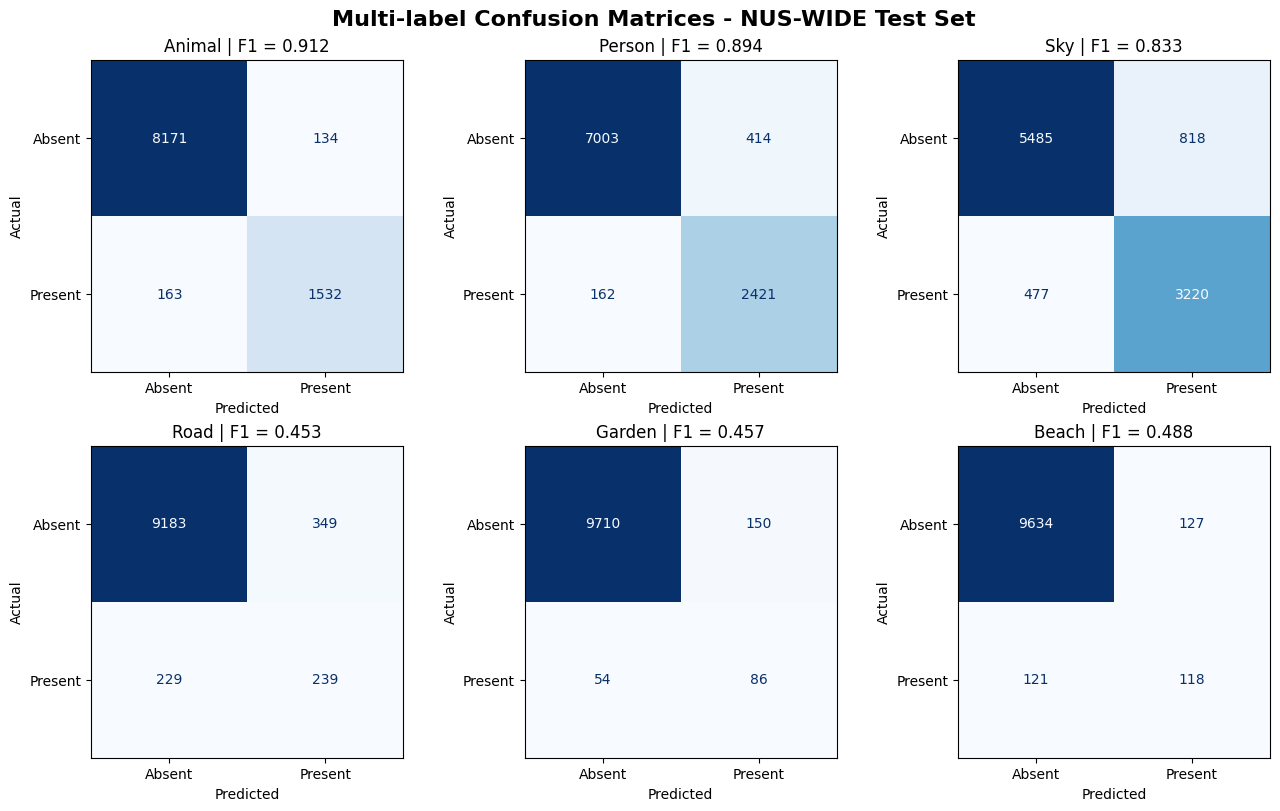

===== CONFUSION MATRIX SUMMARY =====
animal     | TP=1532 FP= 134 FN= 163 TN=8171
person     | TP=2421 FP= 414 FN= 162 TN=7003
sky        | TP=3220 FP= 818 FN= 477 TN=5485
road       | TP= 239 FP= 349 FN= 229 TN=9183
garden     | TP=  86 FP= 150 FN=  54 TN=9710
beach      | TP= 118 FP= 127 FN= 121 TN=9634

Saved figure: /content/drive/MyDrive/Image_tagging/results/cnn_test_confusion_matrix_summary.png

SUCCESS: Confusion matrix visualization completed!


In [11]:
# ==================================================
# PHASE 4 - STEP 6.4
# CONFUSION MATRIX VISUALIZATION
# ==================================================

import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay

RESULTS_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/results"
)

# Select labels for visualization.
# Do not change model predictions or thresholds.
selected_labels = [
    "animal",
    "person",
    "sky",
    "road",
    "garden",
    "beach"
]

assert all(label in LABEL_COLUMNS for label in selected_labels)

fig, axes = plt.subplots(
    2, 3,
    figsize=(13, 8),
    constrained_layout=True
)

for ax, label in zip(axes.flat, selected_labels):

    label_index = LABEL_COLUMNS.index(label)

    cm = confusion_matrices[label_index]

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Absent", "Present"]
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    label_f1 = per_label_df.loc[
        per_label_df["label"] == label,
        "f1_score"
    ].iloc[0]

    ax.set_title(
        f"{label.capitalize()} | F1 = {label_f1:.3f}",
        fontsize=12
    )

    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

fig.suptitle(
    "Multi-label Confusion Matrices - NUS-WIDE Test Set",
    fontsize=16,
    fontweight="bold"
)

output_path = (
    RESULTS_DIR / "cnn_test_confusion_matrix_summary.png"
)

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("===== CONFUSION MATRIX SUMMARY =====")

for label in selected_labels:

    i = LABEL_COLUMNS.index(label)

    tn_i, fp_i, fn_i, tp_i = (
        confusion_matrices[i].ravel()
    )

    print(
        f"{label:10s} | "
        f"TP={tp_i:4d} "
        f"FP={fp_i:4d} "
        f"FN={fn_i:4d} "
        f"TN={tn_i:4d}"
    )

print("\nSaved figure:", output_path)
print("\nSUCCESS: Confusion matrix visualization completed!")

## Step 6.5: Error Analysis and Visualization

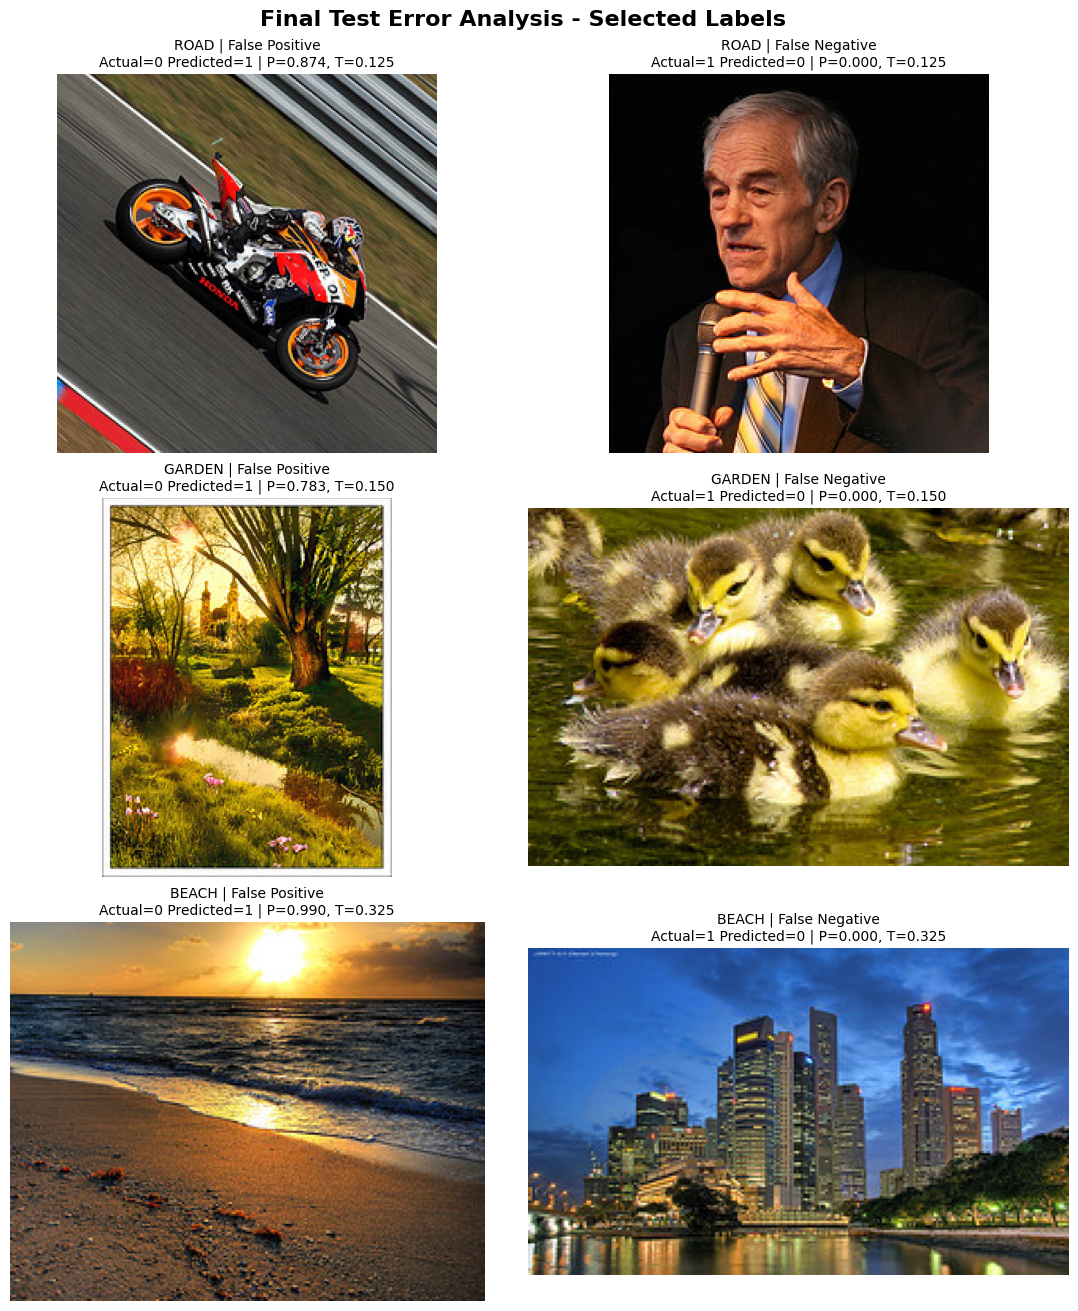

===== SELECTED ERROR EXAMPLES =====
 label     error_type            filename  actual  predicted  probability  threshold
  road False Positive 0334_2148175491.jpg       0          1     0.873850      0.125
  road False Negative 0016_1972399154.jpg       1          0     0.000218      0.125
garden False Positive 0499_2430412543.jpg       0          1     0.783362      0.150
garden False Negative  0344_706819255.jpg       1          0     0.000121      0.150
 beach False Positive  0219_437501641.jpg       0          1     0.989851      0.325
 beach False Negative  0594_392172411.jpg       1          0     0.000154      0.325

===== OVERALL ERROR SUMMARY =====
Total label decisions: 300000
Total False Positives: 7993
Total False Negatives: 4787
Images with at least one incorrect label: 6368

===== SAVED FILES =====
Error visualization: /content/drive/MyDrive/Image_tagging/results/cnn_test_error_examples.png
Error examples CSV: /content/drive/MyDrive/Image_tagging/results/cnn_test_error_ex

In [12]:
# ==================================================
# PHASE 4 - STEP 6.5
# ERROR ANALYSIS AND VISUALIZATION
# ==================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

RESULTS_DIR = Path(
    "/content/drive/MyDrive/Image_tagging/results"
)
TEST_DIR = Path("/content/datasets/NUS_WIDE/test")

selected_labels = ["road", "garden", "beach"]

# Verify saved test predictions and label alignment
assert Y_test.shape == (10000, 30)
assert Y_pred.shape == (10000, 30)
assert test_probabilities.shape == (10000, 30)

assert len(test_df) == 10000
assert all(label in LABEL_COLUMNS for label in selected_labels)

# 1. Collect representative errors
error_records = []

for label in selected_labels:
    j = LABEL_COLUMNS.index(label)
    threshold = float(final_thresholds[j])

    # False Positive: predicted 1, actual 0
    fp_indices = np.where(
        (Y_test[:, j] == 0) & (Y_pred[:, j] == 1)
    )[0]

    # False Negative: predicted 0, actual 1
    fn_indices = np.where(
        (Y_test[:, j] == 1) & (Y_pred[:, j] == 0)
    )[0]

    # Choose high-confidence FP and low-confidence FN.
    # These are illustrative errors, not random samples.
    fp_sorted = fp_indices[
        np.argsort(-test_probabilities[fp_indices, j])
    ]

    fn_sorted = fn_indices[
        np.argsort(test_probabilities[fn_indices, j])
    ]

    for error_type, indices in [
        ("False Positive", fp_sorted),
        ("False Negative", fn_sorted)
    ]:
        if len(indices) == 0:
            continue

        idx = int(indices[0])

        filename = Path(
            str(test_df.iloc[idx]["image"]).replace("\\", "/")
        ).name

        error_records.append({
            "index": idx,
            "image": str(test_df.iloc[idx]["image"]),
            "filename": filename,
            "label": label,
            "error_type": error_type,
            "actual": int(Y_test[idx, j]),
            "predicted": int(Y_pred[idx, j]),
            "probability": float(test_probabilities[idx, j]),
            "threshold": threshold,
        })

error_df = pd.DataFrame(error_records)

assert len(error_df) == 6, (
    "Expected FP and FN examples for all 3 labels."
)

# 2. Plot actual error images
fig, axes = plt.subplots(
    3, 2,
    figsize=(11, 13),
    constrained_layout=True
)

for row_idx, label in enumerate(selected_labels):

    for col_idx, error_type in enumerate(
        ["False Positive", "False Negative"]
    ):
        ax = axes[row_idx, col_idx]

        record = error_df[
            (error_df["label"] == label)
            & (error_df["error_type"] == error_type)
        ].iloc[0]

        image_path = TEST_DIR / record["filename"]

        assert image_path.is_file(), image_path

        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"{label.upper()} | {error_type}\n"
            f"Actual={record['actual']} "
            f"Predicted={record['predicted']} | "
            f"P={record['probability']:.3f}, "
            f"T={record['threshold']:.3f}",
            fontsize=10
        )

        ax.axis("off")

fig.suptitle(
    "Final Test Error Analysis - Selected Labels",
    fontsize=16,
    fontweight="bold"
)

figure_path = RESULTS_DIR / "cnn_test_error_examples.png"

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# 3. Save example details
csv_path = RESULTS_DIR / "cnn_test_error_examples.csv"

error_df.to_csv(csv_path, index=False)

print("===== SELECTED ERROR EXAMPLES =====")
print(
    error_df[
        ["label", "error_type", "filename",
         "actual", "predicted", "probability", "threshold"]
    ].to_string(index=False)
)

# 4. Summarize overall error counts
print("\n===== OVERALL ERROR SUMMARY =====")

total_label_decisions = Y_test.size
total_fp = int(((Y_test == 0) & (Y_pred == 1)).sum())
total_fn = int(((Y_test == 1) & (Y_pred == 0)).sum())

print("Total label decisions:", total_label_decisions)
print("Total False Positives:", total_fp)
print("Total False Negatives:", total_fn)
print(
    "Images with at least one incorrect label:",
    int(np.any(Y_test != Y_pred, axis=1).sum())
)

print("\n===== SAVED FILES =====")
print("Error visualization:", figure_path)
print("Error examples CSV:", csv_path)

print("\nSUCCESS: Test error analysis completed!")

## Step 6.6: Final Results Verification

In [13]:
# ==================================================
# PHASE 4 - STEP 6.6
# FINAL RESULTS VERIFICATION
# ==================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import f1_score

PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")
RESULTS_DIR = PROJECT_ROOT / "results"

print("===== PHASE 4 FINAL VERIFICATION =====")

# 1. Check required output files
required_files = {
    "Test Probabilities":
        RESULTS_DIR / "cnn_test_probabilities.npy",
    "Predictions CSV":
        RESULTS_DIR / "predictions_test.csv",
    "Final Test Metrics":
        RESULTS_DIR / "cnn_final_test_metrics.json",
    "Per-Label Metrics":
        RESULTS_DIR / "cnn_test_per_label_metrics.csv",
    "Confusion Matrices":
        RESULTS_DIR / "cnn_test_confusion_matrices.npy",
    "Confusion Matrix Figure":
        RESULTS_DIR / "cnn_test_confusion_matrix_summary.png",
    "Error Analysis Figure":
        RESULTS_DIR / "cnn_test_error_examples.png",
    "Error Examples CSV":
        RESULTS_DIR / "cnn_test_error_examples.csv",
}

for name, path in required_files.items():
    assert path.is_file() and path.stat().st_size > 0, (
        f"Missing or empty file: {path}"
    )
    print(f"[OK] {name}")

# 2. Reload saved results
probs = np.load(
    required_files["Test Probabilities"],
    allow_pickle=False
)
pred_csv = pd.read_csv(required_files["Predictions CSV"])
label_metrics = pd.read_csv(required_files["Per-Label Metrics"])

with open(
    required_files["Final Test Metrics"],
    "r",
    encoding="utf-8"
) as f:
    saved_metrics = json.load(f)

# 3. Check CSV structure and row ordering
assert probs.shape == (10000, 30)
assert pred_csv.shape == (10000, 31)
assert pred_csv.columns.tolist() == ["image"] + LABEL_COLUMNS
assert pred_csv["image"].tolist() == test_df["image"].tolist()
assert label_metrics["label"].tolist() == LABEL_COLUMNS

np.testing.assert_allclose(
    pred_csv[LABEL_COLUMNS].to_numpy(),
    probs,
    rtol=1e-5,
    atol=1e-6
)

# 4. Independently verify saved Macro-F1
ground_truth = test_df[LABEL_COLUMNS].to_numpy(
    dtype=np.int32
)

locked_predictions = (
    probs >= final_thresholds[None, :]
).astype(np.int32)

verified_macro_f1 = f1_score(
    ground_truth,
    locked_predictions,
    average="macro",
    zero_division=0
)

assert np.isclose(
    verified_macro_f1,
    saved_metrics["macro_f1"],
    atol=1e-6
)

print("\n===== VERIFIED FINAL RESULTS =====")
print("Test images:", len(pred_csv))
print("Labels:", len(LABEL_COLUMNS))
print("Macro-F1:", round(verified_macro_f1, 4))
print("Micro-F1:", round(saved_metrics["micro_f1"], 4))
print(
    "Subset Accuracy:",
    round(saved_metrics["subset_accuracy"], 4)
)

print("\nPrediction ordering: PASSED")
print("CSV probabilities: PASSED")
print("Saved metrics: PASSED")
print("Required output files: PASSED")

print("\nSUCCESS: PHASE 4 VERIFIED AND COMPLETE!")

===== PHASE 4 FINAL VERIFICATION =====
[OK] Test Probabilities
[OK] Predictions CSV
[OK] Final Test Metrics
[OK] Per-Label Metrics
[OK] Confusion Matrices
[OK] Confusion Matrix Figure
[OK] Error Analysis Figure
[OK] Error Examples CSV

===== VERIFIED FINAL RESULTS =====
Test images: 10000
Labels: 30
Macro-F1: 0.6206
Micro-F1: 0.7273
Subset Accuracy: 0.3632

Prediction ordering: PASSED
CSV probabilities: PASSED
Saved metrics: PASSED
Required output files: PASSED

SUCCESS: PHASE 4 VERIFIED AND COMPLETE!


# Phase 5: Final Code Preparation and Submission

## Step 7.1: Notebook Structure and Project Artifact Review

In [14]:
# ==================================================
# PHASE 5 - STEP 7.1
# NOTEBOOK STRUCTURE AND ARTIFACT REVIEW
# ==================================================

from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/Image_tagging")

print("===== PROJECT ARTIFACT REVIEW =====")

groups = {
    "Dataset CSVs": [
        "nuswide_top30_60k5k10k_stratified_train.csv",
        "nuswide_top30_60k5k10k_stratified_validation.csv",
        "nuswide_top30_60k5k10k_stratified_test.csv",
    ],
    "Final Model": [
        "models/cnn/resnet18_finetuned_best.pth",
        "models/cnn/resnet18_finetuned_thresholds.json",
    ],
    "Final Test Results": [
        "results/predictions_test.csv",
        "results/cnn_final_test_metrics.json",
        "results/cnn_test_per_label_metrics.csv",
        "results/cnn_test_confusion_matrix_summary.png",
        "results/cnn_test_error_examples.png",
    ],
}

missing = []

for group, paths in groups.items():
    print(f"\n[{group}]")
    for relative_path in paths:
        path = ROOT / relative_path
        exists = path.is_file() and path.stat().st_size > 0

        print(
            "OK     " if exists else "MISSING",
            relative_path
        )

        if not exists:
            missing.append(relative_path)

print("\n===== RUNTIME OBJECTS =====")

required_objects = [
    "LABEL_COLUMNS",
    "test_df",
    "final_cnn",
    "final_thresholds",
    "test_loader",
    "test_probabilities",
    "Y_test",
    "Y_pred",
]

for name in required_objects:
    print(
        f"{name}:",
        "AVAILABLE" if name in globals() else "NOT LOADED"
    )

print("\n===== REVIEW RESULT =====")
print("Missing files:", len(missing))

if missing:
    print("Please review missing artifacts.")
else:
    print("SUCCESS: Required project artifacts are available!")

===== PROJECT ARTIFACT REVIEW =====

[Dataset CSVs]
OK      nuswide_top30_60k5k10k_stratified_train.csv
OK      nuswide_top30_60k5k10k_stratified_validation.csv
OK      nuswide_top30_60k5k10k_stratified_test.csv

[Final Model]
OK      models/cnn/resnet18_finetuned_best.pth
OK      models/cnn/resnet18_finetuned_thresholds.json

[Final Test Results]
OK      results/predictions_test.csv
OK      results/cnn_final_test_metrics.json
OK      results/cnn_test_per_label_metrics.csv
OK      results/cnn_test_confusion_matrix_summary.png
OK      results/cnn_test_error_examples.png

===== RUNTIME OBJECTS =====
LABEL_COLUMNS: AVAILABLE
test_df: AVAILABLE
final_cnn: AVAILABLE
final_thresholds: AVAILABLE
test_loader: AVAILABLE
test_probabilities: AVAILABLE
Y_test: AVAILABLE
Y_pred: AVAILABLE

===== REVIEW RESULT =====
Missing files: 0
SUCCESS: Required project artifacts are available!


## Step 7.2: Reproducibility and Environment Configuration

In [15]:
# ==================================================
# PHASE 5 - STEP 7.2
# REPRODUCIBILITY AND ENVIRONMENT CONFIGURATION
# ==================================================

import sys
import json
import platform
import importlib.metadata as metadata

from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torchvision
import sklearn
import PIL

PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")

print("===== ENVIRONMENT INFORMATION =====")

environment = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "pillow": PIL.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "CPU"
    )
}

for key, value in environment.items():
    print(f"{key}: {value}")

print("\n===== REQUIRED LIBRARIES =====")

packages = [
    "torch",
    "torchvision",
    "numpy",
    "pandas",
    "scikit-learn",
    "Pillow",
    "matplotlib",
    "scikit-image",
    "scipy",
    "joblib",
    "tqdm"
]

for package in packages:
    try:
        version = metadata.version(package)
        print(f"[OK] {package}: {version}")
    except metadata.PackageNotFoundError:
        print(f"[MISSING] {package}")

print("\n===== REPRODUCIBILITY CHECK =====")

required_paths = {
    "Dataset archive":
        PROJECT_ROOT / "NUS_WIDE.rar",

    "Test CSV":
        PROJECT_ROOT / "nuswide_top30_60k5k10k_stratified_test.csv",

    "Final CNN checkpoint":
        PROJECT_ROOT / "models/cnn/resnet18_finetuned_best.pth",

    "Final CNN thresholds":
        PROJECT_ROOT / "models/cnn/resnet18_finetuned_thresholds.json",

    "Saved test predictions":
        PROJECT_ROOT / "results/predictions_test.csv",
}

missing = []

for name, path in required_paths.items():
    exists = path.is_file() and path.stat().st_size > 0

    print(f"{name}: {'OK' if exists else 'MISSING'}")

    if not exists:
        missing.append(name)

# Save environment metadata
output_path = PROJECT_ROOT / "results/environment_info.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(
        environment,
        f,
        indent=2,
        ensure_ascii=False
    )

print("\nSaved environment info:", output_path)

assert not missing, f"Missing files: {missing}"

print("\nSUCCESS: Environment configuration verified!")

===== ENVIRONMENT INFORMATION =====
python: 3.13.16
torch: 2.11.0+cu130
torchvision: 0.26.0+cu130
numpy: 2.1.3
pandas: 2.2.3
scikit_learn: 1.6.1
pillow: 11.3.0
cuda_available: True
gpu: Tesla T4

===== REQUIRED LIBRARIES =====
[OK] torch: 2.11.0+cu130
[OK] torchvision: 0.26.0+cu130
[OK] numpy: 2.1.3
[OK] pandas: 2.2.3
[OK] scikit-learn: 1.6.1
[OK] Pillow: 11.3.0
[OK] matplotlib: 3.10.0
[OK] scikit-image: 0.25.2
[OK] scipy: 1.16.3
[OK] joblib: 1.6.0
[OK] tqdm: 4.67.3

===== REPRODUCIBILITY CHECK =====
Dataset archive: OK
Test CSV: OK
Final CNN checkpoint: OK
Final CNN thresholds: OK
Saved test predictions: OK

Saved environment info: /content/drive/MyDrive/Image_tagging/results/environment_info.json

SUCCESS: Environment configuration verified!


## Step 7.3: Dependency Management and Requirements Verification

In [16]:
# ==================================================
# PHASE 5 - STEP 7.3
# DEPENDENCY MANAGEMENT AND REQUIREMENTS
# ==================================================

from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
import json

PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")

# Main dependencies needed for the complete project
dependencies = [
    "numpy",
    "pandas",
    "scikit-learn",
    "scikit-image",
    "scipy",
    "Pillow",
    "matplotlib",
    "joblib",
    "tqdm",
    "torch",
    "torchvision",
]

print("===== DEPENDENCY VERIFICATION =====")

installed = {}
missing = []

for package in dependencies:
    try:
        installed_version = version(package)
        installed[package] = installed_version
        print(f"[OK] {package}: {installed_version}")
    except PackageNotFoundError:
        missing.append(package)
        print(f"[MISSING] {package}")

assert not missing, f"Missing dependencies: {missing}"

# Use compatible version ranges for general dependencies.
# Let Colab provide its matching torch/torchvision CUDA builds.
requirements = [
    "# Automatic Image Tagging - Python dependencies",
    "# Tested in Google Colab with Python 3.13.16",
    "# GPU runtime: NVIDIA Tesla T4",
    "# Tested torch: 2.11.0+cu130",
    "# Tested torchvision: 0.26.0+cu130",
    "# Select matching torch/torchvision builds for your platform.",
    "",
    "numpy>=2.1,<3",
    "pandas>=2.2,<3",
    "scikit-learn>=1.6,<2",
    "scikit-image>=0.25,<1",
    "scipy>=1.16,<2",
    "Pillow>=11,<13",
    "matplotlib>=3.10,<4",
    "joblib>=1.6,<2",
    "tqdm>=4.67,<5",
    "torch>=2.11,<3",
    "torchvision>=0.26,<1",
]

requirements_path = PROJECT_ROOT / "requirements.txt"

# Do not overwrite an existing requirements file silently.
if requirements_path.exists():
    print("\nExisting requirements.txt found:")
    print(requirements_path.read_text(encoding="utf-8")[:3000])
    print("\nKeeping the existing file unchanged.")
    print("Proposed requirements will be saved separately.")

    requirements_path = PROJECT_ROOT / "requirements_proposed.txt"

requirements_path.write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

# Save exact installed versions for reference.
versions_path = (
    PROJECT_ROOT / "results/installed_package_versions.json"
)

versions_path.parent.mkdir(parents=True, exist_ok=True)

with open(versions_path, "w", encoding="utf-8") as f:
    json.dump(installed, f, indent=2, ensure_ascii=False)

print("\n===== SAVED FILES =====")
print("Requirements:", requirements_path)
print("Installed versions:", versions_path)

print("\n===== REQUIREMENTS CONTENT =====")
print(requirements_path.read_text(encoding="utf-8"))

print("SUCCESS: Dependency verification completed!")

===== DEPENDENCY VERIFICATION =====
[OK] numpy: 2.1.3
[OK] pandas: 2.2.3
[OK] scikit-learn: 1.6.1
[OK] scikit-image: 0.25.2
[OK] scipy: 1.16.3
[OK] Pillow: 11.3.0
[OK] matplotlib: 3.10.0
[OK] joblib: 1.6.0
[OK] tqdm: 4.67.3
[OK] torch: 2.11.0+cu130
[OK] torchvision: 0.26.0+cu130

===== SAVED FILES =====
Requirements: /content/drive/MyDrive/Image_tagging/requirements.txt
Installed versions: /content/drive/MyDrive/Image_tagging/results/installed_package_versions.json

===== REQUIREMENTS CONTENT =====
# Automatic Image Tagging - Python dependencies
# Tested in Google Colab with Python 3.13.16
# GPU runtime: NVIDIA Tesla T4
# Tested torch: 2.11.0+cu130
# Tested torchvision: 0.26.0+cu130
# Select matching torch/torchvision builds for your platform.

numpy>=2.1,<3
pandas>=2.2,<3
scikit-learn>=1.6,<2
scikit-image>=0.25,<1
scipy>=1.16,<2
Pillow>=11,<13
matplotlib>=3.10,<4
joblib>=1.6,<2
tqdm>=4.67,<5
torch>=2.11,<3
torchvision>=0.26,<1

SUCCESS: Dependency verification completed!


## Step 7.4: Single Image Tagging Demonstration

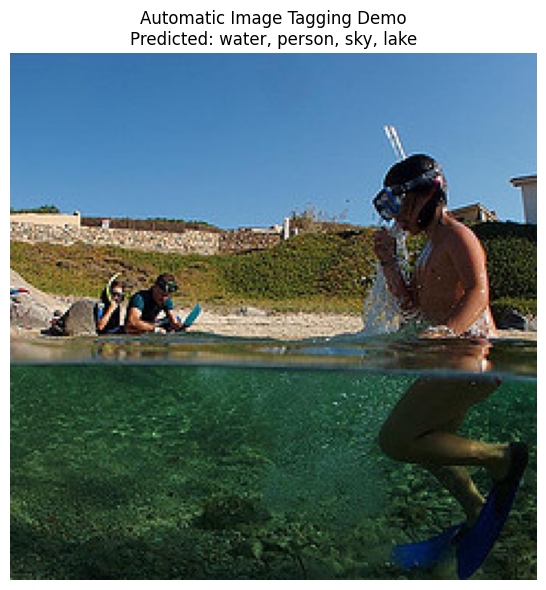

===== SINGLE IMAGE TAGGING DEMO =====
Image: diver\0403_2109784239.jpg
Predicted tag count: 4
Predicted tags: ['water', 'person', 'sky', 'lake']

===== PREDICTED TAG DETAILS =====
water        | Probability: 0.9821 | Threshold: 0.5000
person       | Probability: 0.8138 | Threshold: 0.2000
sky          | Probability: 0.4549 | Threshold: 0.2250
lake         | Probability: 0.2851 | Threshold: 0.2250

===== CONSISTENCY CHECK =====
Maximum difference from saved predictions: 2.0116567611694336e-07

Saved demo figure: /content/drive/MyDrive/Image_tagging/results/single_image_tagging_demo.png

SUCCESS: Single-image tagging demo completed!


In [17]:
# ==================================================
# PHASE 5 - STEP 7.4
# SINGLE IMAGE TAGGING DEMONSTRATION
# ==================================================

import numpy as np
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

# Use an image from the existing test dataset.
# This is a demonstration, not additional model tuning.
DEMO_INDEX = 0

TEST_DIR = Path("/content/datasets/NUS_WIDE/test")
RESULTS_DIR = Path("/content/drive/MyDrive/Image_tagging/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Locate image in the CSV
image_name = str(test_df.iloc[DEMO_INDEX]["image"])
filename = Path(image_name.replace("\\", "/")).name
image_path = TEST_DIR / filename

assert image_path.is_file(), f"Image not found: {image_path}"

# 2. Load the image
with Image.open(image_path) as img:
    demo_image = img.convert("RGB")

# 3. Apply the same preprocessing as validation/test
input_tensor = test_transform(demo_image).unsqueeze(0).to(device)

# 4. Predict using the final CNN
final_cnn.eval()

with torch.inference_mode():
    logits = final_cnn(input_tensor)
    probabilities = torch.sigmoid(logits)[0].cpu().numpy()

assert probabilities.shape == (30,)

# 5. Apply locked per-label thresholds
predicted_flags = probabilities >= final_thresholds

# 6. Sort predicted labels by probability
predicted_indices = np.where(predicted_flags)[0]
predicted_indices = sorted(
    predicted_indices,
    key=lambda i: float(probabilities[i]),
    reverse=True
)

predicted_tags = [
    LABEL_COLUMNS[i] for i in predicted_indices
]

# 7. Display result
fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(demo_image)
ax.axis("off")

tag_text = ", ".join(predicted_tags) if predicted_tags else "No tags predicted"

ax.set_title(
    f"Automatic Image Tagging Demo\nPredicted: {tag_text}",
    fontsize=12
)

plt.tight_layout()

output_path = RESULTS_DIR / "single_image_tagging_demo.png"

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# 8. Display probabilities and thresholds
print("===== SINGLE IMAGE TAGGING DEMO =====")
print("Image:", image_name)
print("Predicted tag count:", len(predicted_tags))
print("Predicted tags:", predicted_tags)

print("\n===== PREDICTED TAG DETAILS =====")

for i in predicted_indices:
    print(
        f"{LABEL_COLUMNS[i]:12s} | "
        f"Probability: {probabilities[i]:.4f} | "
        f"Threshold: {final_thresholds[i]:.4f}"
    )

# 9. Compare with the previously saved inference
saved_probabilities = np.load(
    RESULTS_DIR / "cnn_test_probabilities.npy",
    allow_pickle=False
)

max_difference = float(
    np.abs(probabilities - saved_probabilities[DEMO_INDEX]).max()
)

print("\n===== CONSISTENCY CHECK =====")
print("Maximum difference from saved predictions:", max_difference)

assert np.allclose(
    probabilities,
    saved_probabilities[DEMO_INDEX],
    atol=1e-5,
    rtol=1e-5
)

print("\nSaved demo figure:", output_path)
print("\nSUCCESS: Single-image tagging demo completed!")

## Step 7.5: Final Submission CSV Verification

In [18]:
# ==================================================
# PHASE 5 - STEP 7.5
# FINAL SUBMISSION CSV VERIFICATION
# ==================================================

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Image_tagging")
RESULTS_DIR = ROOT / "results"

PREDICTIONS_PATH = RESULTS_DIR / "predictions_test.csv"
SAMPLE_PATH = RESULTS_DIR / "test_prediction_samples.csv"

print("===== FINAL SUBMISSION CSV CHECK =====")

# 1. Read the saved submission
submission = pd.read_csv(PREDICTIONS_PATH)
test_reference = pd.read_csv(
    ROOT / "nuswide_top30_60k5k10k_stratified_test.csv"
)

# 2. Verify shape and column order
assert submission.shape == (10000, 31)
assert submission.columns.tolist() == ["image"] + LABEL_COLUMNS

# 3. Verify image ordering
assert submission["image"].tolist() == (
    test_reference["image"].tolist()
)

assert submission["image"].is_unique
assert not submission.isna().any().any()

# 4. Verify probabilities
probabilities = submission[LABEL_COLUMNS].to_numpy()

assert np.isfinite(probabilities).all()
assert np.all((probabilities >= 0) & (probabilities <= 1))

# 5. Convert probabilities to predicted tags
predicted_binary = (
    probabilities >= final_thresholds[None, :]
)

predicted_tags = [
    ", ".join(
        LABEL_COLUMNS[j]
        for j in np.where(row)[0]
    )
    for row in predicted_binary
]

# 6. Create a readable sample CSV
sample_df = pd.DataFrame({
    "image": submission["image"],
    "predicted_tags": predicted_tags,
    "predicted_tag_count": predicted_binary.sum(axis=1)
})

# First 20 test examples, in original CSV order
sample_df.head(20).to_csv(
    SAMPLE_PATH,
    index=False
)

print("Images:", len(submission))
print("Probability columns:", len(LABEL_COLUMNS))
print("Missing values:", int(submission.isna().sum().sum()))
print("CSV image order: PASSED")
print("Probability range: PASSED")

print("\n===== PREDICTION SAMPLES =====")
print(sample_df.head(5).to_string(index=False))

print("\n===== SAVED FILES =====")
print("Official probability CSV:", PREDICTIONS_PATH)
print("Readable sample CSV:", SAMPLE_PATH)

print("\nSUCCESS: Submission CSV verified!")

===== FINAL SUBMISSION CSV CHECK =====
Images: 10000
Probability columns: 30
Missing values: 0
CSV image order: PASSED
Probability range: PASSED

===== PREDICTION SAMPLES =====
                     image           predicted_tags  predicted_tag_count
 diver\0403_2109784239.jpg sky, person, water, lake                    4
column\0384_2237033097.jpg                    grass                    1
bengal\0593_2385729186.jpg    grass, plants, garden                    3
rowboat\0332_234325036.jpg                    grass                    1
   cabin\0289_70665798.jpg            person, grass                    2

===== SAVED FILES =====
Official probability CSV: /content/drive/MyDrive/Image_tagging/results/predictions_test.csv
Readable sample CSV: /content/drive/MyDrive/Image_tagging/results/test_prediction_samples.csv

SUCCESS: Submission CSV verified!


## Step 7.6: Notebook and GitHub Repository Review

In [19]:
# ==================================================
# PHASE 5 - STEP 7.6
# NOTEBOOK AND REPOSITORY REVIEW
# ==================================================

from pathlib import Path
import json
import subprocess

ROOT = Path("/content/drive/MyDrive/Image_tagging")

print("===== NOTEBOOK AND REPOSITORY REVIEW =====")

# 1. Check important deliverables in Drive
files = {
    "Dataset archive": ROOT / "NUS_WIDE.rar",
    "Final CNN checkpoint":
        ROOT / "models/cnn/resnet18_finetuned_best.pth",
    "CNN thresholds":
        ROOT / "models/cnn/resnet18_finetuned_thresholds.json",
    "Requirements": ROOT / "requirements.txt",
    "Test predictions":
        ROOT / "results/predictions_test.csv",
    "Test samples":
        ROOT / "results/test_prediction_samples.csv",
}

print("\n===== PROJECT FILES =====")

for name, path in files.items():
    print(
        f"{name}:",
        "OK" if path.is_file() else "MISSING"
    )

# 2. Search for notebook files
print("\n===== NOTEBOOK FILES =====")

notebooks = sorted(
    ROOT.rglob("*.ipynb")
)

if notebooks:
    for notebook in notebooks:
        print(notebook.relative_to(ROOT))
else:
    print("No notebook found inside project folder.")
    print("This is not necessarily an error.")
    print("Colab notebooks may be stored elsewhere in Drive.")

# 3. Inspect notebook structure, if available
for notebook in notebooks:
    with open(notebook, "r", encoding="utf-8") as f:
        nb = json.load(f)

    cells = nb.get("cells", [])

    code_cells = [
        cell for cell in cells
        if cell.get("cell_type") == "code"
    ]

    markdown_cells = [
        cell for cell in cells
        if cell.get("cell_type") == "markdown"
    ]

    print(f"\nNotebook: {notebook.name}")
    print("Total cells:", len(cells))
    print("Code cells:", len(code_cells))
    print("Markdown cells:", len(markdown_cells))

    print("\nLast 15 headings:")

    headings = []

    for cell in markdown_cells:
        source = "".join(cell.get("source", []))

        for line in source.splitlines():
            if line.strip().startswith("#"):
                headings.append(line.strip())

    for heading in headings[-15:]:
        print(heading)

# 4. Display repository URL for manual review
print("\n===== GITHUB REPOSITORY =====")
print(
    "https://github.com/Fifakung94/"
    "MachineLearning_Project"
)

print("\n===== REVIEW STATUS =====")
print("Drive files inspected.")
print("Notebook structure inspected if available.")
print("GitHub contents not yet verified.")

print("\nSUCCESS: Initial code review completed!")

===== NOTEBOOK AND REPOSITORY REVIEW =====

===== PROJECT FILES =====
Dataset archive: OK
Final CNN checkpoint: OK
CNN thresholds: OK
Requirements: OK
Test predictions: OK
Test samples: OK

===== NOTEBOOK FILES =====
No notebook found inside project folder.
This is not necessarily an error.
Colab notebooks may be stored elsewhere in Drive.

===== GITHUB REPOSITORY =====
https://github.com/Fifakung94/MachineLearning_Project

===== REVIEW STATUS =====
Drive files inspected.
Notebook structure inspected if available.
GitHub contents not yet verified.

SUCCESS: Initial code review completed!


## Step 7.7: Final Code Verification and Submission Readiness

In [20]:
# ==================================================
# PHASE 5 - STEP 7.7
# FINAL CODE VERIFICATION AND SUBMISSION READINESS
# ==================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import f1_score, accuracy_score

ROOT = Path("/content/drive/MyDrive/Image_tagging")
RESULTS = ROOT / "results"

print("===== FINAL CODE VERIFICATION =====")

# --------------------------------------------------
# 1. Check essential files
# --------------------------------------------------

required_files = {
    "Train CSV": ROOT / "nuswide_top30_60k5k10k_stratified_train.csv",
    "Validation CSV": ROOT / "nuswide_top30_60k5k10k_stratified_validation.csv",
    "Test CSV": ROOT / "nuswide_top30_60k5k10k_stratified_test.csv",
    "Dataset archive": ROOT / "NUS_WIDE.rar",
    "CNN checkpoint": ROOT / "models/cnn/resnet18_finetuned_best.pth",
    "CNN thresholds": ROOT / "models/cnn/resnet18_finetuned_thresholds.json",
    "Requirements": ROOT / "requirements.txt",
    "Predictions CSV": RESULTS / "predictions_test.csv",
    "Prediction samples": RESULTS / "test_prediction_samples.csv",
    "Final test metrics": RESULTS / "cnn_final_test_metrics.json",
    "Per-label metrics": RESULTS / "cnn_test_per_label_metrics.csv",
    "Confusion matrix figure": RESULTS / "cnn_test_confusion_matrix_summary.png",
    "Error analysis figure": RESULTS / "cnn_test_error_examples.png",
    "Single-image demo": RESULTS / "single_image_tagging_demo.png",
}

checks = {}

print("\n===== 1. REQUIRED FILES =====")

for name, path in required_files.items():
    valid = path.is_file() and path.stat().st_size > 0
    checks[name] = valid
    print(f"{'[PASS]' if valid else '[FAIL]'} {name}")

assert all(checks.values()), "Some required files are missing."

# --------------------------------------------------
# 2. Check test CSV and label alignment
# --------------------------------------------------

print("\n===== 2. DATA AND PREDICTION ALIGNMENT =====")

test_reference = pd.read_csv(required_files["Test CSV"])
predictions = pd.read_csv(required_files["Predictions CSV"])

label_columns = [
    c for c in test_reference.columns
    if c not in ["image", "_matched_top30_count",
                 "_matched_top30_labels"]
]

assert len(label_columns) == 30
assert len(test_reference) == 10000
assert predictions.shape == (10000, 31)
assert predictions.columns.tolist() == ["image"] + label_columns
assert predictions["image"].tolist() == test_reference["image"].tolist()
assert predictions["image"].is_unique

probabilities = predictions[label_columns].to_numpy(dtype=np.float64)

assert np.isfinite(probabilities).all()
assert ((probabilities >= 0) & (probabilities <= 1)).all()

print("[PASS] 10,000 test samples")
print("[PASS] 30 probability columns")
print("[PASS] Original image order")
print("[PASS] Valid probability values")

# --------------------------------------------------
# 3. Verify trained model and locked thresholds
# --------------------------------------------------

print("\n===== 3. MODEL AND THRESHOLDS =====")

with open(required_files["CNN thresholds"], encoding="utf-8") as f:
    threshold_data = json.load(f)

assert threshold_data["labels"] == label_columns

thresholds = np.asarray(
    threshold_data["thresholds"], dtype=np.float64
)

assert thresholds.shape == (30,)
assert np.isfinite(thresholds).all()
assert ((thresholds > 0) & (thresholds < 1)).all()

# Verify checkpoint metadata without running training.
import torch

checkpoint = torch.load(
    required_files["CNN checkpoint"],
    map_location="cpu",
    weights_only=True
)

assert checkpoint["labels"] == label_columns
assert "model_state_dict" in checkpoint

print("[PASS] CNN checkpoint metadata")
print("[PASS] 30 locked thresholds")
print("Checkpoint epoch:", checkpoint.get("epoch"))

del checkpoint

# --------------------------------------------------
# 4. Independently recompute official test metrics
# --------------------------------------------------

print("\n===== 4. FINAL METRIC CONSISTENCY =====")

y_true = test_reference[label_columns].to_numpy(dtype=np.int32)
y_pred = (probabilities >= thresholds[None, :]).astype(np.int32)

assert np.isin(y_true, [0, 1]).all()

with open(required_files["Final test metrics"], encoding="utf-8") as f:
    saved_metrics = json.load(f)

computed = {
    "macro_f1": f1_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "micro_f1": f1_score(
        y_true, y_pred, average="micro", zero_division=0
    ),
    "subset_accuracy": accuracy_score(y_true, y_pred),
}

for name, value in computed.items():
    saved = float(saved_metrics[name])
    assert np.isclose(value, saved, atol=1e-6), (
        f"{name}: computed={value}, saved={saved}"
    )
    print(f"[PASS] {name}: {value:.4f}")

# Check per-label results
per_label = pd.read_csv(required_files["Per-label metrics"])

assert per_label["label"].tolist() == label_columns
assert np.isclose(
    per_label["f1_score"].mean(),
    computed["macro_f1"],
    atol=1e-6
)

print("[PASS] Per-label F1 matches Macro-F1")

# --------------------------------------------------
# 5. Verify example submission
# --------------------------------------------------

print("\n===== 5. SAMPLE SUBMISSION =====")

samples = pd.read_csv(required_files["Prediction samples"])

assert {"image", "predicted_tags", "predicted_tag_count"}.issubset(
    samples.columns
)
assert len(samples) == 20
assert samples["image"].tolist() == test_reference["image"].head(20).tolist()

expected_sample_counts = y_pred[:20].sum(axis=1)

assert np.array_equal(
    samples["predicted_tag_count"].to_numpy(),
    expected_sample_counts
)

print("[PASS] 20 sample rows")
print("[PASS] Sample image alignment")
print("[PASS] Predicted tag counts")

# --------------------------------------------------
# 6. Save final verification summary
# --------------------------------------------------

verification_summary = {
    "project": "Automatic Image Tagging",
    "model": "Fine-tuned ResNet18 CNN",
    "test_images": len(test_reference),
    "num_labels": len(label_columns),
    "macro_f1": float(computed["macro_f1"]),
    "micro_f1": float(computed["micro_f1"]),
    "subset_accuracy": float(computed["subset_accuracy"]),
    "required_files_verified": len(required_files),
    "model_thresholds_locked": True,
    "prediction_alignment_verified": True,
    "metric_consistency_verified": True,
    "artifact_verification_passed": True,
    "notebook_fresh_runtime_tested": False,
    "github_repository_verified": False,
}

summary_path = RESULTS / "final_code_verification.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(
        verification_summary,
        f,
        indent=2,
        ensure_ascii=False
    )

print("\n===== FINAL SUMMARY =====")
print("Files verified:", len(required_files))
print("Test samples:", len(test_reference))
print("Labels:", len(label_columns))
print("Macro-F1:", f"{computed['macro_f1']:.4f}")
print("Micro-F1:", f"{computed['micro_f1']:.4f}")
print("Subset Accuracy:", f"{computed['subset_accuracy']:.4f}")

print("\nSaved verification:", summary_path)
print("\nSUCCESS: FINAL CODE ARTIFACT VERIFICATION PASSED!")

===== FINAL CODE VERIFICATION =====

===== 1. REQUIRED FILES =====
[PASS] Train CSV
[PASS] Validation CSV
[PASS] Test CSV
[PASS] Dataset archive
[PASS] CNN checkpoint
[PASS] CNN thresholds
[PASS] Requirements
[PASS] Predictions CSV
[PASS] Prediction samples
[PASS] Final test metrics
[PASS] Per-label metrics
[PASS] Confusion matrix figure
[PASS] Error analysis figure
[PASS] Single-image demo

===== 2. DATA AND PREDICTION ALIGNMENT =====
[PASS] 10,000 test samples
[PASS] 30 probability columns
[PASS] Original image order
[PASS] Valid probability values

===== 3. MODEL AND THRESHOLDS =====
[PASS] CNN checkpoint metadata
[PASS] 30 locked thresholds
Checkpoint epoch: 3

===== 4. FINAL METRIC CONSISTENCY =====
[PASS] macro_f1: 0.6206
[PASS] micro_f1: 0.7273
[PASS] subset_accuracy: 0.3632
[PASS] Per-label F1 matches Macro-F1

===== 5. SAMPLE SUBMISSION =====
[PASS] 20 sample rows
[PASS] Sample image alignment
[PASS] Predicted tag counts

===== FINAL SUMMARY =====
Files verified: 14
Test sampl

# Phase 6: EfficientNet and ResNet Comparison

## Step 8.1: EfficientNet Experiment Setup

In [1]:
# ==================================================
# PHASE 6 - STEP 8.1
# EFFICIENTNET EXPERIMENT SETUP
# ==================================================

from pathlib import Path
import torch
import torchvision
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

ROOT = Path("/content/drive/MyDrive/Image_tagging")
DATA_ROOT = Path("/content/datasets/NUS_WIDE")

print("===== EFFICIENTNET EXPERIMENT SETUP =====")

print("\n===== GPU =====")
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\n===== DATASETS =====")
for split in ["train", "validation", "test"]:
    folder = DATA_ROOT / split
    count = sum(1 for _ in folder.glob("*.jpg")) if folder.exists() else 0
    print(f"{split}: {count} images")

print("\n===== CSV FILES =====")
for split in ["train", "validation", "test"]:
    path = ROOT / f"nuswide_top30_60k5k10k_stratified_{split}.csv"
    print(f"{split} CSV:", "FOUND" if path.is_file() else "MISSING")

print("\n===== ORIGINAL MODEL =====")
print(
    "ResNet18 checkpoint:",
    (ROOT / "models/cnn/resnet18_finetuned_best.pth").is_file()
)

print("\n===== EFFICIENTNET-B0 =====")
print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("EfficientNet-B0 API: AVAILABLE")
print("Pretrained weights:", EfficientNet_B0_Weights.DEFAULT.name)

print("\nSUCCESS: EfficientNet setup inspection completed!")

===== EFFICIENTNET EXPERIMENT SETUP =====

===== GPU =====
CUDA available: True
GPU: Tesla T4

===== DATASETS =====
train: 0 images
validation: 0 images
test: 0 images

===== CSV FILES =====
train CSV: MISSING
validation CSV: MISSING
test CSV: MISSING

===== ORIGINAL MODEL =====
ResNet18 checkpoint: False

===== EFFICIENTNET-B0 =====
Torch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
EfficientNet-B0 API: AVAILABLE
Pretrained weights: IMAGENET1K_V1

SUCCESS: EfficientNet setup inspection completed!


# Phase 6: EfficientNet and ResNet Comparison

## Step 8.1: EfficientNet Experiment Setup and Dataset Loading

In [6]:
# ==================================================
# PHASE 6 - STEP 8.1
# EFFICIENTNET EXPERIMENT SETUP AND DATASET LOADING
# ==================================================

import pandas as pd
import torch
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")
DATA_ROOT = Path("/content/datasets/NUS_WIDE")

train_df = pd.read_csv(
    PROJECT_ROOT / "nuswide_top30_60k5k10k_stratified_train.csv"
)

val_df = pd.read_csv(
    PROJECT_ROOT / "nuswide_top30_60k5k10k_stratified_validation.csv"
)

LABEL_COLUMNS = [
    col for col in train_df.columns
    if col not in [
        "image",
        "_matched_top30_count",
        "_matched_top30_labels"
    ]
]

assert len(train_df) == 60000
assert len(val_df) == 5000
assert len(LABEL_COLUMNS) == 30

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Labels:", len(LABEL_COLUMNS))
print("Device:", device)

print("\nSUCCESS: EfficientNet experiment setup ready!")

Train: 60000
Validation: 5000
Labels: 30
Device: cuda

SUCCESS: EfficientNet experiment setup ready!


## Step 8.2: Restore and Verify Training and Validation Images

In [7]:
# ==================================================
# PHASE 6 - STEP 8.2
# RESTORE AND VERIFY TRAIN / VALIDATION IMAGES
# ==================================================

import subprocess
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")
DATA_ROOT = Path("/content/datasets/NUS_WIDE")
RAR_PATH = PROJECT_ROOT / "NUS_WIDE.rar"

assert RAR_PATH.is_file(), "Dataset archive not found!"

DATA_ROOT.mkdir(parents=True, exist_ok=True)

expected_splits = {
    "train": (train_df, 60000),
    "validation": (val_df, 5000),
}

print("===== TRAIN / VALIDATION RESTORATION =====")

# Check whether unrar is installed.
check = subprocess.run(
    ["bash", "-lc", "command -v unrar"],
    capture_output=True,
    text=True
)

if check.returncode != 0:
    print("Installing unrar...")
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(
        ["apt-get", "install", "-y", "-qq", "unrar"],
        check=True
    )

for split, (df, expected_count) in expected_splits.items():

    folder = DATA_ROOT / split
    existing_count = (
        sum(1 for _ in folder.glob("*.jpg"))
        if folder.is_dir() else 0
    )

    print(f"\n===== {split.upper()} =====")
    print("Existing images:", existing_count)

    # Avoid extracting if the complete split already exists.
    if existing_count != expected_count:
        print("Extracting:", split)

        result = subprocess.run(
            [
                "unrar", "x",
                "-o+",
                "-y",
                str(RAR_PATH),
                f"{split}/*",
                str(DATA_ROOT) + "/"
            ],
            capture_output=True,
            text=True
        )

        print("Unrar return code:", result.returncode)

        if result.returncode != 0:
            print(result.stdout[-3000:])
            print(result.stderr[-3000:])
            raise RuntimeError(
                f"Extraction failed for {split}"
            )

    # Check exact matching with the CSV.
    expected_names = {
        Path(str(name).replace("\\", "/")).name
        for name in df["image"]
    }

    actual_names = {
        p.name for p in folder.glob("*.jpg")
    }

    missing = expected_names - actual_names
    unexpected = actual_names - expected_names

    print("Image count:", len(actual_names))
    print("Missing:", len(missing))
    print("Unexpected:", len(unexpected))

    assert len(expected_names) == expected_count
    assert len(actual_names) == expected_count
    assert not missing and not unexpected

    # Verify images can be decoded.
    corrupted = []

    for image_name in tqdm(
        sorted(expected_names),
        desc=f"Verifying {split}"
    ):
        image_path = folder / image_name

        try:
            with Image.open(image_path) as img:
                img.verify()

            with Image.open(image_path) as img:
                img.convert("RGB").load()

        except Exception as exc:
            corrupted.append((image_name, str(exc)))

    print("Corrupted:", len(corrupted))

    if corrupted:
        print("Examples:", corrupted[:10])

    assert not corrupted, (
        f"{split} contains unreadable images."
    )

    print(f"SUCCESS: {split} verified!")

print("\nSUCCESS: TRAIN AND VALIDATION DATASETS READY!")

===== TRAIN / VALIDATION RESTORATION =====

===== TRAIN =====
Existing images: 0
Extracting: train
Unrar return code: 0
Image count: 60000
Missing: 0
Unexpected: 0


Verifying train:   0%|          | 0/60000 [00:00<?, ?it/s]

Corrupted: 0
SUCCESS: train verified!

===== VALIDATION =====
Existing images: 0
Extracting: validation
Unrar return code: 0
Image count: 5000
Missing: 0
Unexpected: 0


Verifying validation:   0%|          | 0/5000 [00:00<?, ?it/s]

Corrupted: 0
SUCCESS: validation verified!

SUCCESS: TRAIN AND VALIDATION DATASETS READY!


## Step 8.3: EfficientNet-B0 Model Architecture and Training Configuration

In [8]:
# ==================================================
# PHASE 6 - STEP 8.3
# EFFICIENTNET-B0 ARCHITECTURE AND CONFIGURATION
# ==================================================

import random
import numpy as np
import torch
import torch.nn as nn

from pathlib import Path
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)
from torch.utils.data import DataLoader, Dataset
from PIL import Image

# 1. Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 2. Experiment directories
PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")
DATA_ROOT = Path("/content/datasets/NUS_WIDE")

EFF_MODEL_DIR = PROJECT_ROOT / "models/efficientnet_b0"
EFF_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 3. Load pretrained EfficientNet-B0
eff_weights = EfficientNet_B0_Weights.DEFAULT
eff_model = efficientnet_b0(weights=eff_weights)

# 4. Replace classification head for 30 labels
in_features = eff_model.classifier[1].in_features

eff_model.classifier[1] = nn.Linear(
    in_features,
    len(LABEL_COLUMNS)
)

# 5. Freeze pretrained feature extractor
for parameter in eff_model.features.parameters():
    parameter.requires_grad = False

# 6. Unfreeze the last feature block
for parameter in eff_model.features[-1].parameters():
    parameter.requires_grad = True

# 7. Train the full classification head
for parameter in eff_model.classifier.parameters():
    parameter.requires_grad = True

eff_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

eff_model = eff_model.to(eff_device)

# 8. Model-specific pretrained preprocessing
eff_val_transform = eff_weights.transforms()

print("===== EFFICIENTNET-B0 CONFIGURATION =====")
print("Model:", "EfficientNet-B0")
print("Pretrained:", "ImageNet")
print("Input size:", eff_val_transform.crop_size)
print("Output labels:", len(LABEL_COLUMNS))
print("Classifier input features:", in_features)
print("Device:", eff_device)

# 9. Count parameters
total_params = sum(
    p.numel() for p in eff_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in eff_model.parameters()
    if p.requires_grad
)

print("\n===== PARAMETERS =====")
print("Total:", f"{total_params:,}")
print("Trainable:", f"{trainable_params:,}")
print("Frozen:", f"{total_params - trainable_params:,}")

# 10. Verify model forward pass
eff_model.eval()

with torch.inference_mode():
    dummy_input = torch.zeros(
        2, 3, 224, 224,
        device=eff_device
    )
    dummy_output = eff_model(dummy_input)

assert dummy_output.shape == (2, 30)
assert torch.isfinite(dummy_output).all()

print("\n===== MODEL CHECK =====")
print("Input shape:", tuple(dummy_input.shape))
print("Output shape:", tuple(dummy_output.shape))

print("\nSUCCESS: EfficientNet-B0 architecture ready!")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 48.5MB/s]


===== EFFICIENTNET-B0 CONFIGURATION =====
Model: EfficientNet-B0
Pretrained: ImageNet
Input size: [224]
Output labels: 30
Classifier input features: 1280
Device: cuda

===== PARAMETERS =====
Total: 4,045,978
Trainable: 450,590
Frozen: 3,595,388

===== MODEL CHECK =====
Input shape: (2, 3, 224, 224)
Output shape: (2, 30)

SUCCESS: EfficientNet-B0 architecture ready!


## Step 8.4: EfficientNet Training and Validation DataLoaders

In [9]:
# ==================================================
# PHASE 6 - STEP 8.4
# EFFICIENTNET TRAIN / VALIDATION DATALOADERS
# ==================================================

import numpy as np
import torch

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import EfficientNet_B0_Weights

# 1. Model-specific normalization and augmentation
eff_weights = EfficientNet_B0_Weights.DEFAULT
eff_val_transform = eff_weights.transforms()

# Training augmentation (only applied to Train)
eff_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=eff_val_transform.mean,
        std=eff_val_transform.std
    )
])

# 2. Image Dataset
class EfficientNetImageDataset(Dataset):

    def __init__(self, df, split, root, label_columns, transform):
        self.df = df.reset_index(drop=True)
        self.split = split
        self.root = Path(root)
        self.transform = transform

        self.label_columns = list(label_columns)

        self.labels = self.df[
            self.label_columns
        ].to_numpy(dtype=np.float32, copy=True)

        self.filenames = [
            Path(str(name).replace("\\", "/")).name
            for name in self.df["image"]
        ]

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        image_path = (
            self.root / self.split / self.filenames[index]
        )

        with Image.open(image_path) as image:
            image = self.transform(image.convert("RGB"))

        label = torch.from_numpy(
            self.labels[index].copy()
        )

        return image, label

# 3. Create datasets
eff_train_dataset = EfficientNetImageDataset(
    df=train_df,
    split="train",
    root=DATA_ROOT,
    label_columns=LABEL_COLUMNS,
    transform=eff_train_transform
)

eff_val_dataset = EfficientNetImageDataset(
    df=val_df,
    split="validation",
    root=DATA_ROOT,
    label_columns=LABEL_COLUMNS,
    transform=eff_val_transform
)

# 4. Create DataLoaders
eff_train_loader = DataLoader(
    eff_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

eff_val_loader = DataLoader(
    eff_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# 5. Validate first batches
train_images, train_labels = next(iter(eff_train_loader))
val_images, val_labels = next(iter(eff_val_loader))

assert train_images.shape == (32, 3, 224, 224)
assert train_labels.shape == (32, 30)
assert val_images.shape == (32, 3, 224, 224)
assert val_labels.shape == (32, 30)

assert torch.isfinite(train_images).all()
assert torch.isfinite(val_images).all()

print("===== EFFICIENTNET DATALOADER CHECK =====")
print("Training images:", len(eff_train_dataset))
print("Validation images:", len(eff_val_dataset))
print("Train batches:", len(eff_train_loader))
print("Validation batches:", len(eff_val_loader))
print("Train image shape:", tuple(train_images.shape))
print("Validation image shape:", tuple(val_images.shape))
print("Train labels shape:", tuple(train_labels.shape))
print("Validation labels shape:", tuple(val_labels.shape))

print("\nSUCCESS: EfficientNet DataLoaders ready!")

===== EFFICIENTNET DATALOADER CHECK =====
Training images: 60000
Validation images: 5000
Train batches: 1875
Validation batches: 157
Train image shape: (32, 3, 224, 224)
Validation image shape: (32, 3, 224, 224)
Train labels shape: (32, 30)
Validation labels shape: (32, 30)

SUCCESS: EfficientNet DataLoaders ready!


## Step 8.5: EfficientNet-B0 Fine-tuning and Validation

In [10]:
# ==================================================
# PHASE 6 - STEP 8.5
# EFFICIENTNET-B0 FINE-TUNING AND VALIDATION
# ==================================================

import json
import time
import numpy as np
import torch
import torch.nn as nn

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, accuracy_score

# 1. Training configuration
EFF_EPOCHS = 3
EFF_LEARNING_RATE = 1e-4
EFF_WEIGHT_DECAY = 1e-4
EFF_THRESHOLD = 0.5

EFF_MODEL_DIR = (
    Path("/content/drive/MyDrive/Image_tagging")
    / "models/efficientnet_b0"
)
EFF_MODEL_DIR.mkdir(parents=True, exist_ok=True)

EFF_CHECKPOINT_PATH = (
    EFF_MODEL_DIR / "efficientnet_b0_best.pth"
)
EFF_VAL_PROBS_PATH = (
    EFF_MODEL_DIR / "efficientnet_b0_best_val_probs.npy"
)
EFF_HISTORY_PATH = (
    EFF_MODEL_DIR / "efficientnet_b0_training_history.json"
)

# Safety: do not accidentally overwrite a completed experiment
existing_outputs = [
    p for p in [
        EFF_CHECKPOINT_PATH,
        EFF_VAL_PROBS_PATH,
        EFF_HISTORY_PATH
    ] if p.exists()
]

if existing_outputs:
    raise FileExistsError(
        "EfficientNet training outputs already exist. "
        "Inspect them before starting training again: "
        + ", ".join(str(p) for p in existing_outputs)
    )

assert len(eff_train_dataset) == 60000
assert len(eff_val_dataset) == 5000
assert len(LABEL_COLUMNS) == 30

# 2. Multi-label loss and optimizer
eff_criterion = nn.BCEWithLogitsLoss()

eff_optimizer = torch.optim.AdamW(
    (p for p in eff_model.parameters() if p.requires_grad),
    lr=EFF_LEARNING_RATE,
    weight_decay=EFF_WEIGHT_DECAY
)

# 3. Ground truth in original validation CSV order
eff_y_val = val_df[LABEL_COLUMNS].to_numpy(
    dtype=np.int32,
    copy=True
)

assert eff_y_val.shape == (5000, 30)

best_macro_f1 = -1.0
best_epoch = None
training_history = []

print("===== EFFICIENTNET-B0 TRAINING =====")
print("Epochs:", EFF_EPOCHS)
print("Learning rate:", EFF_LEARNING_RATE)
print("Weight decay:", EFF_WEIGHT_DECAY)
print("Validation threshold:", EFF_THRESHOLD)
print("Device:", eff_device)
print("Training: last feature block + classifier")

# 4. Training and validation loop
for epoch in range(1, EFF_EPOCHS + 1):

    epoch_start = time.perf_counter()

    eff_model.train()

    # Keep BatchNorm running statistics fixed.
    # Gradients still flow through trainable layers.
    for module in eff_model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()

    running_train_loss = 0.0
    train_samples = 0

    for images, targets in tqdm(
        eff_train_loader,
        desc=f"Epoch {epoch}/{EFF_EPOCHS} - Train"
    ):
        images = images.to(
            eff_device,
            non_blocking=True
        )

        targets = targets.to(
            eff_device,
            non_blocking=True
        )

        eff_optimizer.zero_grad(set_to_none=True)

        logits = eff_model(images)
        loss = eff_criterion(logits, targets)

        loss.backward()
        eff_optimizer.step()

        batch_size = images.size(0)
        running_train_loss += loss.item() * batch_size
        train_samples += batch_size

    train_loss = running_train_loss / train_samples

    # 5. Validation (no gradient updates)
    eff_model.eval()

    running_val_loss = 0.0
    val_samples = 0
    val_prob_batches = []
    val_target_batches = []

    with torch.inference_mode():
        for images, targets in tqdm(
            eff_val_loader,
            desc=f"Epoch {epoch}/{EFF_EPOCHS} - Validation"
        ):
            images = images.to(
                eff_device,
                non_blocking=True
            )

            targets_device = targets.to(
                eff_device,
                non_blocking=True
            )

            logits = eff_model(images)
            loss = eff_criterion(logits, targets_device)

            probs = torch.sigmoid(logits)

            batch_size = images.size(0)
            running_val_loss += loss.item() * batch_size
            val_samples += batch_size

            val_prob_batches.append(
                probs.cpu().numpy()
            )
            val_target_batches.append(
                targets.numpy()
            )

    val_loss = running_val_loss / val_samples

    val_probs = np.concatenate(
        val_prob_batches, axis=0
    ).astype(np.float32)

    val_targets = np.concatenate(
        val_target_batches, axis=0
    ).astype(np.int32)

    # Confirm DataLoader kept original CSV order
    assert np.array_equal(val_targets, eff_y_val)
    assert val_probs.shape == (5000, 30)
    assert np.isfinite(val_probs).all()

    val_pred = (val_probs >= EFF_THRESHOLD).astype(np.int32)

    macro_f1 = float(
        f1_score(
            eff_y_val, val_pred,
            average="macro",
            zero_division=0
        )
    )

    micro_f1 = float(
        f1_score(
            eff_y_val, val_pred,
            average="micro",
            zero_division=0
        )
    )

    subset_acc = float(
        accuracy_score(eff_y_val, val_pred)
    )

    elapsed = time.perf_counter() - epoch_start

    record = {
        "epoch": epoch,
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "macro_f1": macro_f1,
        "micro_f1": micro_f1,
        "subset_accuracy": subset_acc,
        "elapsed_seconds": float(elapsed)
    }

    training_history.append(record)

    # 6. Save best checkpoint using validation Macro-F1
    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1
        best_epoch = epoch

        torch.save({
            "epoch": epoch,
            "model_state_dict": eff_model.state_dict(),
            "optimizer_state_dict": eff_optimizer.state_dict(),
            "labels": list(LABEL_COLUMNS),
            "macro_f1": macro_f1,
            "micro_f1": micro_f1,
            "subset_accuracy": subset_acc,
            "threshold": EFF_THRESHOLD,
            "training_stage": "fine_tune_last_block",
            "architecture": "efficientnet_b0",
        }, EFF_CHECKPOINT_PATH)

        np.save(EFF_VAL_PROBS_PATH, val_probs)

        print(f"Best checkpoint saved (Epoch {epoch})")

    # Save progress after every completed epoch
    with open(EFF_HISTORY_PATH, "w", encoding="utf-8") as f:
        json.dump(
            training_history,
            f,
            indent=2,
            ensure_ascii=False
        )

    print(f"\n===== EPOCH {epoch}/{EFF_EPOCHS} =====")
    print(f"Train Loss:      {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Macro-F1:        {macro_f1:.4f}")
    print(f"Micro-F1:        {micro_f1:.4f}")
    print(f"Subset Accuracy: {subset_acc:.4f}")
    print(f"Elapsed seconds: {elapsed:.1f}")
    print(f"Best Epoch:      {best_epoch}")
    print(f"Best Macro-F1:   {best_macro_f1:.4f}")

# 7. Final checks
assert EFF_CHECKPOINT_PATH.is_file()
assert EFF_VAL_PROBS_PATH.is_file()
assert EFF_HISTORY_PATH.is_file()
assert len(training_history) == EFF_EPOCHS

print("\n===== TRAINING COMPLETE =====")
print("Best Epoch:", best_epoch)
print("Best Validation Macro-F1:", round(best_macro_f1, 4))

print("\n===== SAVED FILES =====")
print("Checkpoint:", EFF_CHECKPOINT_PATH)
print("Validation probabilities:", EFF_VAL_PROBS_PATH)
print("Training history:", EFF_HISTORY_PATH)

print("\nSUCCESS: EfficientNet-B0 training completed!")

===== EFFICIENTNET-B0 TRAINING =====
Epochs: 3
Learning rate: 0.0001
Weight decay: 0.0001
Validation threshold: 0.5
Device: cuda
Training: last feature block + classifier


Epoch 1/3 - Train:   0%|          | 0/1875 [00:00<?, ?it/s]

Epoch 1/3 - Validation:   0%|          | 0/157 [00:00<?, ?it/s]

Best checkpoint saved (Epoch 1)

===== EPOCH 1/3 =====
Train Loss:      0.1503
Validation Loss: 0.1120
Macro-F1:        0.5257
Micro-F1:        0.7000
Subset Accuracy: 0.3652
Elapsed seconds: 365.9
Best Epoch:      1
Best Macro-F1:   0.5257


Epoch 2/3 - Train:   0%|          | 0/1875 [00:00<?, ?it/s]

Epoch 2/3 - Validation:   0%|          | 0/157 [00:00<?, ?it/s]

Best checkpoint saved (Epoch 2)

===== EPOCH 2/3 =====
Train Loss:      0.1037
Validation Loss: 0.1059
Macro-F1:        0.5571
Micro-F1:        0.7101
Subset Accuracy: 0.3756
Elapsed seconds: 305.5
Best Epoch:      2
Best Macro-F1:   0.5571


Epoch 3/3 - Train:   0%|          | 0/1875 [00:00<?, ?it/s]

Epoch 3/3 - Validation:   0%|          | 0/157 [00:00<?, ?it/s]

Best checkpoint saved (Epoch 3)

===== EPOCH 3/3 =====
Train Loss:      0.0988
Validation Loss: 0.1035
Macro-F1:        0.5578
Micro-F1:        0.7153
Subset Accuracy: 0.3870
Elapsed seconds: 310.7
Best Epoch:      3
Best Macro-F1:   0.5578

===== TRAINING COMPLETE =====
Best Epoch: 3
Best Validation Macro-F1: 0.5578

===== SAVED FILES =====
Checkpoint: /content/drive/MyDrive/Image_tagging/models/efficientnet_b0/efficientnet_b0_best.pth
Validation probabilities: /content/drive/MyDrive/Image_tagging/models/efficientnet_b0/efficientnet_b0_best_val_probs.npy
Training history: /content/drive/MyDrive/Image_tagging/models/efficientnet_b0/efficientnet_b0_training_history.json

SUCCESS: EfficientNet-B0 training completed!


## Step 8.6: Label-specific Threshold Optimization — EfficientNet-B0

In [11]:

# ==================================================
# PHASE 6 - STEP 8.6
# EFFICIENTNET-B0 LABEL-SPECIFIC THRESHOLD OPTIMIZATION
# ==================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)

PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")
EFF_MODEL_DIR = PROJECT_ROOT / "models/efficientnet_b0"

VAL_PROBS_PATH = EFF_MODEL_DIR / "efficientnet_b0_best_val_probs.npy"
THRESHOLDS_PATH = EFF_MODEL_DIR / "efficientnet_b0_thresholds.json"
METRICS_PATH = EFF_MODEL_DIR / "efficientnet_b0_validation_metrics.json"

# 1. Prevent accidental overwrite
assert VAL_PROBS_PATH.is_file(), "Validation probabilities not found."

if THRESHOLDS_PATH.exists() or METRICS_PATH.exists():
    raise FileExistsError(
        "Threshold or metrics files already exist. "
        "Inspect saved results before running again."
    )

# 2. Load BEST epoch validation probabilities
eff_val_probs = np.load(
    VAL_PROBS_PATH,
    allow_pickle=False
)

eff_val_true = val_df[LABEL_COLUMNS].to_numpy(
    dtype=np.int32,
    copy=True
)

assert eff_val_probs.shape == (5000, 30)
assert eff_val_true.shape == (5000, 30)
assert np.isfinite(eff_val_probs).all()
assert ((eff_val_probs >= 0) & (eff_val_probs <= 1)).all()
assert np.isin(eff_val_true, [0, 1]).all()

# 3. Calculate baseline metrics at threshold 0.5
eff_pred_default = (eff_val_probs >= 0.5).astype(np.int32)

default_macro_f1 = float(
    f1_score(
        eff_val_true, eff_pred_default,
        average="macro", zero_division=0
    )
)

# 4. Optimize each label independently on validation
threshold_grid = np.round(
    np.arange(0.05, 0.9501, 0.025),
    3
)

eff_thresholds = np.empty(30, dtype=np.float32)
label_records = []

for j, label in enumerate(LABEL_COLUMNS):

    best_threshold = 0.5
    best_f1 = -1.0

    for threshold in threshold_grid:

        binary_pred = (
            eff_val_probs[:, j] >= threshold
        ).astype(np.int32)

        score = f1_score(
            eff_val_true[:, j],
            binary_pred,
            zero_division=0
        )

        # Keep first threshold when F1 is tied.
        if score > best_f1 + 1e-12:
            best_f1 = float(score)
            best_threshold = float(threshold)

    eff_thresholds[j] = best_threshold

    label_records.append({
        "label": label,
        "threshold": best_threshold,
        "validation_f1": best_f1
    })

# 5. Evaluate with optimized thresholds
eff_pred_optimized = (
    eff_val_probs >= eff_thresholds[None, :]
).astype(np.int32)

def calculate_metrics(y_true, y_pred):
    return {
        "macro_f1": float(
            f1_score(y_true, y_pred, average="macro", zero_division=0)
        ),
        "micro_f1": float(
            f1_score(y_true, y_pred, average="micro", zero_division=0)
        ),
        "subset_accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "macro_precision": float(
            precision_score(
                y_true, y_pred, average="macro", zero_division=0
            )
        ),
        "macro_recall": float(
            recall_score(
                y_true, y_pred, average="macro", zero_division=0
            )
        )
    }

default_metrics = calculate_metrics(
    eff_val_true, eff_pred_default
)

optimized_metrics = calculate_metrics(
    eff_val_true, eff_pred_optimized
)

assert np.isclose(default_macro_f1, 0.5578, atol=0.0001)
assert optimized_metrics["macro_f1"] >= default_macro_f1 - 1e-10
assert eff_thresholds.shape == (30,)

# 6. Save locked threshold configuration
threshold_data = {
    "model": "EfficientNet-B0",
    "selection_split": "validation",
    "optimization_metric": "per_label_f1",
    "labels": list(LABEL_COLUMNS),
    "thresholds": [float(t) for t in eff_thresholds],
    "grid": [float(t) for t in threshold_grid]
}

with open(THRESHOLDS_PATH, "w", encoding="utf-8") as f:
    json.dump(threshold_data, f, indent=2)

# 7. Save comparison metrics
metrics_data = {
    "model": "EfficientNet-B0",
    "split": "validation",
    "default_threshold": default_metrics,
    "optimized_thresholds": optimized_metrics,
    "true_labels_per_image": float(
        eff_val_true.sum(axis=1).mean()
    ),
    "predicted_labels_per_image": float(
        eff_pred_optimized.sum(axis=1).mean()
    ),
    "per_label_threshold_results": label_records
}

with open(METRICS_PATH, "w", encoding="utf-8") as f:
    json.dump(metrics_data, f, indent=2)

# 8. Display results
print("===== EFFICIENTNET-B0 VALIDATION RESULTS =====")

print("\nThreshold 0.5:")
for key, value in default_metrics.items():
    print(f"{key}: {value:.4f}")

print("\nOptimized Thresholds:")
for key, value in optimized_metrics.items():
    print(f"{key}: {value:.4f}")

print("\nMacro-F1 Improvement:",
      f"{optimized_metrics['macro_f1'] - default_macro_f1:+.4f}")

print("\n===== LABEL THRESHOLDS =====")
print(pd.DataFrame(label_records).to_string(index=False))

print("\n===== SAVED FILES =====")
print("Thresholds:", THRESHOLDS_PATH)
print("Validation metrics:", METRICS_PATH)

print("\nSUCCESS: EfficientNet-B0 thresholds optimized and saved!")


===== EFFICIENTNET-B0 VALIDATION RESULTS =====

Threshold 0.5:
macro_f1: 0.5578
micro_f1: 0.7153
subset_accuracy: 0.3870
macro_precision: 0.6819
macro_recall: 0.4894

Optimized Thresholds:
macro_f1: 0.6286
micro_f1: 0.7330
subset_accuracy: 0.3694
macro_precision: 0.5908
macro_recall: 0.6803

Macro-F1 Improvement: +0.0708

===== LABEL THRESHOLDS =====
     label  threshold  validation_f1
       sky      0.375       0.834474
    clouds      0.425       0.777699
    person      0.325       0.896241
     water      0.350       0.809797
    animal      0.500       0.932457
     grass      0.300       0.688468
 buildings      0.350       0.642259
    window      0.300       0.644391
    plants      0.275       0.541451
      lake      0.325       0.613368
     ocean      0.300       0.660377
      road      0.200       0.441331
   flowers      0.225       0.794582
    sunset      0.250       0.643299
reflection      0.275       0.669546
     rocks      0.225       0.587654
   vehicle      0.

## Step 8.7: EfficientNet-B0 Final Test Preparation

In [12]:

# ==================================================
# PHASE 6 - STEP 8.7
# EFFICIENTNET-B0 FINAL TEST PREPARATION
# ==================================================

import json
import subprocess
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import DataLoader
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")
DATA_ROOT = Path("/content/datasets/NUS_WIDE")
TEST_DIR = DATA_ROOT / "test"
EFF_MODEL_DIR = PROJECT_ROOT / "models/efficientnet_b0"

print("===== EFFICIENTNET FINAL TEST PREPARATION =====")

# 1. Verify trained model and thresholds
checkpoint_path = EFF_MODEL_DIR / "efficientnet_b0_best.pth"
threshold_path = EFF_MODEL_DIR / "efficientnet_b0_thresholds.json"

assert checkpoint_path.is_file()
assert threshold_path.is_file()

with open(threshold_path, "r", encoding="utf-8") as f:
    eff_threshold_data = json.load(f)

eff_final_thresholds = np.asarray(
    eff_threshold_data["thresholds"],
    dtype=np.float32
)

assert eff_threshold_data["labels"] == LABEL_COLUMNS
assert eff_threshold_data["selection_split"] == "validation"
assert eff_final_thresholds.shape == (30,)
assert np.isfinite(eff_final_thresholds).all()
assert ((eff_final_thresholds > 0) &
        (eff_final_thresholds < 1)).all()

# 2. Restore test CSV from saved data
test_df = pd.read_csv(
    PROJECT_ROOT /
    "nuswide_top30_60k5k10k_stratified_test.csv"
)

assert len(test_df) == 10000
assert all(c in test_df.columns for c in LABEL_COLUMNS)

# 3. Restore test images only if necessary
expected_names = {
    Path(str(name).replace("\\", "/")).name
    for name in test_df["image"]
}

TEST_DIR.mkdir(parents=True, exist_ok=True)

actual_names = {
    p.name for p in TEST_DIR.glob("*.jpg")
}

if actual_names != expected_names:
    print("\nRestoring test images from RAR...")

    result = subprocess.run(
        [
            "unrar", "x", "-o+", "-y",
            str(PROJECT_ROOT / "NUS_WIDE.rar"),
            "test/*",
            str(DATA_ROOT) + "/"
        ],
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        print(result.stdout[-2000:])
        print(result.stderr[-2000:])
        raise RuntimeError("Test extraction failed.")

    actual_names = {
        p.name for p in TEST_DIR.glob("*.jpg")
    }

assert actual_names == expected_names
assert len(actual_names) == 10000

# 4. Verify test images
corrupted = []

for name in tqdm(sorted(expected_names), desc="Verifying test"):
    path = TEST_DIR / name
    try:
        with Image.open(path) as img:
            img.verify()
        with Image.open(path) as img:
            img.convert("RGB").load()
    except Exception as exc:
        corrupted.append((name, str(exc)))

assert not corrupted, f"Corrupted test images: {corrupted[:5]}"

# 5. Recreate model and load BEST checkpoint
eff_final_model = efficientnet_b0(weights=None)

eff_final_model.classifier[1] = torch.nn.Linear(
    eff_final_model.classifier[1].in_features,
    30
)

eff_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert eff_checkpoint["labels"] == LABEL_COLUMNS
assert eff_checkpoint["architecture"] == "efficientnet_b0"

eff_final_model.load_state_dict(
    eff_checkpoint["model_state_dict"],
    strict=True
)

eff_final_model = eff_final_model.to(device).eval()

# 6. Use original validation preprocessing
eff_test_transform = EfficientNet_B0_Weights.DEFAULT.transforms()

# EfficientNetImageDataset was defined in Step 8.4
eff_test_dataset = EfficientNetImageDataset(
    df=test_df,
    split="test",
    root=DATA_ROOT,
    label_columns=LABEL_COLUMNS,
    transform=eff_test_transform
)

eff_test_loader = DataLoader(
    eff_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# 7. Smoke test DataLoader only (no model prediction)
images, labels = next(iter(eff_test_loader))

assert images.shape == (32, 3, 224, 224)
assert labels.shape == (32, 30)
assert torch.isfinite(images).all()

print("\n===== FINAL STATUS =====")
print("Test images:", len(eff_test_dataset))
print("Test batches:", len(eff_test_loader))
print("Checkpoint epoch:", eff_checkpoint["epoch"])
print("Thresholds:", len(eff_final_thresholds))
print("Device:", device)
print("Corrupted images:", len(corrupted))

print("\nSUCCESS: EfficientNet-B0 ready for final test inference!")


===== EFFICIENTNET FINAL TEST PREPARATION =====

Restoring test images from RAR...


Verifying test:   0%|          | 0/10000 [00:00<?, ?it/s]


===== FINAL STATUS =====
Test images: 10000
Test batches: 313
Checkpoint epoch: 3
Thresholds: 30
Device: cuda
Corrupted images: 0

SUCCESS: EfficientNet-B0 ready for final test inference!


## Step 8.8: EfficientNet-B0 Final Test Evaluation and ResNet18 Comparison

In [13]:

# ==================================================
# PHASE 6 - STEP 8.8
# EFFICIENTNET-B0 FINAL TEST EVALUATION
# AND RESNET18 COMPARISON
# ==================================================

import json
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)

PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

EFF_PROBS_PATH = RESULTS_DIR / "efficientnet_b0_test_probabilities.npy"
EFF_METRICS_PATH = RESULTS_DIR / "efficientnet_b0_final_test_metrics.json"
COMPARISON_PATH = RESULTS_DIR / "resnet18_vs_efficientnet_b0_comparison.csv"

# Prevent overwriting a completed evaluation
for output_path in [
    EFF_PROBS_PATH,
    EFF_METRICS_PATH,
    COMPARISON_PATH
]:
    if output_path.exists():
        raise FileExistsError(
            f"Existing result found: {output_path}\n"
            "Inspect it before rerunning Step 8.8."
        )

# 1. Test inference
eff_final_model.eval()

probability_batches = []
target_batches = []

print("===== EFFICIENTNET-B0 TEST INFERENCE =====")

with torch.inference_mode():
    for images, targets in tqdm(
        eff_test_loader,
        desc="EfficientNet-B0 Test"
    ):
        images = images.to(
            device,
            non_blocking=True
        )

        logits = eff_final_model(images)
        probabilities = torch.sigmoid(logits)

        probability_batches.append(
            probabilities.cpu().numpy()
        )
        target_batches.append(
            targets.numpy()
        )

eff_test_probs = np.concatenate(
    probability_batches,
    axis=0
).astype(np.float32)

eff_test_targets = np.concatenate(
    target_batches,
    axis=0
).astype(np.int32)

# 2. Validate prediction alignment
eff_y_test = test_df[LABEL_COLUMNS].to_numpy(
    dtype=np.int32,
    copy=True
)

assert eff_test_probs.shape == (10000, 30)
assert eff_test_targets.shape == (10000, 30)
assert np.array_equal(eff_test_targets, eff_y_test)
assert np.isfinite(eff_test_probs).all()
assert ((eff_test_probs >= 0) & (eff_test_probs <= 1)).all()

# 3. Apply previously locked thresholds
eff_preds_default = (
    eff_test_probs >= 0.5
).astype(np.int32)

eff_preds_optimized = (
    eff_test_probs >= eff_final_thresholds[None, :]
).astype(np.int32)

def compute_test_metrics(y_true, y_pred):
    return {
        "macro_f1": float(
            f1_score(
                y_true, y_pred,
                average="macro",
                zero_division=0
            )
        ),
        "micro_f1": float(
            f1_score(
                y_true, y_pred,
                average="micro",
                zero_division=0
            )
        ),
        "subset_accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "macro_precision": float(
            precision_score(
                y_true, y_pred,
                average="macro",
                zero_division=0
            )
        ),
        "macro_recall": float(
            recall_score(
                y_true, y_pred,
                average="macro",
                zero_division=0
            )
        )
    }

eff_test_default_metrics = compute_test_metrics(
    eff_y_test,
    eff_preds_default
)

eff_test_optimized_metrics = compute_test_metrics(
    eff_y_test,
    eff_preds_optimized
)

# 4. Load ResNet18 final test metrics
resnet_metrics_path = (
    RESULTS_DIR / "cnn_final_test_metrics.json"
)

assert resnet_metrics_path.is_file(), (
    "ResNet18 final test metrics not found."
)

with open(
    resnet_metrics_path,
    "r",
    encoding="utf-8"
) as f:
    resnet_metrics_raw = json.load(f)

print("\n===== RESNET18 SAVED METRICS STRUCTURE =====")
print("Top-level keys:", list(resnet_metrics_raw.keys()))

# Support either flat or nested metrics JSON
def find_resnet_metrics(data):
    required_keys = {
        "macro_f1",
        "micro_f1",
        "subset_accuracy"
    }

    if isinstance(data, dict):
        if required_keys.issubset(data.keys()):
            return data

        preferred_keys = [
            "optimized_thresholds",
            "optimized",
            "test_metrics",
            "metrics",
            "final_test",
            "test",
            "results"
        ]

        for key in preferred_keys:
            if key in data:
                result = find_resnet_metrics(data[key])
                if result is not None:
                    return result

        for value in data.values():
            if isinstance(value, dict):
                result = find_resnet_metrics(value)
                if result is not None:
                    return result

    return None

resnet_metrics = find_resnet_metrics(resnet_metrics_raw)

if resnet_metrics is None:
    raise ValueError(
        "Could not find ResNet18 test metrics. "
        "Inspect the saved JSON structure."
    )

# Safety check against previously reported results
assert np.isclose(
    float(resnet_metrics["macro_f1"]),
    0.6206,
    atol=0.001
), (
    "ResNet18 Macro-F1 does not match "
    "the saved optimized-threshold test result."
)

# 5. Build comparison table
comparison_df = pd.DataFrame([
    {
        "model": "ResNet18",
        "test_macro_f1": float(
            resnet_metrics["macro_f1"]
        ),
        "test_micro_f1": float(
            resnet_metrics["micro_f1"]
        ),
        "test_subset_accuracy": float(
            resnet_metrics["subset_accuracy"]
        ),
        "threshold_strategy": "Validation optimized"
    },
    {
        "model": "EfficientNet-B0",
        "test_macro_f1": (
            eff_test_optimized_metrics["macro_f1"]
        ),
        "test_micro_f1": (
            eff_test_optimized_metrics["micro_f1"]
        ),
        "test_subset_accuracy": (
            eff_test_optimized_metrics["subset_accuracy"]
        ),
        "threshold_strategy": "Validation optimized"
    }
])

# 6. Save results
np.save(
    EFF_PROBS_PATH,
    eff_test_probs
)

eff_results = {
    "model": "EfficientNet-B0",
    "split": "test",
    "num_images": 10000,
    "num_labels": 30,
    "checkpoint_epoch": int(
        eff_checkpoint["epoch"]
    ),
    "threshold_selection_split": "validation",
    "default_threshold": eff_test_default_metrics,
    "optimized_thresholds": eff_test_optimized_metrics,
    "predicted_labels_per_image": float(
        eff_preds_optimized.sum(axis=1).mean()
    ),
    "true_labels_per_image": float(
        eff_y_test.sum(axis=1).mean()
    )
}

with open(
    EFF_METRICS_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        eff_results,
        f,
        indent=2,
        ensure_ascii=False
    )

comparison_df.to_csv(
    COMPARISON_PATH,
    index=False
)

# 7. Display results
print("\n===== EFFICIENTNET-B0 TEST RESULTS =====")

print("\nThreshold 0.5:")
for key, value in eff_test_default_metrics.items():
    print(f"{key}: {value:.4f}")

print("\nOptimized Thresholds:")
for key, value in eff_test_optimized_metrics.items():
    print(f"{key}: {value:.4f}")

print("\n===== RESNET18 VS EFFICIENTNET-B0 =====")
print(comparison_df.to_string(index=False))

macro_difference = (
    eff_test_optimized_metrics["macro_f1"]
    - float(resnet_metrics["macro_f1"])
)

print(
    "\nEfficientNet-B0 minus ResNet18 Macro-F1:",
    f"{macro_difference:+.4f}"
)

print("\n===== SAVED FILES =====")
print("Probabilities:", EFF_PROBS_PATH)
print("Test metrics:", EFF_METRICS_PATH)
print("Comparison:", COMPARISON_PATH)

print("\nSUCCESS: FINAL MODEL COMPARISON COMPLETED!")


===== EFFICIENTNET-B0 TEST INFERENCE =====


EfficientNet-B0 Test:   0%|          | 0/313 [00:00<?, ?it/s]


===== RESNET18 SAVED METRICS STRUCTURE =====
Top-level keys: ['model', 'dataset', 'test_images', 'num_labels', 'threshold_source', 'macro_f1', 'micro_f1', 'subset_accuracy', 'macro_precision', 'macro_recall']

===== EFFICIENTNET-B0 TEST RESULTS =====

Threshold 0.5:
macro_f1: 0.5794
micro_f1: 0.7239
subset_accuracy: 0.3807
macro_precision: 0.6935
macro_recall: 0.5120

Optimized Thresholds:
macro_f1: 0.6224
micro_f1: 0.7293
subset_accuracy: 0.3586
macro_precision: 0.5749
macro_recall: 0.6911

===== RESNET18 VS EFFICIENTNET-B0 =====
          model  test_macro_f1  test_micro_f1  test_subset_accuracy   threshold_strategy
       ResNet18       0.620628       0.727331                0.3632 Validation optimized
EfficientNet-B0       0.622424       0.729251                0.3586 Validation optimized

EfficientNet-B0 minus ResNet18 Macro-F1: +0.0018

===== SAVED FILES =====
Probabilities: /content/drive/MyDrive/Image_tagging/results/efficientnet_b0_test_probabilities.npy
Test metrics: /conten

## Step 8.9: Final Experiment Verification and Summary

In [14]:

# ==================================================
# PHASE 6 - STEP 8.9
# FINAL EXPERIMENT VERIFICATION AND SUMMARY
# ==================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")
RESULTS_DIR = PROJECT_ROOT / "results"

required_files = {
    "ResNet18 Checkpoint":
        PROJECT_ROOT / "models/cnn/resnet18_finetuned_best.pth",
    "ResNet18 Thresholds":
        PROJECT_ROOT / "models/cnn/resnet18_finetuned_thresholds.json",
    "ResNet18 Test Metrics":
        RESULTS_DIR / "cnn_final_test_metrics.json",
    "EfficientNet Checkpoint":
        PROJECT_ROOT / "models/efficientnet_b0/efficientnet_b0_best.pth",
    "EfficientNet Thresholds":
        PROJECT_ROOT / "models/efficientnet_b0/efficientnet_b0_thresholds.json",
    "EfficientNet Test Metrics":
        RESULTS_DIR / "efficientnet_b0_final_test_metrics.json",
    "EfficientNet Probabilities":
        RESULTS_DIR / "efficientnet_b0_test_probabilities.npy",
    "Final Comparison":
        RESULTS_DIR / "resnet18_vs_efficientnet_b0_comparison.csv"
}

print("===== REQUIRED EXPERIMENT FILES =====")

for name, path in required_files.items():
    exists = path.is_file()
    print(f"{'OK' if exists else 'MISSING'}: {name}")
    assert exists, f"Missing: {path}"

comparison = pd.read_csv(
    RESULTS_DIR / "resnet18_vs_efficientnet_b0_comparison.csv"
)

assert set(comparison["model"]) == {
    "ResNet18", "EfficientNet-B0"
}

probs = np.load(
    RESULTS_DIR / "efficientnet_b0_test_probabilities.npy"
)
assert probs.shape == (10000, 30)
assert np.isfinite(probs).all()

print("\n===== FINAL MODEL COMPARISON =====")
print(comparison.to_string(index=False))

print("\n===== VERIFICATION =====")
print("Models:", len(comparison))
print("Test images:", probs.shape[0])
print("Labels:", probs.shape[1])
print("All required files: PRESENT")

print("\nSUCCESS: PHASE 6 FINAL VERIFICATION PASSED!")

===== REQUIRED EXPERIMENT FILES =====
OK: ResNet18 Checkpoint
OK: ResNet18 Thresholds
OK: ResNet18 Test Metrics
OK: EfficientNet Checkpoint
OK: EfficientNet Thresholds
OK: EfficientNet Test Metrics
OK: EfficientNet Probabilities
OK: Final Comparison

===== FINAL MODEL COMPARISON =====
          model  test_macro_f1  test_micro_f1  test_subset_accuracy   threshold_strategy
       ResNet18       0.620628       0.727331                0.3632 Validation optimized
EfficientNet-B0       0.622424       0.729251                0.3586 Validation optimized

===== VERIFICATION =====
Models: 2
Test images: 10000
Labels: 30
All required files: PRESENT

SUCCESS: PHASE 6 FINAL VERIFICATION PASSED!


# Phase 7: EfficientNet-B3 Experiment and Model Comparison

## Step 9.1: EfficientNet-B3 Model Architecture and Configuration

In [15]:
# ==================================================
# PHASE 7 - STEP 9.1
# EFFICIENTNET-B3 ARCHITECTURE AND CONFIGURATION
# ==================================================

import random
import numpy as np
import torch
import torch.nn as nn

from pathlib import Path
from torchvision.models import (
    efficientnet_b3,
    EfficientNet_B3_Weights
)

# 1. Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 2. Experiment directories
PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")
DATA_ROOT = Path("/content/datasets/NUS_WIDE")

B3_MODEL_DIR = PROJECT_ROOT / "models/efficientnet_b3"
B3_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 3. Load pretrained EfficientNet-B3
b3_weights = EfficientNet_B3_Weights.DEFAULT
b3_model = efficientnet_b3(weights=b3_weights)

# 4. Replace classification head for 30 labels
b3_in_features = b3_model.classifier[1].in_features

b3_model.classifier[1] = nn.Linear(
    b3_in_features,
    len(LABEL_COLUMNS)
)

# 5. Freeze pretrained feature extractor
for parameter in b3_model.features.parameters():
    parameter.requires_grad = False

# 6. Fine-tune last feature block
for parameter in b3_model.features[-1].parameters():
    parameter.requires_grad = True

# 7. Train classification head
for parameter in b3_model.classifier.parameters():
    parameter.requires_grad = True

# 8. Move model to GPU
b3_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

b3_model = b3_model.to(b3_device)

# 9. Model-specific preprocessing
b3_val_transform = b3_weights.transforms()

# 10. Count parameters
b3_total_params = sum(
    p.numel() for p in b3_model.parameters()
)

b3_trainable_params = sum(
    p.numel()
    for p in b3_model.parameters()
    if p.requires_grad
)

print("===== EFFICIENTNET-B3 CONFIGURATION =====")
print("Model:", "EfficientNet-B3")
print("Pretrained:", "ImageNet")
print("Input size:", b3_val_transform.crop_size)
print("Output labels:", len(LABEL_COLUMNS))
print("Classifier input features:", b3_in_features)
print("Device:", b3_device)

print("\n===== PARAMETERS =====")
print("Total:", f"{b3_total_params:,}")
print("Trainable:", f"{b3_trainable_params:,}")
print(
    "Frozen:",
    f"{b3_total_params - b3_trainable_params:,}"
)

# 11. Verify forward pass
b3_model.eval()

with torch.inference_mode():
    dummy_input = torch.zeros(
        1, 3, 300, 300,
        device=b3_device
    )

    dummy_output = b3_model(dummy_input)

assert dummy_output.shape == (1, 30)
assert torch.isfinite(dummy_output).all()

print("\n===== MODEL CHECK =====")
print("Input shape:", tuple(dummy_input.shape))
print("Output shape:", tuple(dummy_output.shape))

print("\nSUCCESS: EfficientNet-B3 architecture ready!")

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 128MB/s]


===== EFFICIENTNET-B3 CONFIGURATION =====
Model: EfficientNet-B3
Pretrained: ImageNet
Input size: [300]
Output labels: 30
Classifier input features: 1536
Device: cuda

===== PARAMETERS =====
Total: 10,742,342
Trainable: 639,006
Frozen: 10,103,336

===== MODEL CHECK =====
Input shape: (1, 3, 300, 300)
Output shape: (1, 30)

SUCCESS: EfficientNet-B3 architecture ready!


## Step 9.2: EfficientNet-B3 Training and Validation DataLoaders

In [16]:
# ==================================================
# PHASE 7 - STEP 9.2
# EFFICIENTNET-B3 TRAIN / VALIDATION DATALOADERS
# ==================================================

import numpy as np
import torch

from torchvision import transforms
from torch.utils.data import DataLoader
from torchvision.models import EfficientNet_B3_Weights

# 1. Preprocessing for EfficientNet-B3
b3_weights = EfficientNet_B3_Weights.DEFAULT
b3_val_transform = b3_weights.transforms()

b3_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        300,
        scale=(0.8, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=b3_val_transform.mean,
        std=b3_val_transform.std
    )
])

# 2. Reuse dataset class from Step 8.4
assert "EfficientNetImageDataset" in globals(), (
    "Dataset class not found. "
    "Run the class definition in Step 8.4 first."
)

assert len(train_df) == 60000
assert len(val_df) == 5000
assert len(LABEL_COLUMNS) == 30

# 3. Build B3 datasets
b3_train_dataset = EfficientNetImageDataset(
    df=train_df,
    split="train",
    root=DATA_ROOT,
    label_columns=LABEL_COLUMNS,
    transform=b3_train_transform
)

b3_val_dataset = EfficientNetImageDataset(
    df=val_df,
    split="validation",
    root=DATA_ROOT,
    label_columns=LABEL_COLUMNS,
    transform=b3_val_transform
)

# 4. Build DataLoaders
B3_BATCH_SIZE = 16

b3_train_loader = DataLoader(
    b3_train_dataset,
    batch_size=B3_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

b3_val_loader = DataLoader(
    b3_val_dataset,
    batch_size=B3_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# 5. Verify batch structure
train_images, train_labels = next(iter(b3_train_loader))
val_images, val_labels = next(iter(b3_val_loader))

assert train_images.shape == (16, 3, 300, 300)
assert train_labels.shape == (16, 30)
assert val_images.shape == (16, 3, 300, 300)
assert val_labels.shape == (16, 30)

assert torch.isfinite(train_images).all()
assert torch.isfinite(val_images).all()
assert torch.isfinite(train_labels).all()
assert torch.isfinite(val_labels).all()

assert torch.all((train_labels == 0) | (train_labels == 1))
assert torch.all((val_labels == 0) | (val_labels == 1))

print("===== EFFICIENTNET-B3 DATALOADER CHECK =====")
print("Training images:", len(b3_train_dataset))
print("Validation images:", len(b3_val_dataset))
print("Batch size:", B3_BATCH_SIZE)
print("Train batches:", len(b3_train_loader))
print("Validation batches:", len(b3_val_loader))
print("Train image shape:", tuple(train_images.shape))
print("Validation image shape:", tuple(val_images.shape))
print("Train labels shape:", tuple(train_labels.shape))
print("Validation labels shape:", tuple(val_labels.shape))

print("\nSUCCESS: EfficientNet-B3 DataLoaders ready!")

===== EFFICIENTNET-B3 DATALOADER CHECK =====
Training images: 60000
Validation images: 5000
Batch size: 16
Train batches: 3750
Validation batches: 313
Train image shape: (16, 3, 300, 300)
Validation image shape: (16, 3, 300, 300)
Train labels shape: (16, 30)
Validation labels shape: (16, 30)

SUCCESS: EfficientNet-B3 DataLoaders ready!


## Step 9.3: EfficientNet-B3 Fine-tuning and Validation

In [17]:
# ==================================================
# PHASE 7 - STEP 9.3
# EFFICIENTNET-B3 FINE-TUNING AND VALIDATION
# ==================================================

import json
import os
import random
import time

import numpy as np
import torch
import torch.nn as nn

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, accuracy_score

# 1. Training configuration
B3_EPOCHS = 3
B3_LR = 1e-4
B3_WEIGHT_DECAY = 1e-4
B3_THRESHOLD = 0.5

B3_MODEL_DIR = (
    Path("/content/drive/MyDrive/Image_tagging")
    / "models/efficientnet_b3"
)
B3_MODEL_DIR.mkdir(parents=True, exist_ok=True)

B3_BEST_PATH = B3_MODEL_DIR / "efficientnet_b3_best.pth"
B3_LAST_PATH = B3_MODEL_DIR / "efficientnet_b3_last.pth"
B3_VAL_PROBS_PATH = (
    B3_MODEL_DIR / "efficientnet_b3_best_val_probs.npy"
)
B3_HISTORY_PATH = (
    B3_MODEL_DIR / "efficientnet_b3_training_history.json"
)

assert len(b3_train_dataset) == 60000
assert len(b3_val_dataset) == 5000
assert len(LABEL_COLUMNS) == 30
assert next(b3_model.parameters()).device.type == b3_device.type

# 2. Loss and optimizer
b3_criterion = nn.BCEWithLogitsLoss()

b3_optimizer = torch.optim.AdamW(
    [p for p in b3_model.parameters() if p.requires_grad],
    lr=B3_LR,
    weight_decay=B3_WEIGHT_DECAY
)

b3_y_val = val_df[LABEL_COLUMNS].to_numpy(
    dtype=np.int32,
    copy=True
)

assert b3_y_val.shape == (5000, 30)

# 3. Helpers for safe checkpoint saving
def b3_save_checkpoint(data, path):
    temporary_path = path.with_suffix(".tmp")
    torch.save(data, temporary_path)
    os.replace(temporary_path, path)

def b3_save_json(data, path):
    temporary_path = path.with_suffix(".tmp")
    with open(temporary_path, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2, ensure_ascii=False)
    os.replace(temporary_path, path)

def b3_checkpoint_data(epoch, metrics):
    result = {
        "epoch": epoch,
        "architecture": "efficientnet_b3",
        "model_state_dict": b3_model.state_dict(),
        "optimizer_state_dict": b3_optimizer.state_dict(),
        "labels": list(LABEL_COLUMNS),
        "threshold": B3_THRESHOLD,
        "training_stage": "fine_tune_last_block",
        "macro_f1": metrics["macro_f1"],
        "micro_f1": metrics["micro_f1"],
        "subset_accuracy": metrics["subset_accuracy"],
        "torch_rng_state": torch.get_rng_state(),
        "numpy_rng_state": np.random.get_state(),
        "python_rng_state": random.getstate()
    }

    if torch.cuda.is_available():
        result["cuda_rng_states"] = (
            torch.cuda.get_rng_state_all()
        )

    return result

# 4. Resume from completed epoch if possible
b3_history = []
b3_best_macro_f1 = -1.0
b3_best_epoch = None
b3_start_epoch = 1

if B3_LAST_PATH.is_file():

    last_checkpoint = torch.load(
        B3_LAST_PATH,
        map_location="cpu",
        weights_only=False
    )

    assert last_checkpoint["architecture"] == "efficientnet_b3"
    assert last_checkpoint["labels"] == list(LABEL_COLUMNS)
    assert B3_HISTORY_PATH.is_file()
    assert B3_BEST_PATH.is_file()
    assert B3_VAL_PROBS_PATH.is_file()

    with open(B3_HISTORY_PATH, "r", encoding="utf-8") as f:
        b3_history = json.load(f)

    last_epoch = int(last_checkpoint["epoch"])
    assert len(b3_history) == last_epoch

    b3_model.load_state_dict(
        last_checkpoint["model_state_dict"],
        strict=True
    )

    b3_optimizer.load_state_dict(
        last_checkpoint["optimizer_state_dict"]
    )

    for state in b3_optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(b3_device)

    torch.set_rng_state(last_checkpoint["torch_rng_state"])
    np.random.set_state(last_checkpoint["numpy_rng_state"])
    random.setstate(last_checkpoint["python_rng_state"])

    if (
        torch.cuda.is_available()
        and "cuda_rng_states" in last_checkpoint
    ):
        torch.cuda.set_rng_state_all(
            last_checkpoint["cuda_rng_states"]
        )

    b3_best_record = max(
        b3_history,
        key=lambda item: item["macro_f1"]
    )

    b3_best_macro_f1 = float(
        b3_best_record["macro_f1"]
    )
    b3_best_epoch = int(b3_best_record["epoch"])
    b3_start_epoch = last_epoch + 1

    print("Resuming from completed epoch:", last_epoch)

elif any(
    p.exists()
    for p in [
        B3_BEST_PATH,
        B3_VAL_PROBS_PATH,
        B3_HISTORY_PATH
    ]
):
    raise RuntimeError(
        "Partial B3 outputs already exist without a "
        "last-epoch checkpoint. Inspect files before rerunning."
    )

print("\n===== EFFICIENTNET-B3 TRAINING =====")
print("Epochs:", B3_EPOCHS)
print("Starting epoch:", b3_start_epoch)
print("Learning rate:", B3_LR)
print("Weight decay:", B3_WEIGHT_DECAY)
print("Threshold:", B3_THRESHOLD)
print("Device:", b3_device)

# 5. Training loop
for epoch in range(b3_start_epoch, B3_EPOCHS + 1):

    epoch_start = time.perf_counter()

    b3_model.train()

    # Keep BatchNorm running statistics fixed
    for module in b3_model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()

    train_loss_sum = 0.0
    train_count = 0

    for images, targets in tqdm(
        b3_train_loader,
        desc=f"B3 Epoch {epoch}/{B3_EPOCHS} - Train"
    ):

        images = images.to(
            b3_device,
            non_blocking=True
        )
        targets = targets.to(
            b3_device,
            non_blocking=True
        )

        b3_optimizer.zero_grad(set_to_none=True)

        logits = b3_model(images)
        loss = b3_criterion(logits, targets)

        loss.backward()
        b3_optimizer.step()

        batch_count = images.size(0)
        train_loss_sum += loss.item() * batch_count
        train_count += batch_count

    train_loss = train_loss_sum / train_count

    # 6. Validation
    b3_model.eval()

    val_loss_sum = 0.0
    val_count = 0
    prob_batches = []
    target_batches = []

    with torch.inference_mode():

        for images, targets in tqdm(
            b3_val_loader,
            desc=f"B3 Epoch {epoch}/{B3_EPOCHS} - Validation"
        ):

            images = images.to(
                b3_device,
                non_blocking=True
            )

            targets_device = targets.to(
                b3_device,
                non_blocking=True
            )

            logits = b3_model(images)
            loss = b3_criterion(logits, targets_device)
            probabilities = torch.sigmoid(logits)

            batch_count = images.size(0)
            val_loss_sum += loss.item() * batch_count
            val_count += batch_count

            prob_batches.append(
                probabilities.cpu().numpy()
            )
            target_batches.append(
                targets.numpy()
            )

    val_loss = val_loss_sum / val_count

    val_probs = np.concatenate(
        prob_batches,
        axis=0
    ).astype(np.float32)

    val_targets = np.concatenate(
        target_batches,
        axis=0
    ).astype(np.int32)

    assert val_probs.shape == (5000, 30)
    assert np.array_equal(val_targets, b3_y_val)
    assert np.isfinite(val_probs).all()

    val_predictions = (
        val_probs >= B3_THRESHOLD
    ).astype(np.int32)

    macro_f1 = float(
        f1_score(
            b3_y_val,
            val_predictions,
            average="macro",
            zero_division=0
        )
    )

    micro_f1 = float(
        f1_score(
            b3_y_val,
            val_predictions,
            average="micro",
            zero_division=0
        )
    )

    subset_accuracy = float(
        accuracy_score(
            b3_y_val,
            val_predictions
        )
    )

    elapsed = time.perf_counter() - epoch_start

    record = {
        "epoch": epoch,
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "macro_f1": macro_f1,
        "micro_f1": micro_f1,
        "subset_accuracy": subset_accuracy,
        "elapsed_seconds": float(elapsed)
    }

    b3_history.append(record)

    # 7. Save best validation checkpoint
    if macro_f1 > b3_best_macro_f1:

        b3_best_macro_f1 = macro_f1
        b3_best_epoch = epoch

        b3_save_checkpoint(
            b3_checkpoint_data(epoch, record),
            B3_BEST_PATH
        )

        temporary_probs = B3_MODEL_DIR / "b3_val_probs.tmp.npy"
        np.save(temporary_probs, val_probs)
        os.replace(temporary_probs, B3_VAL_PROBS_PATH)

        print(f"Best checkpoint saved: Epoch {epoch}")

    # 8. Save completed epoch for recovery
    b3_save_json(
        b3_history,
        B3_HISTORY_PATH
    )

    b3_save_checkpoint(
        b3_checkpoint_data(epoch, record),
        B3_LAST_PATH
    )

    print(f"\n===== B3 EPOCH {epoch}/{B3_EPOCHS} =====")
    print(f"Train Loss:       {train_loss:.4f}")
    print(f"Validation Loss:  {val_loss:.4f}")
    print(f"Macro-F1:         {macro_f1:.4f}")
    print(f"Micro-F1:         {micro_f1:.4f}")
    print(f"Subset Accuracy:  {subset_accuracy:.4f}")
    print(f"Elapsed seconds:  {elapsed:.1f}")
    print(f"Best Epoch:       {b3_best_epoch}")
    print(f"Best Macro-F1:    {b3_best_macro_f1:.4f}")

# 9. Final verification
assert B3_BEST_PATH.is_file()
assert B3_LAST_PATH.is_file()
assert B3_VAL_PROBS_PATH.is_file()
assert B3_HISTORY_PATH.is_file()
assert len(b3_history) == B3_EPOCHS

print("\n===== B3 TRAINING COMPLETE =====")
print("Best Epoch:", b3_best_epoch)
print("Best Validation Macro-F1:", round(b3_best_macro_f1, 4))

print("\n===== SAVED FILES =====")
print("Best checkpoint:", B3_BEST_PATH)
print("Last checkpoint:", B3_LAST_PATH)
print("Validation probabilities:", B3_VAL_PROBS_PATH)
print("Training history:", B3_HISTORY_PATH)

print("\nSUCCESS: EfficientNet-B3 training completed!")


===== EFFICIENTNET-B3 TRAINING =====
Epochs: 3
Starting epoch: 1
Learning rate: 0.0001
Weight decay: 0.0001
Threshold: 0.5
Device: cuda


B3 Epoch 1/3 - Train:   0%|          | 0/3750 [00:00<?, ?it/s]

B3 Epoch 1/3 - Validation:   0%|          | 0/313 [00:00<?, ?it/s]

Best checkpoint saved: Epoch 1

===== B3 EPOCH 1/3 =====
Train Loss:       0.1400
Validation Loss:  0.1049
Macro-F1:         0.5597
Micro-F1:         0.7133
Subset Accuracy:  0.3842
Elapsed seconds:  602.0
Best Epoch:       1
Best Macro-F1:    0.5597


B3 Epoch 2/3 - Train:   0%|          | 0/3750 [00:00<?, ?it/s]

B3 Epoch 2/3 - Validation:   0%|          | 0/313 [00:00<?, ?it/s]

Best checkpoint saved: Epoch 2

===== B3 EPOCH 2/3 =====
Train Loss:       0.1002
Validation Loss:  0.1002
Macro-F1:         0.5849
Micro-F1:         0.7264
Subset Accuracy:  0.4000
Elapsed seconds:  596.5
Best Epoch:       2
Best Macro-F1:    0.5849


B3 Epoch 3/3 - Train:   0%|          | 0/3750 [00:00<?, ?it/s]

B3 Epoch 3/3 - Validation:   0%|          | 0/313 [00:00<?, ?it/s]

Best checkpoint saved: Epoch 3

===== B3 EPOCH 3/3 =====
Train Loss:       0.0963
Validation Loss:  0.0985
Macro-F1:         0.5874
Micro-F1:         0.7285
Subset Accuracy:  0.4002
Elapsed seconds:  599.0
Best Epoch:       3
Best Macro-F1:    0.5874

===== B3 TRAINING COMPLETE =====
Best Epoch: 3
Best Validation Macro-F1: 0.5874

===== SAVED FILES =====
Best checkpoint: /content/drive/MyDrive/Image_tagging/models/efficientnet_b3/efficientnet_b3_best.pth
Last checkpoint: /content/drive/MyDrive/Image_tagging/models/efficientnet_b3/efficientnet_b3_last.pth
Validation probabilities: /content/drive/MyDrive/Image_tagging/models/efficientnet_b3/efficientnet_b3_best_val_probs.npy
Training history: /content/drive/MyDrive/Image_tagging/models/efficientnet_b3/efficientnet_b3_training_history.json

SUCCESS: EfficientNet-B3 training completed!


## Step 9.4: EfficientNet-B3 Label-specific Threshold Optimization

In [18]:

# ==================================================
# PHASE 7 - STEP 9.4
# EFFICIENTNET-B3 LABEL-SPECIFIC THRESHOLD OPTIMIZATION
# ==================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)

# 1. File paths
PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")
B3_MODEL_DIR = PROJECT_ROOT / "models/efficientnet_b3"

B3_VAL_PROBS_PATH = (
    B3_MODEL_DIR / "efficientnet_b3_best_val_probs.npy"
)

B3_THRESHOLDS_PATH = (
    B3_MODEL_DIR / "efficientnet_b3_thresholds.json"
)

B3_METRICS_PATH = (
    B3_MODEL_DIR / "efficientnet_b3_validation_metrics.json"
)

assert B3_VAL_PROBS_PATH.is_file(), (
    "B3 validation probabilities not found."
)

# Prevent accidentally overwriting completed results
if B3_THRESHOLDS_PATH.exists() or B3_METRICS_PATH.exists():
    raise FileExistsError(
        "B3 threshold results already exist. "
        "Inspect the saved files before rerunning."
    )

# 2. Load best-epoch validation predictions
b3_val_probs = np.load(
    B3_VAL_PROBS_PATH,
    allow_pickle=False
)

b3_val_true = val_df[LABEL_COLUMNS].to_numpy(
    dtype=np.int32,
    copy=True
)

assert b3_val_probs.shape == (5000, 30)
assert b3_val_true.shape == (5000, 30)
assert np.isfinite(b3_val_probs).all()
assert ((b3_val_probs >= 0) & (b3_val_probs <= 1)).all()
assert np.isin(b3_val_true, [0, 1]).all()

# 3. Evaluation helper
def b3_calculate_metrics(y_true, y_pred):
    return {
        "macro_f1": float(
            f1_score(
                y_true, y_pred,
                average="macro",
                zero_division=0
            )
        ),
        "micro_f1": float(
            f1_score(
                y_true, y_pred,
                average="micro",
                zero_division=0
            )
        ),
        "subset_accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "macro_precision": float(
            precision_score(
                y_true, y_pred,
                average="macro",
                zero_division=0
            )
        ),
        "macro_recall": float(
            recall_score(
                y_true, y_pred,
                average="macro",
                zero_division=0
            )
        )
    }

# 4. Baseline at threshold 0.5
b3_default_pred = (
    b3_val_probs >= 0.5
).astype(np.int32)

b3_default_metrics = b3_calculate_metrics(
    b3_val_true,
    b3_default_pred
)

assert np.isclose(
    b3_default_metrics["macro_f1"],
    0.5874,
    atol=0.0001
), "Baseline does not match Step 9.3."

# 5. Same threshold grid as EfficientNet-B0
threshold_grid = np.round(
    np.arange(0.05, 0.9501, 0.025),
    3
)

b3_thresholds = np.empty(
    len(LABEL_COLUMNS),
    dtype=np.float32
)

b3_label_records = []

for j, label in enumerate(LABEL_COLUMNS):

    best_threshold = 0.5
    best_label_f1 = -1.0

    for threshold in threshold_grid:

        predictions = (
            b3_val_probs[:, j] >= threshold
        ).astype(np.int32)

        score = float(
            f1_score(
                b3_val_true[:, j],
                predictions,
                zero_division=0
            )
        )

        # Same tie-breaking rule as B0
        if score > best_label_f1 + 1e-12:
            best_label_f1 = score
            best_threshold = float(threshold)

    b3_thresholds[j] = best_threshold

    b3_label_records.append({
        "label": label,
        "threshold": best_threshold,
        "validation_f1": best_label_f1
    })

# 6. Evaluate optimized thresholds
b3_optimized_pred = (
    b3_val_probs >= b3_thresholds[None, :]
).astype(np.int32)

b3_optimized_metrics = b3_calculate_metrics(
    b3_val_true,
    b3_optimized_pred
)

assert b3_thresholds.shape == (30,)
assert (
    b3_optimized_metrics["macro_f1"]
    >= b3_default_metrics["macro_f1"] - 1e-10
)

# 7. Save thresholds (locked before test)
threshold_data = {
    "model": "EfficientNet-B3",
    "selection_split": "validation",
    "optimization_metric": "per_label_f1",
    "labels": list(LABEL_COLUMNS),
    "thresholds": [
        float(t) for t in b3_thresholds
    ],
    "grid": [
        float(t) for t in threshold_grid
    ]
}

with open(
    B3_THRESHOLDS_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        threshold_data,
        f,
        indent=2,
        ensure_ascii=False
    )

# 8. Save validation metrics
metrics_data = {
    "model": "EfficientNet-B3",
    "split": "validation",
    "default_threshold": b3_default_metrics,
    "optimized_thresholds": b3_optimized_metrics,
    "true_labels_per_image": float(
        b3_val_true.sum(axis=1).mean()
    ),
    "predicted_labels_per_image": float(
        b3_optimized_pred.sum(axis=1).mean()
    ),
    "per_label_threshold_results": b3_label_records
}

with open(
    B3_METRICS_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        metrics_data,
        f,
        indent=2,
        ensure_ascii=False
    )

# 9. Print results
print("===== EFFICIENTNET-B3 VALIDATION RESULTS =====")

print("\nThreshold 0.5:")
for key, value in b3_default_metrics.items():
    print(f"{key}: {value:.4f}")

print("\nOptimized Thresholds:")
for key, value in b3_optimized_metrics.items():
    print(f"{key}: {value:.4f}")

improvement = (
    b3_optimized_metrics["macro_f1"]
    - b3_default_metrics["macro_f1"]
)

print("\nMacro-F1 Improvement:", f"{improvement:+.4f}")

print("\n===== LABEL THRESHOLDS =====")
print(
    pd.DataFrame(b3_label_records).to_string(index=False)
)

print("\n===== MODEL COMPARISON (VALIDATION) =====")
print("ResNet18 optimized:        0.6271")
print("EfficientNet-B0 optimized: 0.6286")
print(
    "EfficientNet-B3 optimized:",
    f"{b3_optimized_metrics['macro_f1']:.4f}"
)

print("\n===== SAVED FILES =====")
print("Thresholds:", B3_THRESHOLDS_PATH)
print("Validation metrics:", B3_METRICS_PATH)

print("\nSUCCESS: EfficientNet-B3 thresholds optimized and saved!")


===== EFFICIENTNET-B3 VALIDATION RESULTS =====

Threshold 0.5:
macro_f1: 0.5874
micro_f1: 0.7285
subset_accuracy: 0.4002
macro_precision: 0.6855
macro_recall: 0.5282

Optimized Thresholds:
macro_f1: 0.6453
micro_f1: 0.7403
subset_accuracy: 0.3722
macro_precision: 0.6030
macro_recall: 0.7086

Macro-F1 Improvement: +0.0579

===== LABEL THRESHOLDS =====
     label  threshold  validation_f1
       sky      0.300       0.834347
    clouds      0.375       0.775236
    person      0.550       0.904068
     water      0.350       0.817662
    animal      0.450       0.936649
     grass      0.250       0.705221
 buildings      0.300       0.649718
    window      0.350       0.630241
    plants      0.175       0.549189
      lake      0.225       0.608974
     ocean      0.350       0.665718
      road      0.225       0.490385
   flowers      0.400       0.806452
    sunset      0.200       0.680073
reflection      0.250       0.681223
     rocks      0.175       0.591422
   vehicle      0.

## Step 9.5: EfficientNet-B3 Final Test Preparation

In [19]:

# ==================================================
# PHASE 7 - STEP 9.5
# EFFICIENTNET-B3 FINAL TEST PREPARATION
# ==================================================

import json
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from torch.utils.data import DataLoader
from torchvision.models import (
    efficientnet_b3,
    EfficientNet_B3_Weights
)

# 1. Paths
PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")
DATA_ROOT = Path("/content/datasets/NUS_WIDE")
B3_MODEL_DIR = PROJECT_ROOT / "models/efficientnet_b3"

B3_BEST_PATH = B3_MODEL_DIR / "efficientnet_b3_best.pth"
B3_THRESHOLDS_PATH = (
    B3_MODEL_DIR / "efficientnet_b3_thresholds.json"
)

print("===== EFFICIENTNET-B3 FINAL TEST PREPARATION =====")

# 2. Check required files
assert B3_BEST_PATH.is_file(), "B3 checkpoint missing!"
assert B3_THRESHOLDS_PATH.is_file(), "B3 thresholds missing!"

# 3. Load locked thresholds
with open(B3_THRESHOLDS_PATH, "r", encoding="utf-8") as f:
    b3_final_threshold_data = json.load(f)

assert b3_final_threshold_data["labels"] == list(LABEL_COLUMNS)
assert b3_final_threshold_data["selection_split"] == "validation"

b3_final_thresholds = np.asarray(
    b3_final_threshold_data["thresholds"],
    dtype=np.float32
)

assert b3_final_thresholds.shape == (30,)
assert np.isfinite(b3_final_thresholds).all()
assert np.all(
    (b3_final_thresholds > 0) &
    (b3_final_thresholds < 1)
)

# 4. Load Test CSV
test_df = pd.read_csv(
    PROJECT_ROOT /
    "nuswide_top30_60k5k10k_stratified_test.csv"
)

assert len(test_df) == 10000
assert all(c in test_df.columns for c in LABEL_COLUMNS)

# 5. Verify test image filenames
test_dir = DATA_ROOT / "test"

expected_names = {
    Path(str(name).replace("\\", "/")).name
    for name in test_df["image"]
}

actual_names = {
    p.name for p in test_dir.glob("*.jpg")
}

assert len(expected_names) == 10000
assert expected_names == actual_names, (
    "Test images missing or mismatched. "
    "Check Step 8.7 before proceeding."
)

print("Test image filenames verified:", len(actual_names))

# 6. Recreate B3 architecture
b3_final_model = efficientnet_b3(weights=None)

b3_in_features = b3_final_model.classifier[1].in_features

b3_final_model.classifier[1] = torch.nn.Linear(
    b3_in_features,
    len(LABEL_COLUMNS)
)

# 7. Load trained BEST checkpoint
b3_checkpoint = torch.load(
    B3_BEST_PATH,
    map_location="cpu",
    weights_only=False
)

assert b3_checkpoint["architecture"] == "efficientnet_b3"
assert b3_checkpoint["labels"] == list(LABEL_COLUMNS)
assert b3_checkpoint["epoch"] == 3

b3_final_model.load_state_dict(
    b3_checkpoint["model_state_dict"],
    strict=True
)

b3_final_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

b3_final_model = b3_final_model.to(b3_final_device)
b3_final_model.eval()

# 8. Use B3 pretrained evaluation preprocessing
b3_test_transform = EfficientNet_B3_Weights.DEFAULT.transforms()

# Reuse Dataset class from Step 8.4
assert "EfficientNetImageDataset" in globals(), (
    "Dataset class not found. "
    "Restore its definition from Step 8.4."
)

b3_test_dataset = EfficientNetImageDataset(
    df=test_df,
    split="test",
    root=DATA_ROOT,
    label_columns=LABEL_COLUMNS,
    transform=b3_test_transform
)

b3_test_loader = DataLoader(
    b3_test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# 9. Check one batch (no model inference yet)
test_images, test_labels = next(iter(b3_test_loader))

assert test_images.shape == (16, 3, 300, 300)
assert test_labels.shape == (16, 30)
assert torch.isfinite(test_images).all()

print("\n===== FINAL STATUS =====")
print("Model:", "EfficientNet-B3")
print("Test images:", len(b3_test_dataset))
print("Test batches:", len(b3_test_loader))
print("Input shape:", tuple(test_images.shape))
print("Labels:", len(LABEL_COLUMNS))
print("Checkpoint epoch:", b3_checkpoint["epoch"])
print("Locked thresholds:", len(b3_final_thresholds))
print("Device:", b3_final_device)

print("\nSUCCESS: EfficientNet-B3 ready for final test inference!")


===== EFFICIENTNET-B3 FINAL TEST PREPARATION =====
Test image filenames verified: 10000

===== FINAL STATUS =====
Model: EfficientNet-B3
Test images: 10000
Test batches: 625
Input shape: (16, 3, 300, 300)
Labels: 30
Checkpoint epoch: 3
Locked thresholds: 30
Device: cuda

SUCCESS: EfficientNet-B3 ready for final test inference!


## Step 9.6: EfficientNet-B3 Final Test Evaluation and Three-Model Comparison

In [20]:

# ==================================================
# PHASE 7 - STEP 9.6
# EFFICIENTNET-B3 FINAL TEST EVALUATION
# AND THREE-MODEL COMPARISON
# ==================================================

import json
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)

# 1. Paths
PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

B3_PROBS_PATH = (
    RESULTS_DIR / "efficientnet_b3_test_probabilities.npy"
)
B3_METRICS_PATH = (
    RESULTS_DIR / "efficientnet_b3_final_test_metrics.json"
)
THREE_MODEL_PATH = (
    RESULTS_DIR / "resnet18_vs_b0_vs_b3_comparison.csv"
)

# Prevent overwriting completed evaluations
for path in [
    B3_PROBS_PATH,
    B3_METRICS_PATH,
    THREE_MODEL_PATH
]:
    if path.exists():
        raise FileExistsError(
            f"Result already exists: {path}\n"
            "Inspect saved results before rerunning."
        )

# 2. Confirm previous model results
RESNET_METRICS_PATH = (
    RESULTS_DIR / "cnn_final_test_metrics.json"
)
B0_METRICS_PATH = (
    RESULTS_DIR / "efficientnet_b0_final_test_metrics.json"
)

assert RESNET_METRICS_PATH.is_file()
assert B0_METRICS_PATH.is_file()
assert len(b3_final_thresholds) == 30

with open(RESNET_METRICS_PATH, "r", encoding="utf-8") as f:
    resnet_results = json.load(f)

with open(B0_METRICS_PATH, "r", encoding="utf-8") as f:
    b0_results = json.load(f)

# Previous results were saved in different JSON formats
resnet_metrics = resnet_results
b0_metrics = b0_results["optimized_thresholds"]

assert np.isclose(
    float(resnet_metrics["macro_f1"]),
    0.620628,
    atol=0.0001
)

assert np.isclose(
    float(b0_metrics["macro_f1"]),
    0.622424,
    atol=0.0001
)

# 3. Inference on test dataset
b3_final_model.eval()

prob_batches = []
target_batches = []

print("===== EFFICIENTNET-B3 TEST INFERENCE =====")

with torch.inference_mode():

    for images, targets in tqdm(
        b3_test_loader,
        desc="EfficientNet-B3 Test"
    ):

        images = images.to(
            b3_final_device,
            non_blocking=True
        )

        logits = b3_final_model(images)
        probabilities = torch.sigmoid(logits)

        prob_batches.append(
            probabilities.cpu().numpy()
        )
        target_batches.append(
            targets.numpy()
        )

b3_test_probs = np.concatenate(
    prob_batches,
    axis=0
).astype(np.float32)

b3_test_targets = np.concatenate(
    target_batches,
    axis=0
).astype(np.int32)

# 4. Validate prediction alignment
b3_y_test = test_df[LABEL_COLUMNS].to_numpy(
    dtype=np.int32,
    copy=True
)

assert b3_test_probs.shape == (10000, 30)
assert b3_test_targets.shape == (10000, 30)
assert np.array_equal(b3_test_targets, b3_y_test)
assert np.isfinite(b3_test_probs).all()

assert np.all(
    (b3_test_probs >= 0) &
    (b3_test_probs <= 1)
)

# 5. Apply fixed and validation-optimized thresholds
b3_pred_default = (
    b3_test_probs >= 0.5
).astype(np.int32)

b3_pred_optimized = (
    b3_test_probs >= b3_final_thresholds[None, :]
).astype(np.int32)

# 6. Metric calculator
def b3_compute_metrics(y_true, y_pred):
    return {
        "macro_f1": float(
            f1_score(
                y_true, y_pred,
                average="macro",
                zero_division=0
            )
        ),
        "micro_f1": float(
            f1_score(
                y_true, y_pred,
                average="micro",
                zero_division=0
            )
        ),
        "subset_accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "macro_precision": float(
            precision_score(
                y_true, y_pred,
                average="macro",
                zero_division=0
            )
        ),
        "macro_recall": float(
            recall_score(
                y_true, y_pred,
                average="macro",
                zero_division=0
            )
        )
    }

b3_default_metrics = b3_compute_metrics(
    b3_y_test,
    b3_pred_default
)

b3_optimized_metrics = b3_compute_metrics(
    b3_y_test,
    b3_pred_optimized
)

# 7. Three-model comparison
def model_row(name, metrics):
    return {
        "model": name,
        "test_macro_f1": float(metrics["macro_f1"]),
        "test_micro_f1": float(metrics["micro_f1"]),
        "test_subset_accuracy": float(
            metrics["subset_accuracy"]
        ),
        "macro_precision": float(
            metrics["macro_precision"]
        ),
        "macro_recall": float(
            metrics["macro_recall"]
        ),
        "threshold_strategy": "Validation optimized"
    }

three_model_df = pd.DataFrame([
    model_row("ResNet18", resnet_metrics),
    model_row("EfficientNet-B0", b0_metrics),
    model_row("EfficientNet-B3", b3_optimized_metrics)
])

assert len(three_model_df) == 3
assert three_model_df["model"].is_unique

# 8. Save B3 probabilities
np.save(
    B3_PROBS_PATH,
    b3_test_probs
)

# 9. Save B3 final test metrics
b3_final_results = {
    "model": "EfficientNet-B3",
    "split": "test",
    "num_images": int(len(b3_y_test)),
    "num_labels": int(len(LABEL_COLUMNS)),
    "checkpoint_epoch": int(b3_checkpoint["epoch"]),
    "threshold_selection_split": "validation",
    "default_threshold": b3_default_metrics,
    "optimized_thresholds": b3_optimized_metrics,
    "predicted_labels_per_image": float(
        b3_pred_optimized.sum(axis=1).mean()
    ),
    "true_labels_per_image": float(
        b3_y_test.sum(axis=1).mean()
    )
}

with open(
    B3_METRICS_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        b3_final_results,
        f,
        indent=2,
        ensure_ascii=False
    )

# 10. Save three-model comparison
three_model_df.to_csv(
    THREE_MODEL_PATH,
    index=False
)

# 11. Display results
print("\n===== EFFICIENTNET-B3 TEST RESULTS =====")

print("\nThreshold 0.5:")
for key, value in b3_default_metrics.items():
    print(f"{key}: {value:.4f}")

print("\nOptimized Thresholds:")
for key, value in b3_optimized_metrics.items():
    print(f"{key}: {value:.4f}")

print("\n===== FINAL THREE-MODEL COMPARISON =====")
print(
    three_model_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# 12. Compare differences in Macro-F1
b3_macro = b3_optimized_metrics["macro_f1"]
b0_macro = float(b0_metrics["macro_f1"])
resnet_macro = float(resnet_metrics["macro_f1"])

print("\n===== MACRO-F1 DIFFERENCES =====")
print(
    "B3 minus B0:",
    f"{b3_macro - b0_macro:+.4f}"
)
print(
    "B3 minus ResNet18:",
    f"{b3_macro - resnet_macro:+.4f}"
)

best_model = three_model_df.loc[
    three_model_df["test_macro_f1"].idxmax(),
    "model"
]

print("\nBest model by Test Macro-F1:", best_model)
print("(Descriptive result; not a reason to retune on test.)")

print("\n===== SAVED FILES =====")
print("B3 probabilities:", B3_PROBS_PATH)
print("B3 test metrics:", B3_METRICS_PATH)
print("Three-model comparison:", THREE_MODEL_PATH)

print("\nSUCCESS: THREE-MODEL TEST COMPARISON COMPLETED!")


===== EFFICIENTNET-B3 TEST INFERENCE =====


EfficientNet-B3 Test:   0%|          | 0/625 [00:00<?, ?it/s]


===== EFFICIENTNET-B3 TEST RESULTS =====

Threshold 0.5:
macro_f1: 0.6065
micro_f1: 0.7398
subset_accuracy: 0.3946
macro_precision: 0.6974
macro_recall: 0.5496

Optimized Thresholds:
macro_f1: 0.6416
micro_f1: 0.7388
subset_accuracy: 0.3613
macro_precision: 0.5940
macro_recall: 0.7127

===== FINAL THREE-MODEL COMPARISON =====
          model  test_macro_f1  test_micro_f1  test_subset_accuracy  macro_precision  macro_recall   threshold_strategy
       ResNet18         0.6206         0.7273                0.3632           0.5882        0.6703 Validation optimized
EfficientNet-B0         0.6224         0.7293                0.3586           0.5749        0.6911 Validation optimized
EfficientNet-B3         0.6416         0.7388                0.3613           0.5940        0.7127 Validation optimized

===== MACRO-F1 DIFFERENCES =====
B3 minus B0: +0.0192
B3 minus ResNet18: +0.0210

Best model by Test Macro-F1: EfficientNet-B3
(Descriptive result; not a reason to retune on test.)

===== SA

## Step 9.7: Final Three-Model Experiment Verification

In [21]:

# ==================================================
# PHASE 7 - STEP 9.7
# FINAL THREE-MODEL EXPERIMENT VERIFICATION
# ==================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Image_tagging")
RESULTS_DIR = PROJECT_ROOT / "results"

required_files = {
    "ResNet18 checkpoint":
        PROJECT_ROOT / "models/cnn/resnet18_finetuned_best.pth",
    "ResNet18 thresholds":
        PROJECT_ROOT / "models/cnn/resnet18_finetuned_thresholds.json",
    "ResNet18 test metrics":
        RESULTS_DIR / "cnn_final_test_metrics.json",

    "B0 checkpoint":
        PROJECT_ROOT / "models/efficientnet_b0/efficientnet_b0_best.pth",
    "B0 thresholds":
        PROJECT_ROOT / "models/efficientnet_b0/efficientnet_b0_thresholds.json",
    "B0 test metrics":
        RESULTS_DIR / "efficientnet_b0_final_test_metrics.json",
    "B0 test probabilities":
        RESULTS_DIR / "efficientnet_b0_test_probabilities.npy",

    "B3 checkpoint":
        PROJECT_ROOT / "models/efficientnet_b3/efficientnet_b3_best.pth",
    "B3 last checkpoint":
        PROJECT_ROOT / "models/efficientnet_b3/efficientnet_b3_last.pth",
    "B3 thresholds":
        PROJECT_ROOT / "models/efficientnet_b3/efficientnet_b3_thresholds.json",
    "B3 validation metrics":
        PROJECT_ROOT / "models/efficientnet_b3/efficientnet_b3_validation_metrics.json",
    "B3 training history":
        PROJECT_ROOT / "models/efficientnet_b3/efficientnet_b3_training_history.json",
    "B3 test metrics":
        RESULTS_DIR / "efficientnet_b3_final_test_metrics.json",
    "B3 test probabilities":
        RESULTS_DIR / "efficientnet_b3_test_probabilities.npy",

    "Three-model comparison":
        RESULTS_DIR / "resnet18_vs_b0_vs_b3_comparison.csv",
}

print("===== REQUIRED EXPERIMENT FILES =====")

for name, path in required_files.items():
    exists = path.is_file()
    print(f"{'OK' if exists else 'MISSING'}: {name}")
    assert exists, f"Missing: {path}"

# Verify all 3 models and metric values
comparison = pd.read_csv(
    RESULTS_DIR / "resnet18_vs_b0_vs_b3_comparison.csv"
)

expected_models = {
    "ResNet18",
    "EfficientNet-B0",
    "EfficientNet-B3"
}

assert len(comparison) == 3
assert set(comparison["model"]) == expected_models
assert comparison["model"].is_unique

# Check probabilities
for model in ["b0", "b3"]:
    path = RESULTS_DIR / (
        f"efficientnet_{model}_test_probabilities.npy"
    )

    probs = np.load(path, allow_pickle=False)

    assert probs.shape == (10000, 30)
    assert np.isfinite(probs).all()
    assert np.all((probs >= 0) & (probs <= 1))

    print(f"\nEfficientNet-{model.upper()} probabilities verified!")

# Validate thresholds
threshold_paths = [
    PROJECT_ROOT / "models/cnn/resnet18_finetuned_thresholds.json",
    PROJECT_ROOT / "models/efficientnet_b0/efficientnet_b0_thresholds.json",
    PROJECT_ROOT / "models/efficientnet_b3/efficientnet_b3_thresholds.json"
]

for path in threshold_paths:
    with open(path, "r", encoding="utf-8") as f:
        saved = json.load(f)

    assert saved["labels"] == list(LABEL_COLUMNS)
    assert len(saved["thresholds"]) == 30

# Verify comparison matches saved metrics
metric_sources = {
    "ResNet18": RESULTS_DIR / "cnn_final_test_metrics.json",
    "EfficientNet-B0": RESULTS_DIR / "efficientnet_b0_final_test_metrics.json",
    "EfficientNet-B3": RESULTS_DIR / "efficientnet_b3_final_test_metrics.json"
}

for model_name, path in metric_sources.items():
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    metrics = (
        data if model_name == "ResNet18"
        else data["optimized_thresholds"]
    )

    row = comparison.loc[
        comparison["model"] == model_name
    ].iloc[0]

    for key, csv_column in [
        ("macro_f1", "test_macro_f1"),
        ("micro_f1", "test_micro_f1"),
        ("subset_accuracy", "test_subset_accuracy"),
        ("macro_precision", "macro_precision"),
        ("macro_recall", "macro_recall")
    ]:
        assert np.isclose(
            float(metrics[key]),
            float(row[csv_column]),
            atol=1e-8
        ), f"Metric mismatch: {model_name} / {key}"

print("\n===== FINAL THREE-MODEL COMPARISON =====")
print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

best_model = comparison.loc[
    comparison["test_macro_f1"].idxmax(), "model"
]

print("\n===== VERIFICATION SUMMARY =====")
print("Models verified:", len(comparison))
print("Test images per model:", 10000)
print("Target labels:", 30)
print("Best observed Test Macro-F1:", best_model)
print("All required files: PRESENT")
print("All comparison metrics: MATCHED")

print("\nSUCCESS: PHASE 7 FINAL VERIFICATION PASSED!")


===== REQUIRED EXPERIMENT FILES =====
OK: ResNet18 checkpoint
OK: ResNet18 thresholds
OK: ResNet18 test metrics
OK: B0 checkpoint
OK: B0 thresholds
OK: B0 test metrics
OK: B0 test probabilities
OK: B3 checkpoint
OK: B3 last checkpoint
OK: B3 thresholds
OK: B3 validation metrics
OK: B3 training history
OK: B3 test metrics
OK: B3 test probabilities
OK: Three-model comparison

EfficientNet-B0 probabilities verified!

EfficientNet-B3 probabilities verified!

===== FINAL THREE-MODEL COMPARISON =====
          model  test_macro_f1  test_micro_f1  test_subset_accuracy  macro_precision  macro_recall   threshold_strategy
       ResNet18         0.6206         0.7273                0.3632           0.5882        0.6703 Validation optimized
EfficientNet-B0         0.6224         0.7293                0.3586           0.5749        0.6911 Validation optimized
EfficientNet-B3         0.6416         0.7388                0.3613           0.5940        0.7127 Validation optimized

===== VERIFICATION 